In [20]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px

In [275]:
df_estat_bovino = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_país.parquet')
df_estat_bovino_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_sudeste.parquet')
df_estat_bovino_se_infecto = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_SE_infecto.parquet')
df_estat_bovino_abate = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_país.parquet')
df_estat_bovino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_se.parquet')
print(df_estat_bovino.head())
print(df_estat_bovino_sudeste.head())
print(df_estat_bovino_se_infecto.head())
print(df_estat_bovino_abate.head())
print(df_estat_bovino_abate_sudeste.head())

   MES_ANO UF_PROCEDENCIA ESPECIE                      DIAGNOSTICO  \
0  07/2014             MT  Bovino            evisceracao retardada   
1  01/2026             GO  Bovino      síndrome nervosa (suspeito)   
2  02/2018             RO  Bovino                cisticercose viva   
3  02/2021             AC  Bovino  aderência de pleura (purulenta)   
4  02/2021             BA  Bovino                        esteatose   

   NUMERO_ANIMAIS_ACOMETIDOS  
0                          1  
1                          1  
2                          1  
3                          1  
4                          1  
   MES_ANO UF_PROCEDENCIA ESPECIE  \
0  12/2021             SP  Bovino   
1  09/2023             SP  Bovino   
2  08/2021             SP  Bovino   
3  08/2023             SP  Bovino   
4  09/2022             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0  material especificado de risco (inutilização)                      45077  
1  material es

Análise estatística de doenças sudeste

In [217]:
df_estat_bovino_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19248 entries, 0 to 19247
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    19248 non-null  object
 1   UF_PROCEDENCIA             19248 non-null  object
 2   ESPECIE                    19248 non-null  object
 3   DIAGNOSTICO                19248 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  19248 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 752.0+ KB


In [218]:
#adequando o formato da coluna de data para extrair o ano
df_estat_bovino_sudeste["MES_ANO"] = pd.to_datetime(df_estat_bovino_sudeste["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_sudeste["ANO"] = df_estat_bovino_sudeste["MES_ANO"].dt.year
print(df_estat_bovino_sudeste.head(10))

     MES_ANO UF_PROCEDENCIA ESPECIE  \
0 2021-12-01             SP  Bovino   
1 2023-09-01             SP  Bovino   
2 2021-08-01             SP  Bovino   
3 2023-08-01             SP  Bovino   
4 2022-09-01             SP  Bovino   
5 2023-12-01             SP  Bovino   
6 2022-12-01             SP  Bovino   
7 2024-04-01             SP  Bovino   
8 2023-02-01             SP  Bovino   
9 2023-10-01             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0  material especificado de risco (inutilização)                      45077   
1  material especificado de risco (inutilização)                      39842   
2  material especificado de risco (inutilização)                      39043   
3  material especificado de risco (inutilização)                      38687   
4  material especificado de risco (inutilização)                      37827   
5  material especificado de risco (inutilização)                      37436   
6  material espec

In [219]:
df_estat_bovino_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19248 entries, 0 to 19247
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   MES_ANO                    19248 non-null  datetime64[ns]
 1   UF_PROCEDENCIA             19248 non-null  object        
 2   ESPECIE                    19248 non-null  object        
 3   DIAGNOSTICO                19248 non-null  object        
 4   NUMERO_ANIMAIS_ACOMETIDOS  19248 non-null  int64         
 5   ANO                        19248 non-null  int32         
dtypes: datetime64[ns](1), int32(1), int64(1), object(3)
memory usage: 827.2+ KB


In [220]:
df_group_ano_cond = df_estat_bovino_sudeste.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("ANO")
df_group_ano_cond

,ANO,NUMERO_ANIMAIS_ACOMETIDOS
0,2000,189
1,2001,326
2,2002,1230
3,2003,73515
4,2004,117939
5,2005,137939
6,2006,136411
7,2007,127447
8,2008,118404
9,2009,104655


In [221]:
df_estat_bovino_sudeste_ano = df_estat_bovino_sudeste[df_estat_bovino_sudeste['ANO'].isin([2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])]
print(df_estat_bovino_sudeste_ano)

         MES_ANO UF_PROCEDENCIA ESPECIE  \
0     2021-12-01             SP  Bovino   
1     2023-09-01             SP  Bovino   
2     2021-08-01             SP  Bovino   
3     2023-08-01             SP  Bovino   
4     2022-09-01             SP  Bovino   
...          ...            ...     ...   
19243 2014-05-01             MG  Bovino   
19244 2012-06-01             MG  Bovino   
19245 2021-06-01             MG  Bovino   
19246 2021-09-01             RJ  Bovino   
19247 2024-01-01             ES  Bovino   

                                         DIAGNOSTICO  \
0      material especificado de risco (inutilização)   
1      material especificado de risco (inutilização)   
2      material especificado de risco (inutilização)   
3      material especificado de risco (inutilização)   
4      material especificado de risco (inutilização)   
...                                              ...   
19243                             rigidez cadaverica   
19244                              

In [310]:
df_group_ano_condenado = df_estat_bovino_sudeste_ano.groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("ANO")
df_group_ano_condenado.to_excel("tabela_condenadoano.xlsx", index=False)

In [311]:
df_estat_bovino_sudeste_ano.describe()

,MES_ANO,NUMERO_ANIMAIS_ACOMETIDOS,ANO
count,17702,17702.000000,17702.000000
mean,2017-08-26 13:53:48.245395968,343.819286,2017.201842
min,2006-01-01 00:00:00,1.000000,2006.000000
25%,2012-10-01 00:00:00,2.000000,2012.000000
50%,2018-11-01 00:00:00,9.000000,2018.000000
75%,2022-08-01 00:00:00,70.000000,2022.000000
max,2026-03-01 00:00:00,45077.000000,2026.000000
std,NaN,2131.132690,5.768434


In [223]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_estat_bovino_sudeste_ano_max = df_estat_bovino_sudeste_ano[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].max()
print(df_estat_bovino_sudeste_ano_max)

UF_PROCEDENCIA                              SP
DIAGNOSTICO                  útero com feto(s)
NUMERO_ANIMAIS_ACOMETIDOS                45077
dtype: object


In [224]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_estat_bovino_sudeste_ano_min = df_estat_bovino_sudeste_ano[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].min()
print(df_estat_bovino_sudeste_ano_min)

UF_PROCEDENCIA                                                      ES
DIAGNOSTICO                  aborto enzoótico das ovelhas (confirmado)
NUMERO_ANIMAIS_ACOMETIDOS                                            1
dtype: object


In [225]:
df_estat_bovino_sudeste_ano_aeo = df_estat_bovino_sudeste_ano[(df_estat_bovino_sudeste_ano['DIAGNOSTICO'].isin(['material especificado de risco (inutilização)']))]
df_estat_bovino_sudeste_ano_sum = df_estat_bovino_sudeste_ano_aeo.groupby(['UF_PROCEDENCIA','DIAGNOSTICO'])['NUMERO_ANIMAIS_ACOMETIDOS'].sum()
print(df_estat_bovino_sudeste_ano_sum)

UF_PROCEDENCIA  DIAGNOSTICO                                  
ES              material especificado de risco (inutilização)      30082
MG              material especificado de risco (inutilização)     917083
RJ              material especificado de risco (inutilização)      15152
SP              material especificado de risco (inutilização)    1756132
Name: NUMERO_ANIMAIS_ACOMETIDOS, dtype: int64


In [226]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_estat_bovino_sudeste_ano.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        round(resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100,2)
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
17,2023,1041601,17.11
16,2022,945925,15.54
15,2021,756726,12.43
18,2024,745041,12.24
19,2025,662984,10.89
14,2020,173588,2.85
13,2019,156877,2.58
20,2026,148648,2.44
0,2006,136411,2.24
1,2007,127447,2.09



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,4390649,72.14
1,MG,1552418,25.51
0,ES,111110,1.83
2,RJ,32112,0.53



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
173,material especificado de risco (inutilização),2718449,44.67
21,alteração restrita,651390,10.70
84,contaminação gastrointestinal e biliar,603017,9.91
71,cisticercose calcificada,546086,8.97
83,contaminacao,358031,5.88
72,cisticercose viva,289958,4.76
86,contusão,115733,1.90
85,contaminação não gastrointestinal,99081,1.63
10,adenite,85965,1.41
2,abscesso,76883,1.26


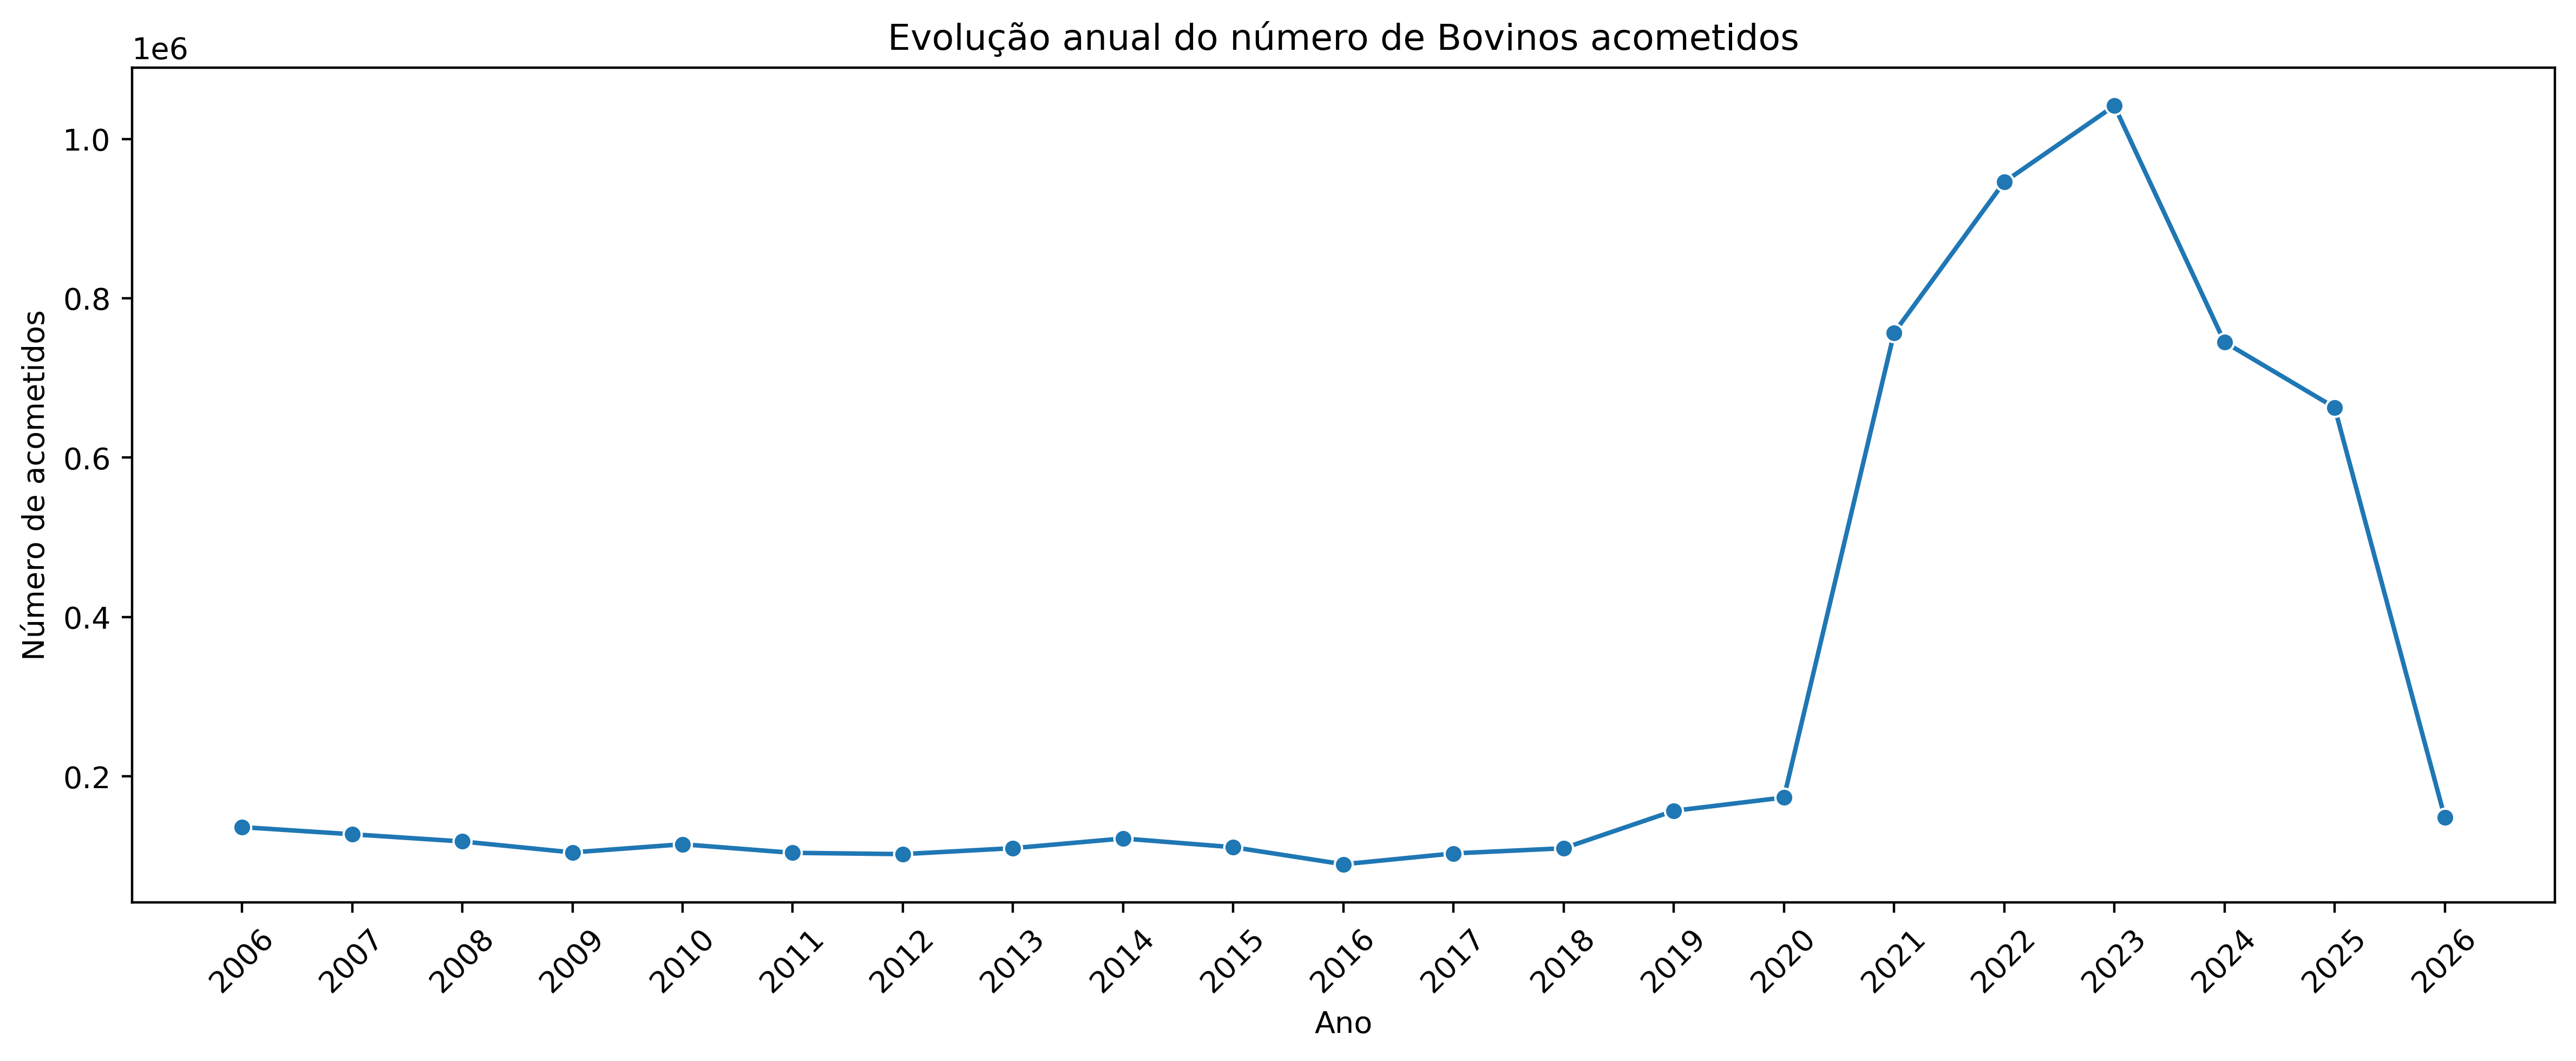

In [230]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_estat_bovino_sudeste_ano.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(serie_anual["ANO"].dropna().astype(int), rotation=45)
pl.tight_layout()
pl.show()

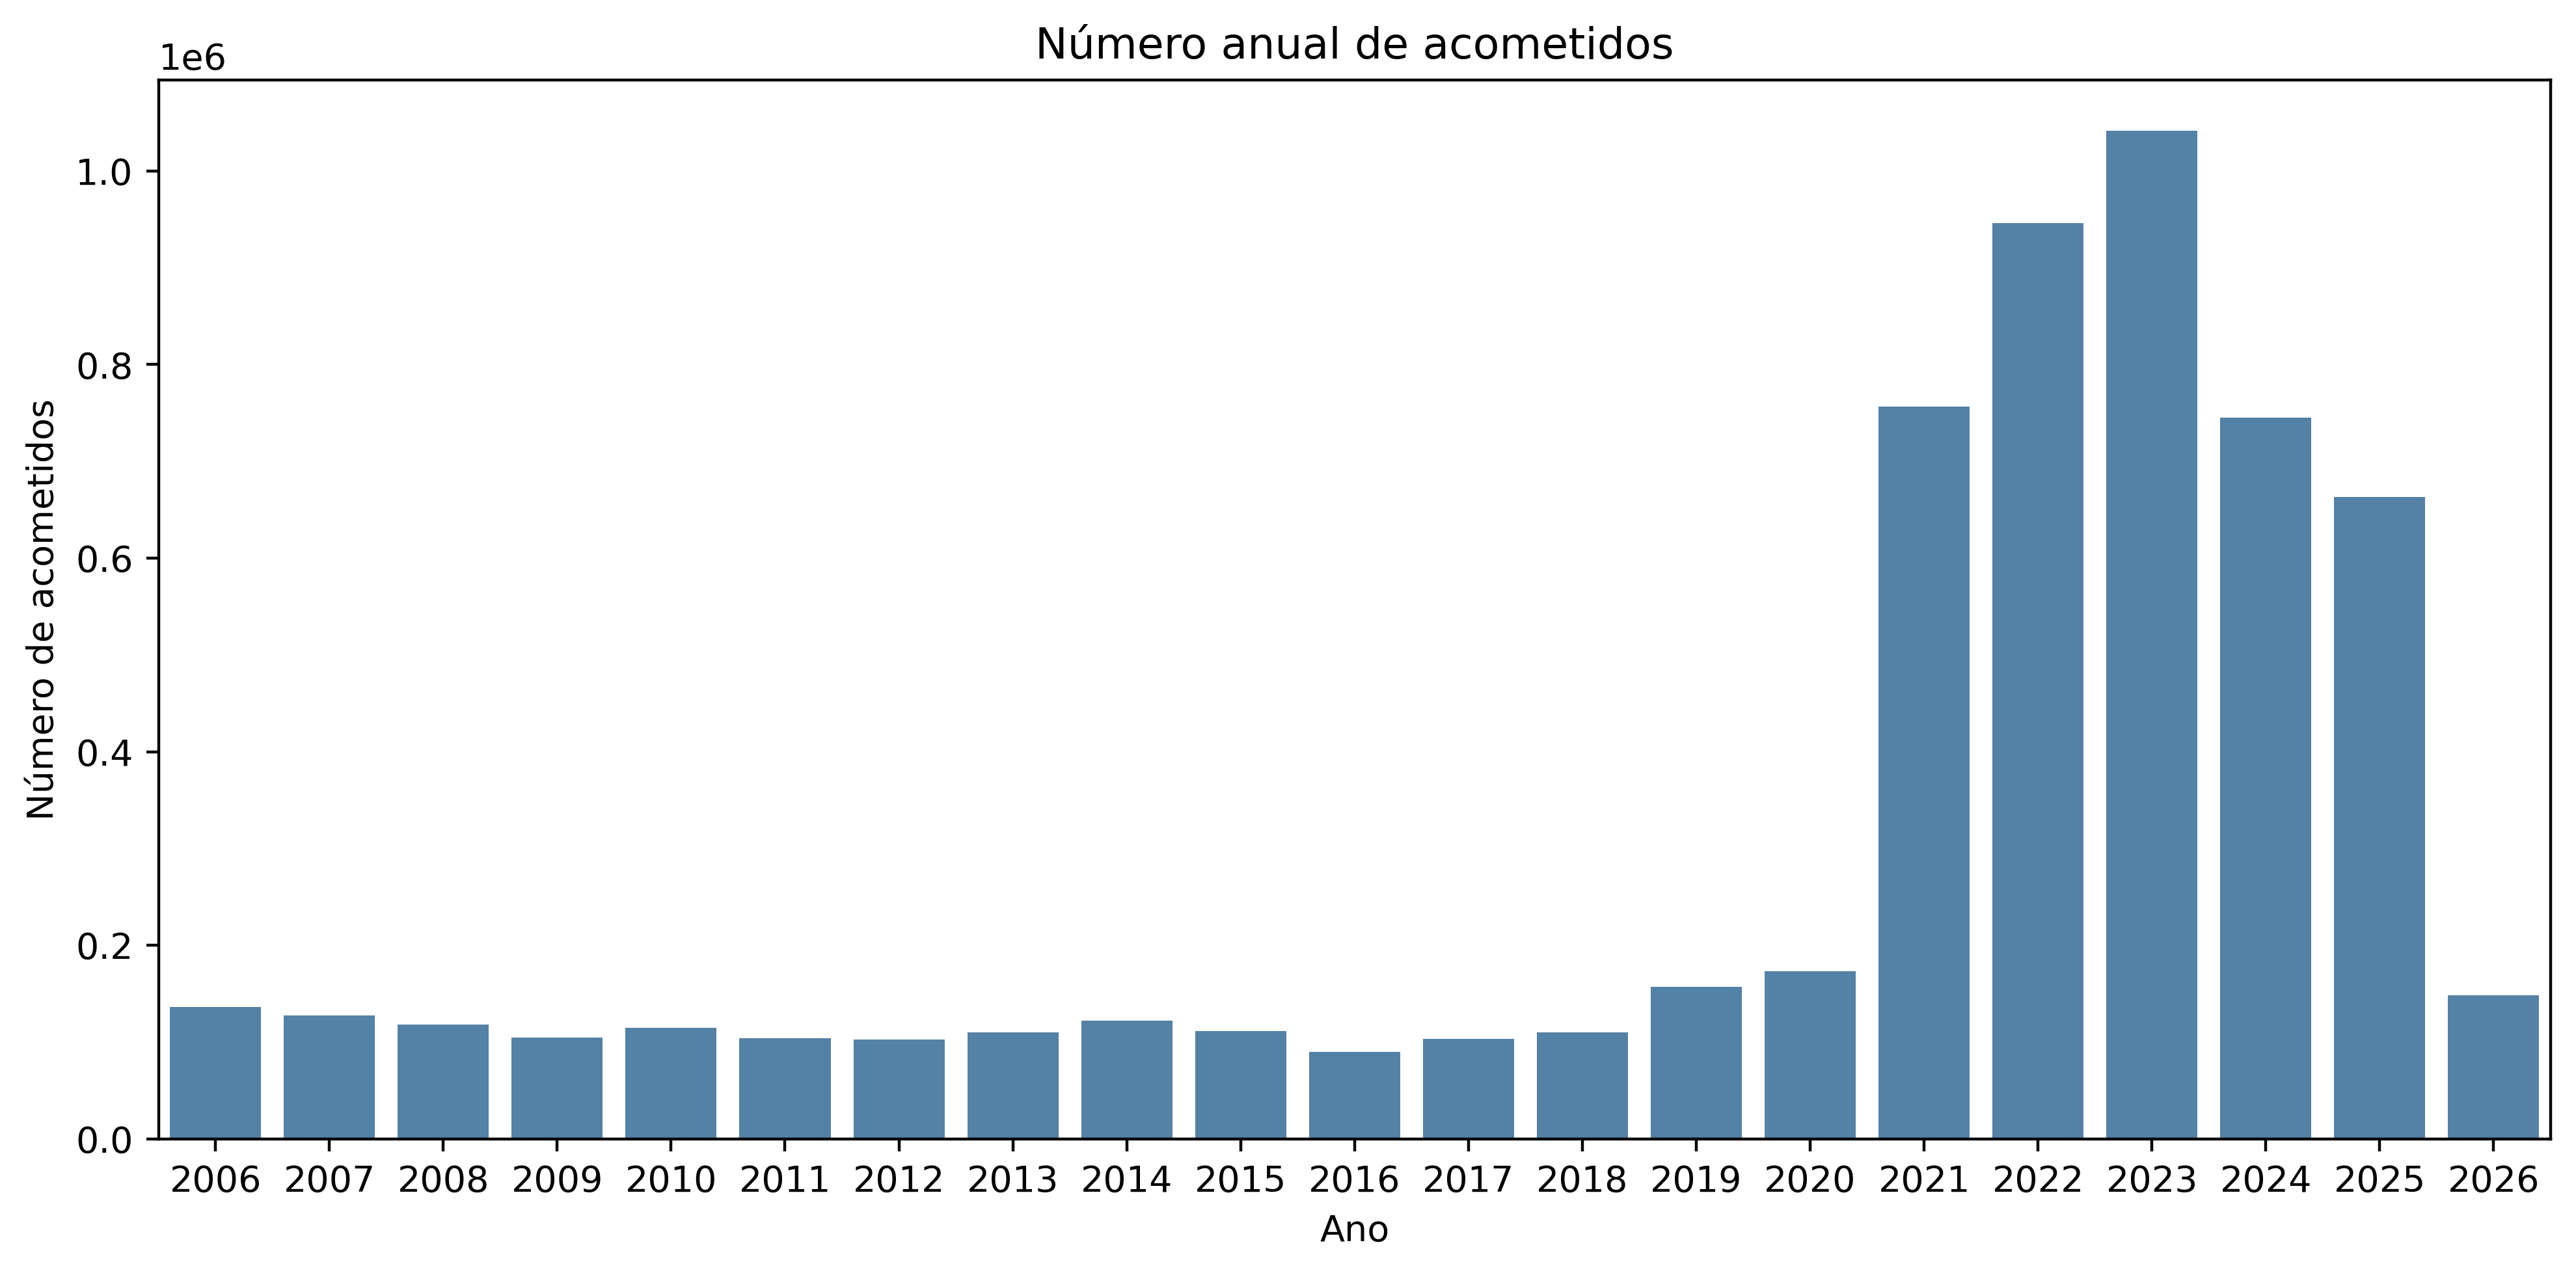

In [231]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_sudeste_ano.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

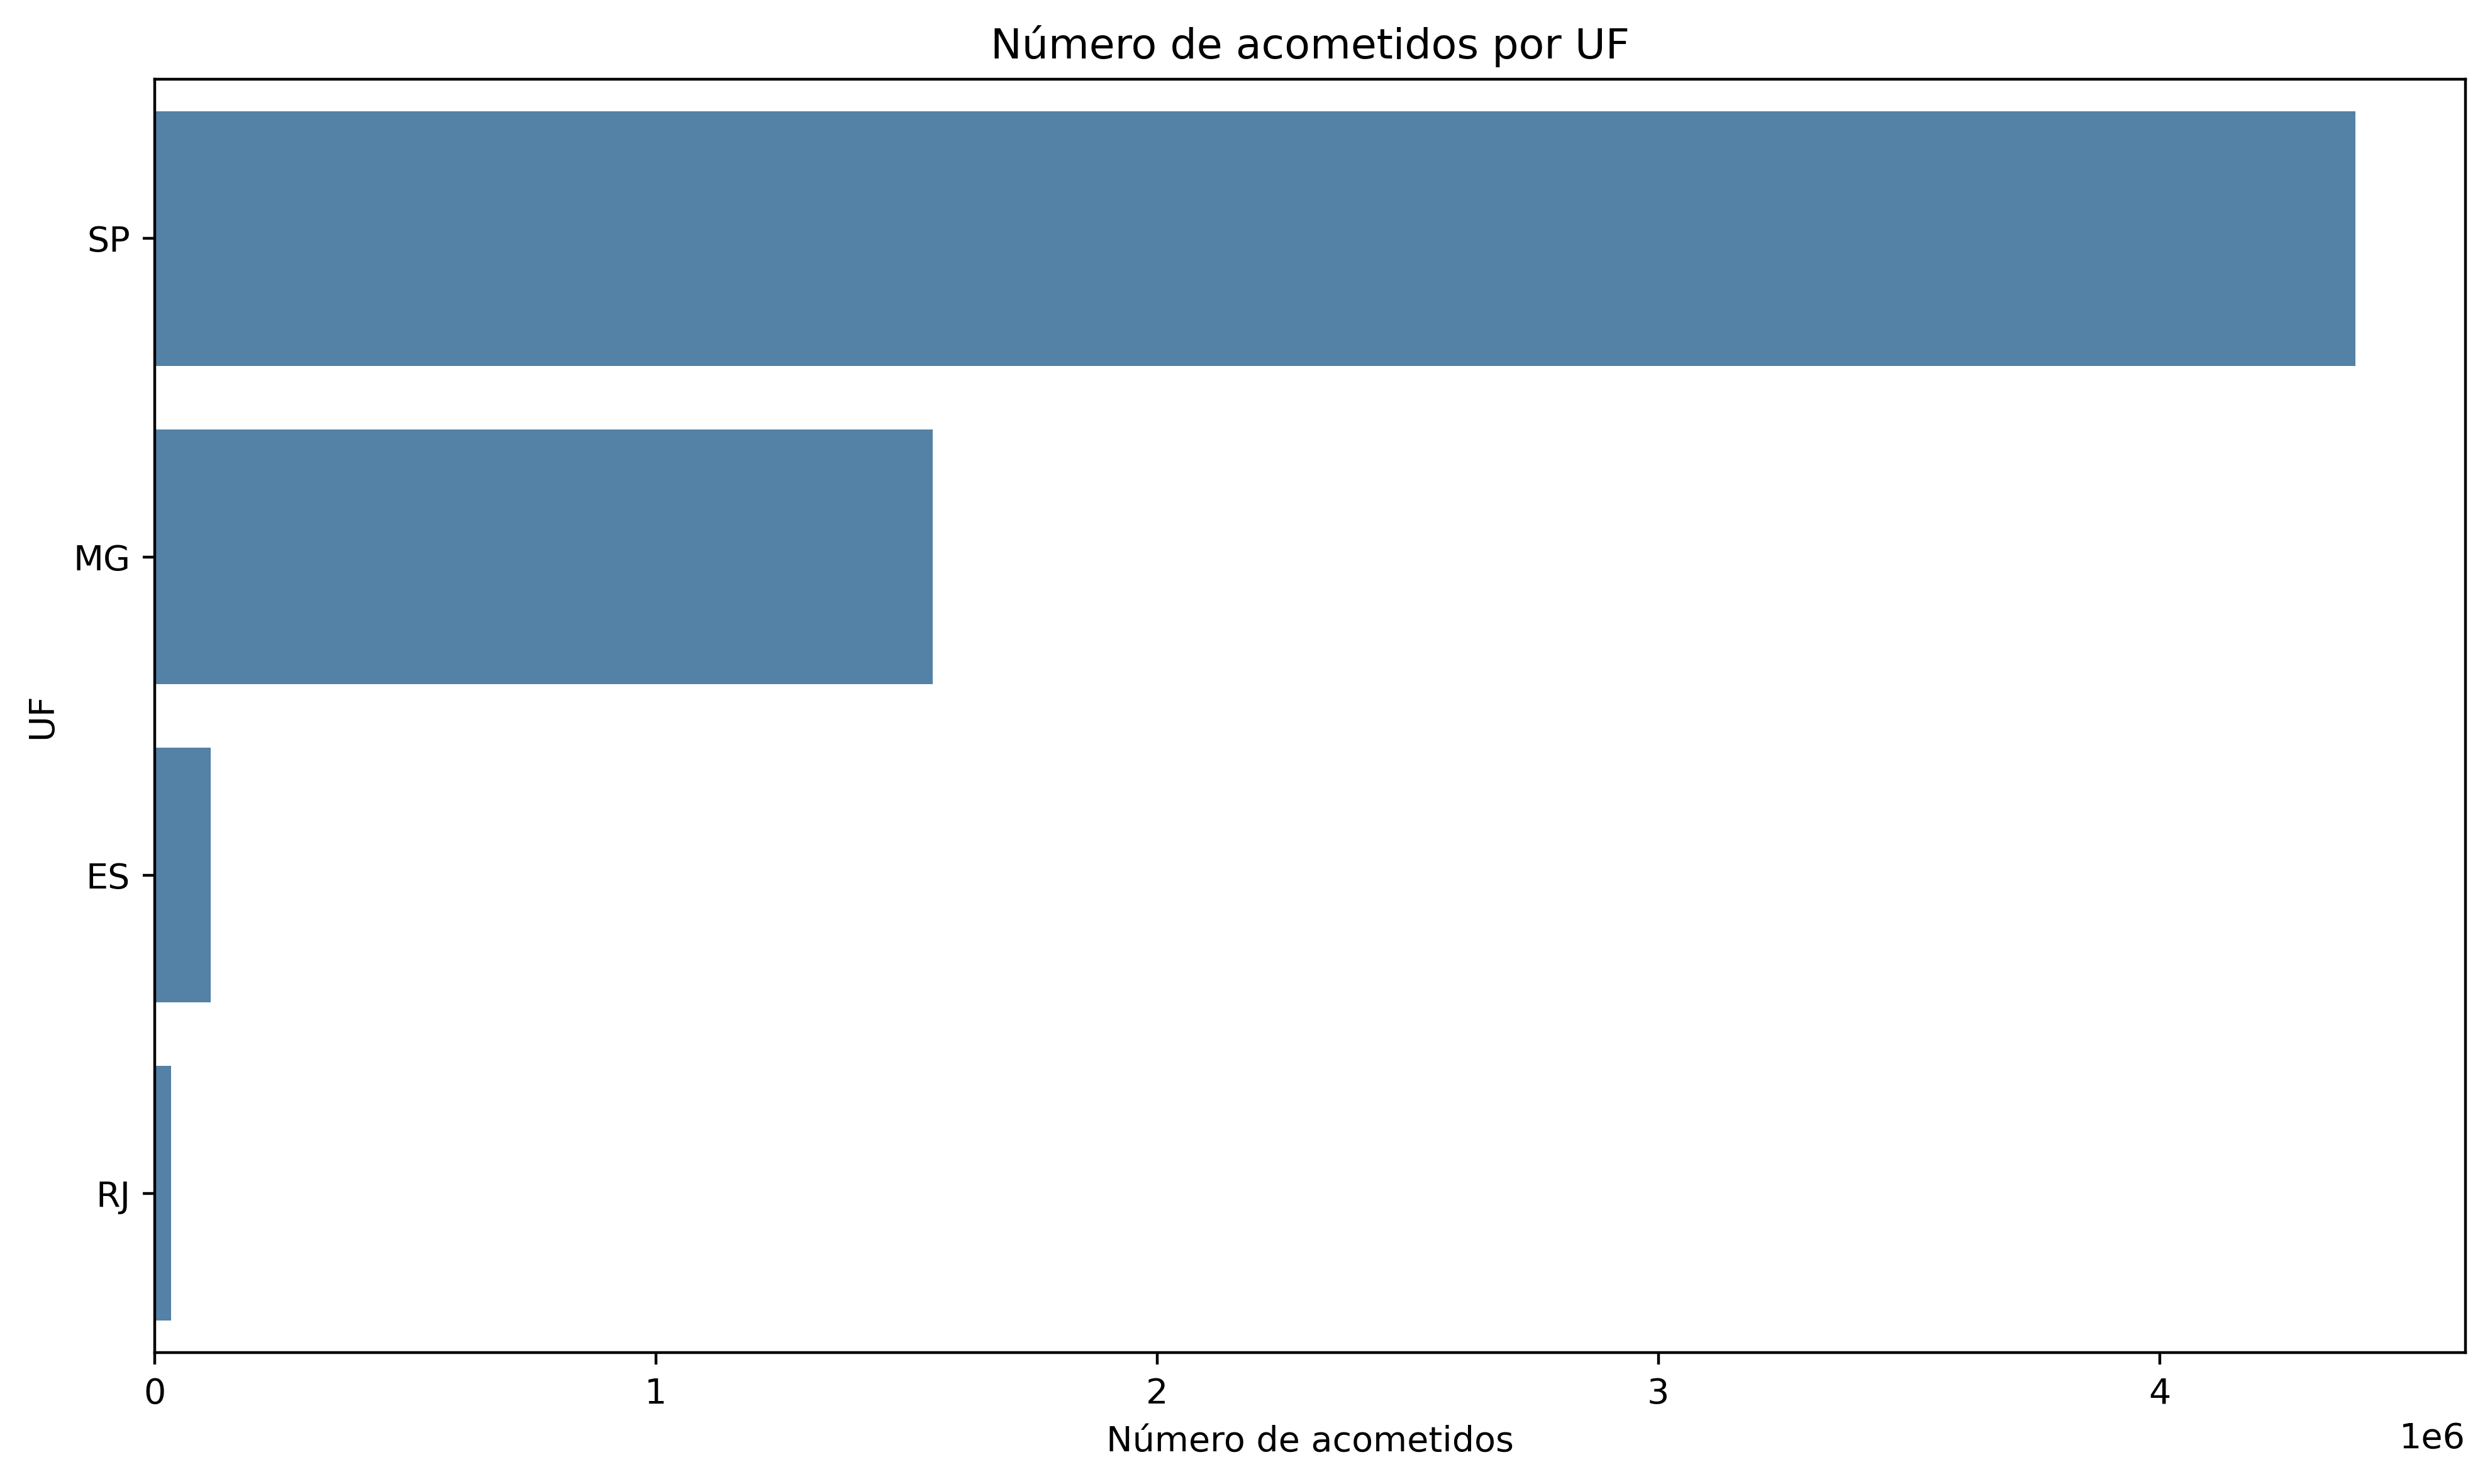

In [232]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_sudeste_ano.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [233]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_estat_bovino_sudeste_ano,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_diagnostico

DIAGNOSTICO,aborto enzoótico das ovelhas (confirmado),aborto recente (fêmea),abscesso,abscesso (mamífero),abscesso (mamíferos),acidez,acrobustite,actinobacilose (ruminantes),actinomicose (já notificado),actinomicose (notificação sif),...,tuberculose (reagente já notificado),tuberculose (reagente notificação sif),tuberculose aviária (notificação sif),tuberculose calcificada,tuberculose caseosa,tuberculose miliar,uronefrose,verminose,visceras hemorragicas,útero com feto(s)
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
ES,0,0,57,0,980,0,0,7,2,7,...,0,0,0,223,537,0,0,0,0,0
MG,2,15,13722,80,4355,0,22,447,16,1691,...,21,12,2,160,1020,1278,56,61,0,5
RJ,0,0,0,0,238,0,0,3,0,0,...,0,0,0,0,0,0,0,0,0,0
SP,39,3,63104,1859,13615,3,73,22,24,79,...,0,1,0,28851,18714,706,18,0,1,6


In [234]:
#Analisando o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_sudeste_ano.groupby("UF_PROCEDENCIA", as_index=False)
        ["NUMERO_ANIMAIS_ACOMETIDOS"].sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
3,SP,4390649
1,MG,1552418
0,ES,111110
2,RJ,32112


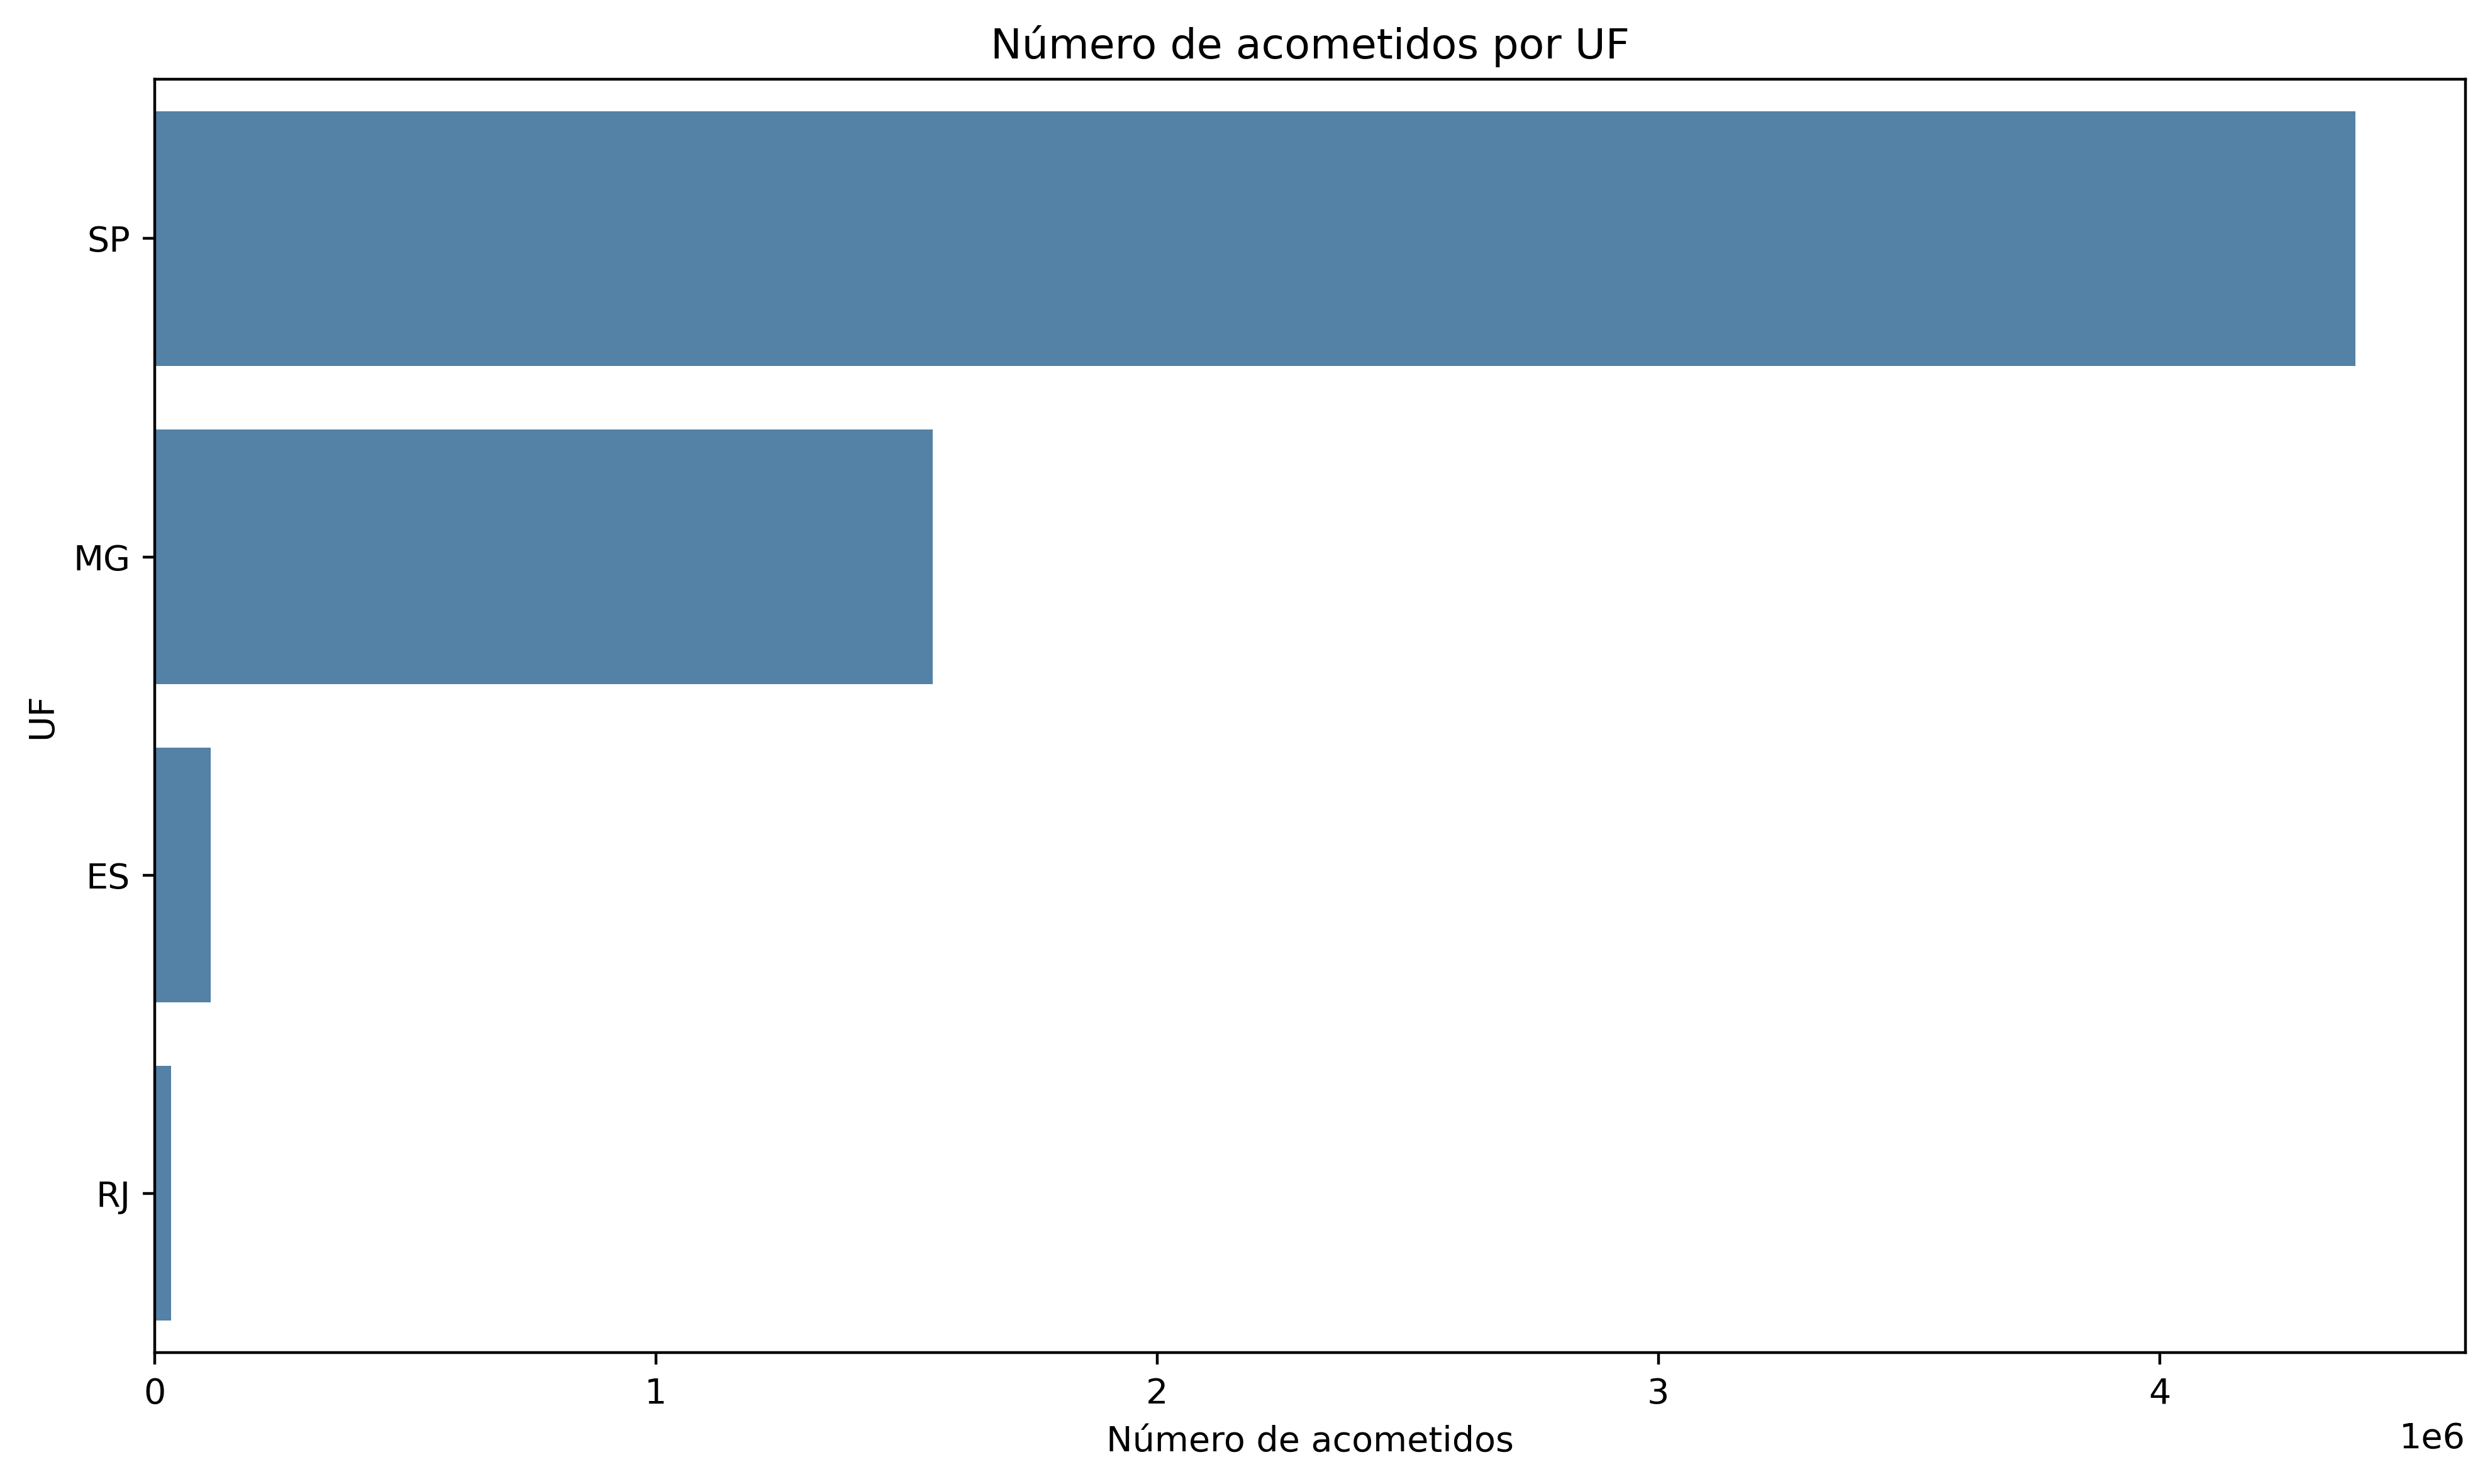

In [235]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [236]:
ranking_uf["percentual"] = (
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,4390649,72.140002
1,MG,1552418,25.506807
0,ES,111110,1.825579
2,RJ,32112,0.527612


In [237]:
ranking_diagnostico = (
    df_estat_bovino_sudeste_ano.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
173,material especificado de risco (inutilização),2718449
21,alteração restrita,651390
84,contaminação gastrointestinal e biliar,603017
71,cisticercose calcificada,546086
83,contaminacao,358031
...,...,...
228,raiva,1
96,encefalomielite enzootica,1
119,febre q (notificação sif),1
59,carbunculo sintomatico,1


In [238]:
ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
173,material especificado de risco (inutilização),2718449,44.665132
21,alteração restrita,651390,10.702581
84,contaminação gastrointestinal e biliar,603017,9.907794
71,cisticercose calcificada,546086,8.972397
83,contaminacao,358031,5.882583
...,...,...,...
228,raiva,1,0.000016
96,encefalomielite enzootica,1,0.000016
119,febre q (notificação sif),1,0.000016
59,carbunculo sintomatico,1,0.000016


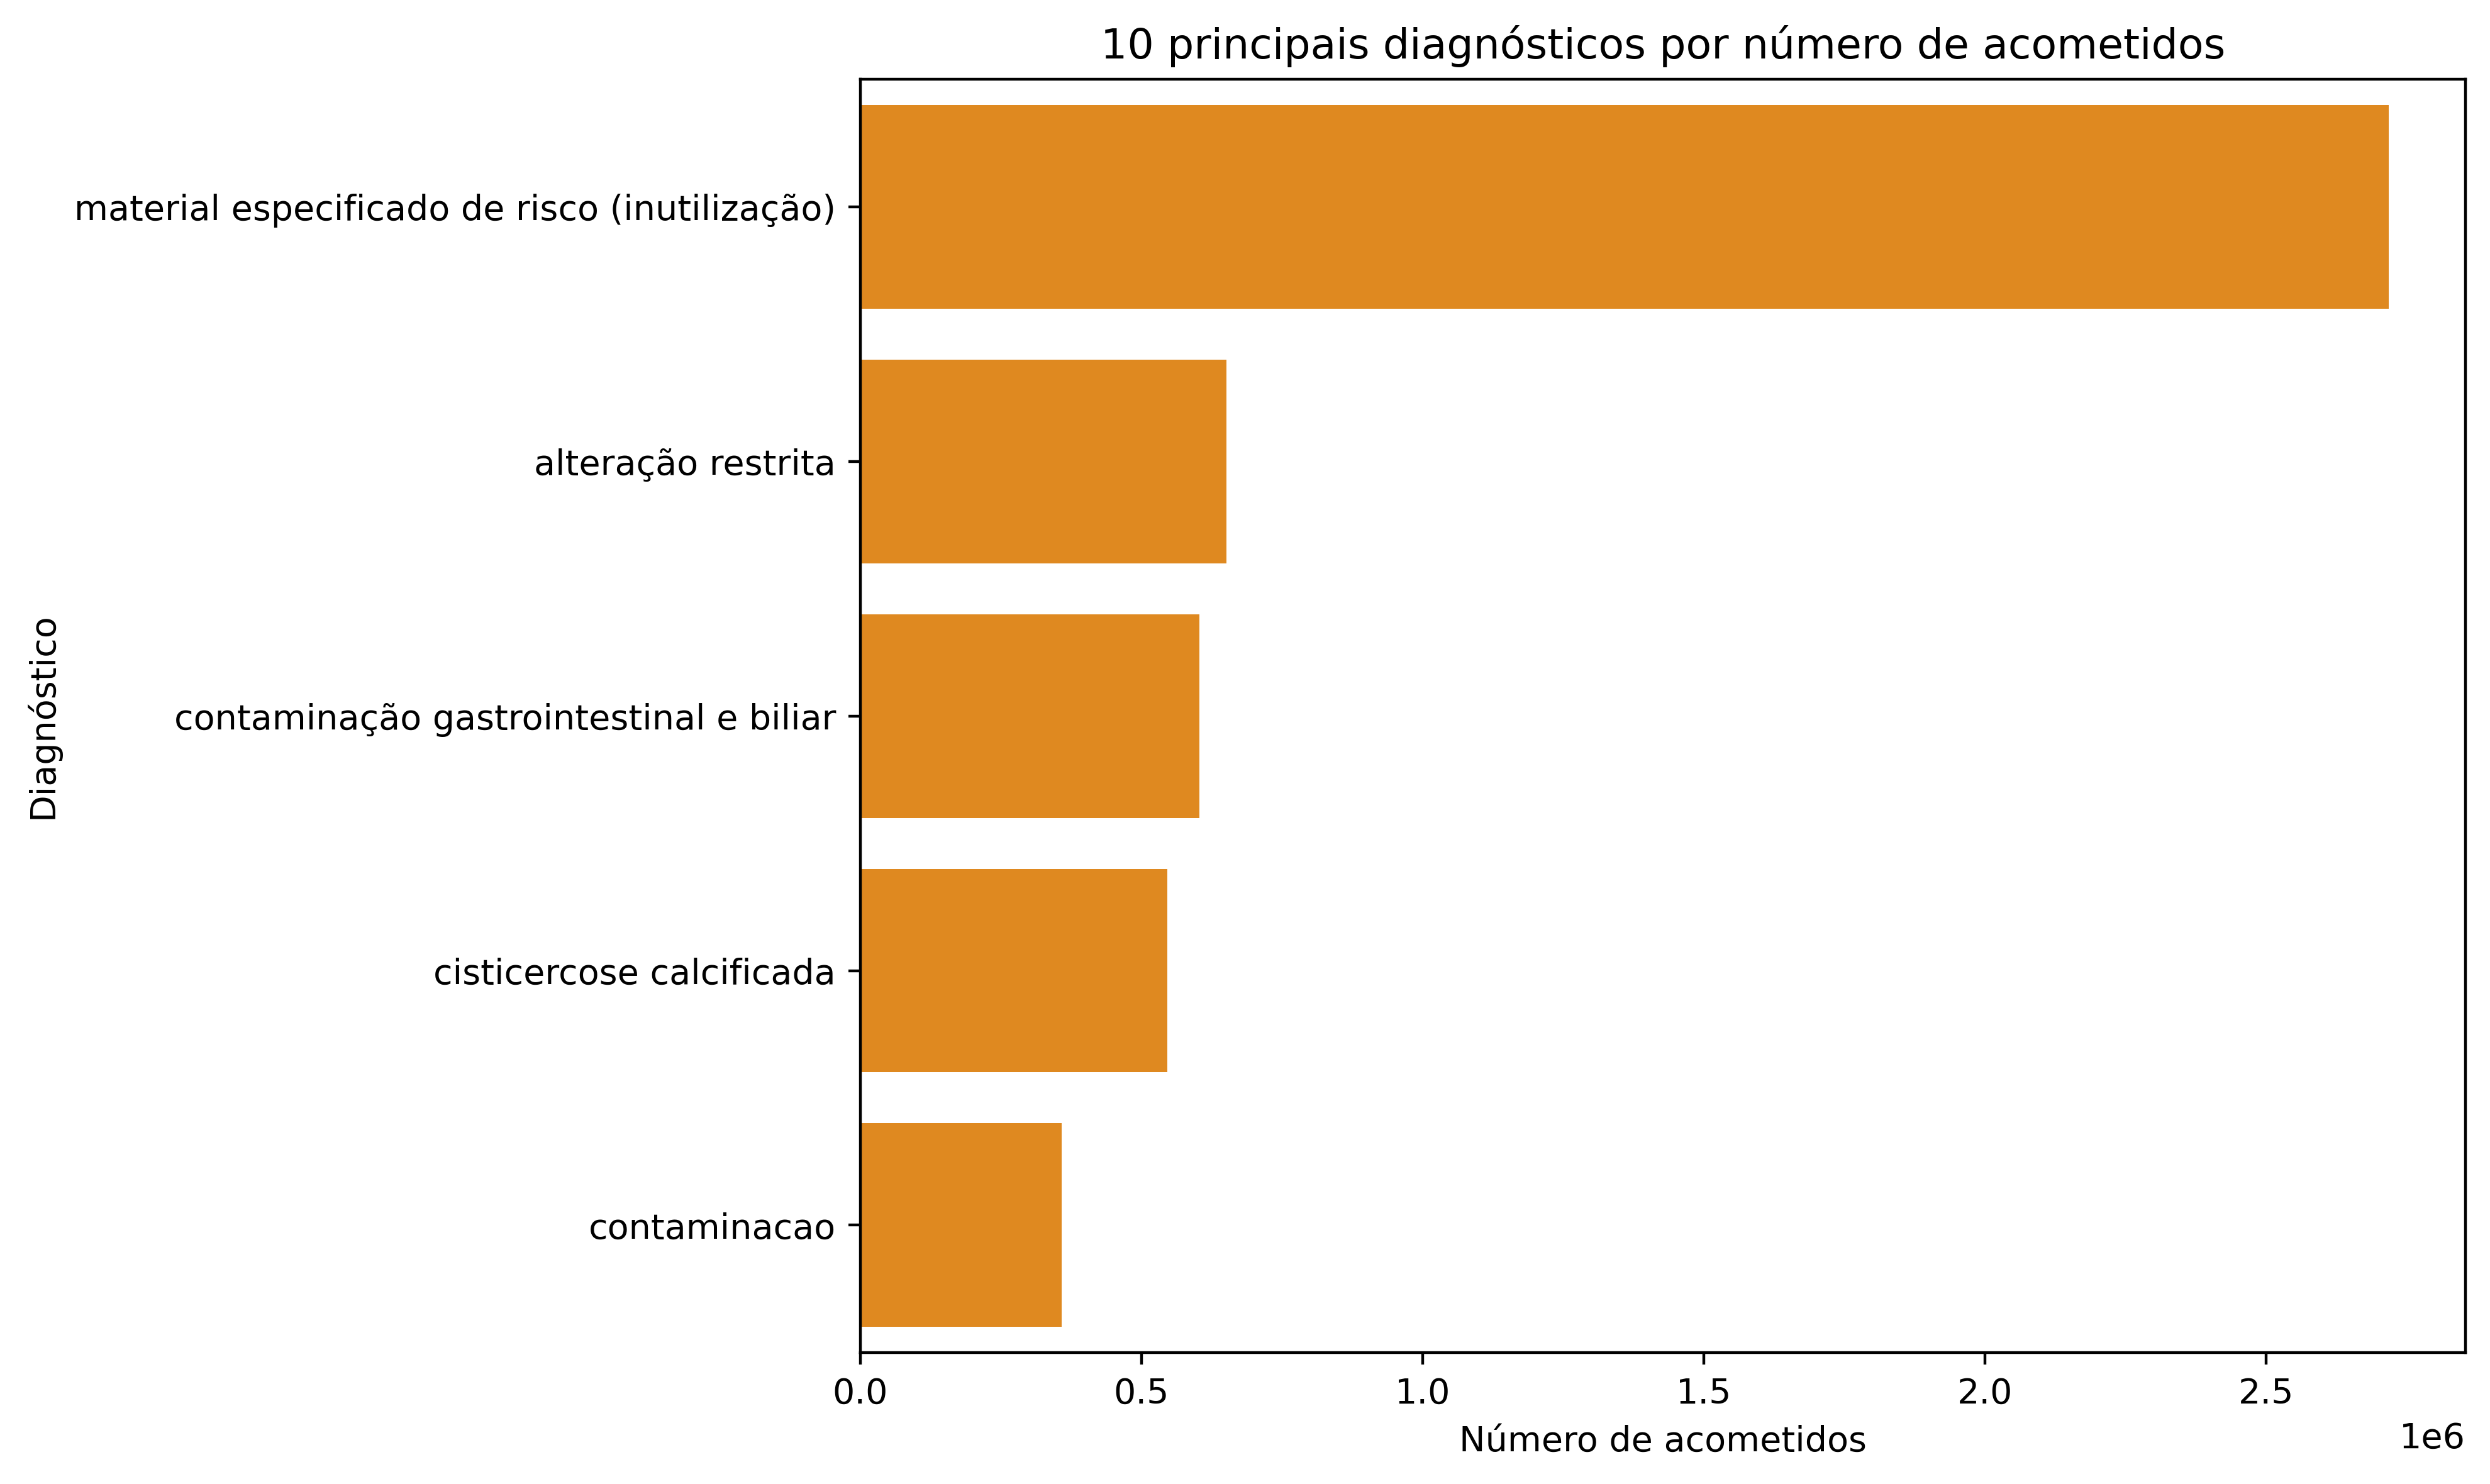

In [239]:
top10_diagnostico = ranking_diagnostico.head(5)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [240]:
diagnostico_ano = (
    df_estat_bovino_sudeste_ano.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
19,2006,cisticercose calcificada,72951
20,2006,cisticercose viva,31531
24,2006,contaminacao,7812
25,2006,contusão,7121
18,2006,cisticercose,4525
...,...,...,...
1556,2026,hipotermia (detectada no ante mortem),2
1546,2026,edema generalizado,1
1552,2026,febre q (notificação sif),1
1555,2026,gordura amarela,1


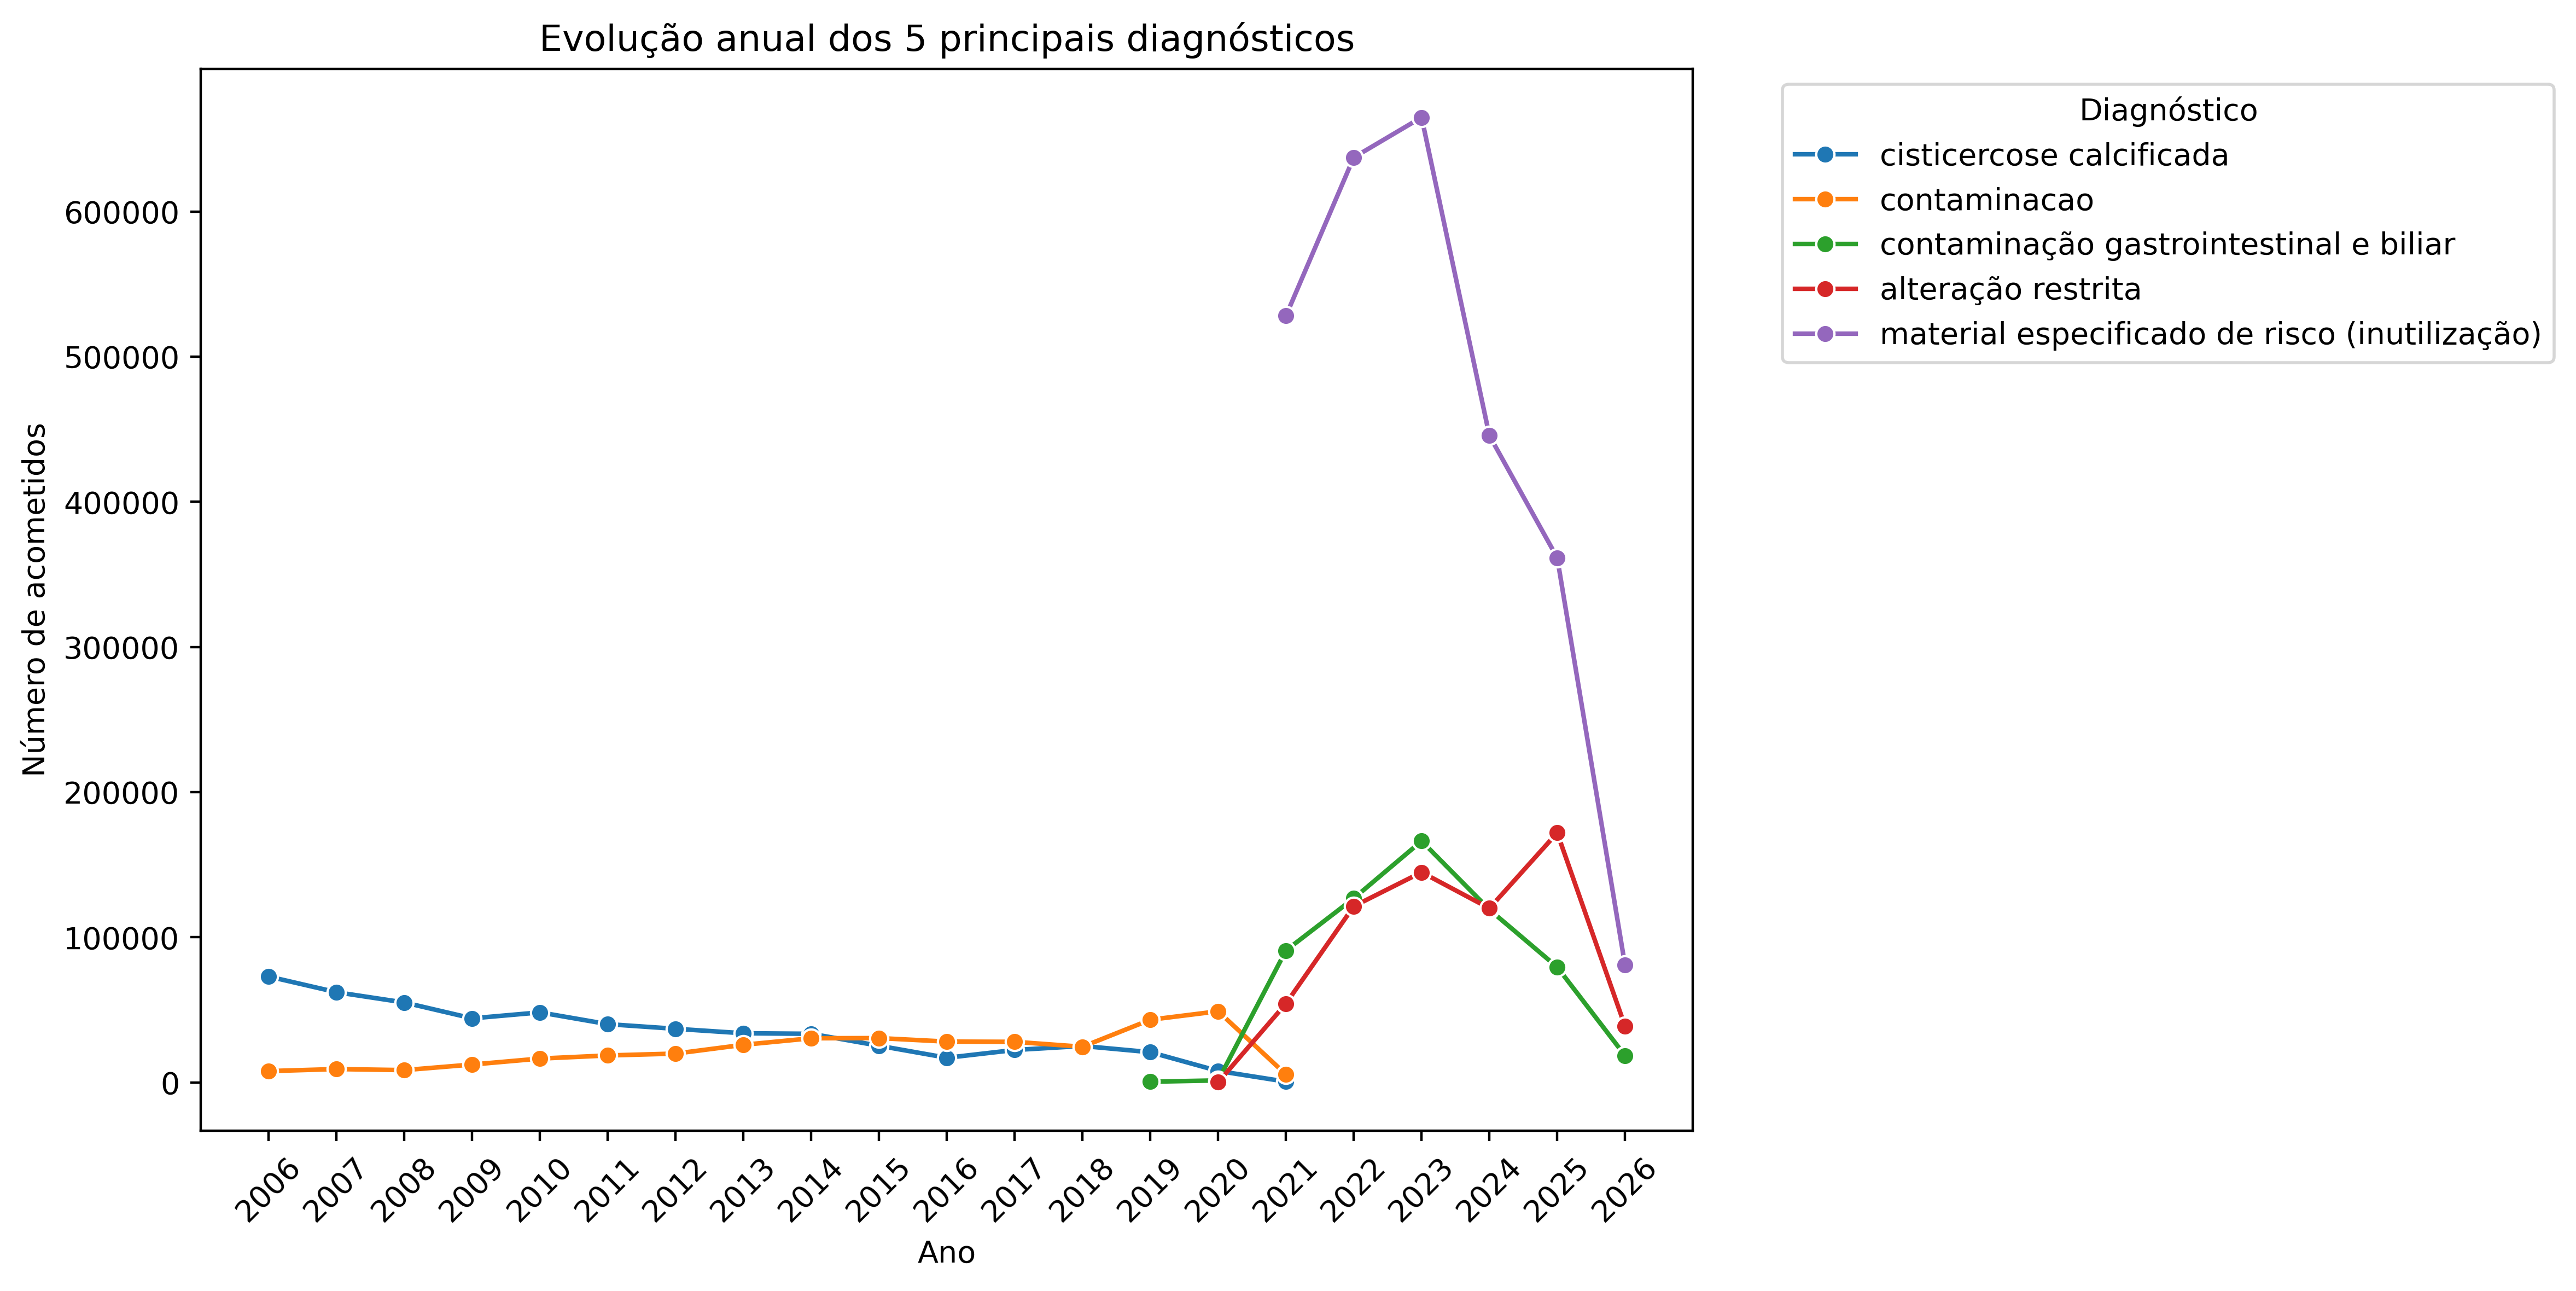

In [249]:
top5_diag = (
    df_estat_bovino_sudeste_ano.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5 = diagnostico_ano[
    diagnostico_ano["DIAGNOSTICO"].isin(top5_diag)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5["ANO"].unique()), serie_anual["ANO"].dropna().astype(int),rotation=45)
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [250]:
media = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 343.82
Mediana: 9.00
Desvio Padrão: 2131.13
Variância: 4541726.54
Coeficiente de Variação: 619.84%


In [251]:
assimetria = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 12.09
Curtose: 170.41


In [252]:
minimo = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 45077
Amplitude: 45076
Q1: 2.0
Q3: 70.0
IQR: 68.0


In [253]:
q1 = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_sudeste_ano[
    (df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_estat_bovino_sudeste_ano["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
        MES_ANO UF_PROCEDENCIA ESPECIE  \
0    2021-12-01             SP  Bovino   
1    2023-09-01             SP  Bovino   
2    2021-08-01             SP  Bovino   
3    2023-08-01             SP  Bovino   
4    2022-09-01             SP  Bovino   
...         ...            ...     ...   
3025 2016-01-01             MG  Bovino   
3026 2022-12-01             SP  Bovino   
3027 2018-07-01             MG  Bovino   
3028 2020-05-01             MG  Bovino   
3029 2007-09-01             SP  Bovino   

                                        DIAGNOSTICO  \
0     material especificado de risco (inutilização)   
1     material especificado de risco (inutilização)   
2     material especificado de risco (inutilização)   
3     material especificado de risco (inutilização)   
4     material especificado de risco (inutilização)   
...                                             ...   
3025                       cisticercose calcificada   
3026                     euritrem

In [254]:
desc_por_uf = (
      df_estat_bovino_sudeste_ano.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,7588,4390649,578.630601,16.0,2860.726967,1,45077
MG,7768,1552418,199.847837,5.0,1500.170533,1,30669
ES,1804,111110,61.590909,10.0,169.759466,1,1667
RJ,542,32112,59.247232,10.0,88.809240,1,455


In [255]:
desc_por_diagnostico = (
    df_estat_bovino_sudeste_ano.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
material especificado de risco (inutilização),248,2718449,10961.487903,1836.0,12803.251065,1,45077
alteração restrita,259,651390,2515.019305,695.0,3638.906104,1,14992
contaminação gastrointestinal e biliar,277,603017,2176.956679,642.0,2919.884544,1,12259
cisticercose calcificada,544,546086,1003.834559,149.5,1549.490998,1,7170
contaminacao,404,358031,886.215347,475.5,992.654136,1,5784
...,...,...,...,...,...,...,...
raiva,1,1,1.000000,1.0,NaN,1,1
encefalomielite enzootica,1,1,1.000000,1.0,NaN,1,1
febre q (notificação sif),1,1,1.000000,1.0,NaN,1,1


In [256]:
ranking_diagnostico = (
    df_estat_bovino_sudeste_ano.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico["percentual_acumulado"] = ranking_diagnostico["percentual"].cumsum()

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
173,material especificado de risco (inutilização),2718449,44.665132,44.665132
21,alteração restrita,651390,10.702581,55.367713
84,contaminação gastrointestinal e biliar,603017,9.907794,65.275507
71,cisticercose calcificada,546086,8.972397,74.247904
83,contaminacao,358031,5.882583,80.130487
...,...,...,...,...
228,raiva,1,0.000016,99.999934
96,encefalomielite enzootica,1,0.000016,99.999951
119,febre q (notificação sif),1,0.000016,99.999967
59,carbunculo sintomatico,1,0.000016,99.999984


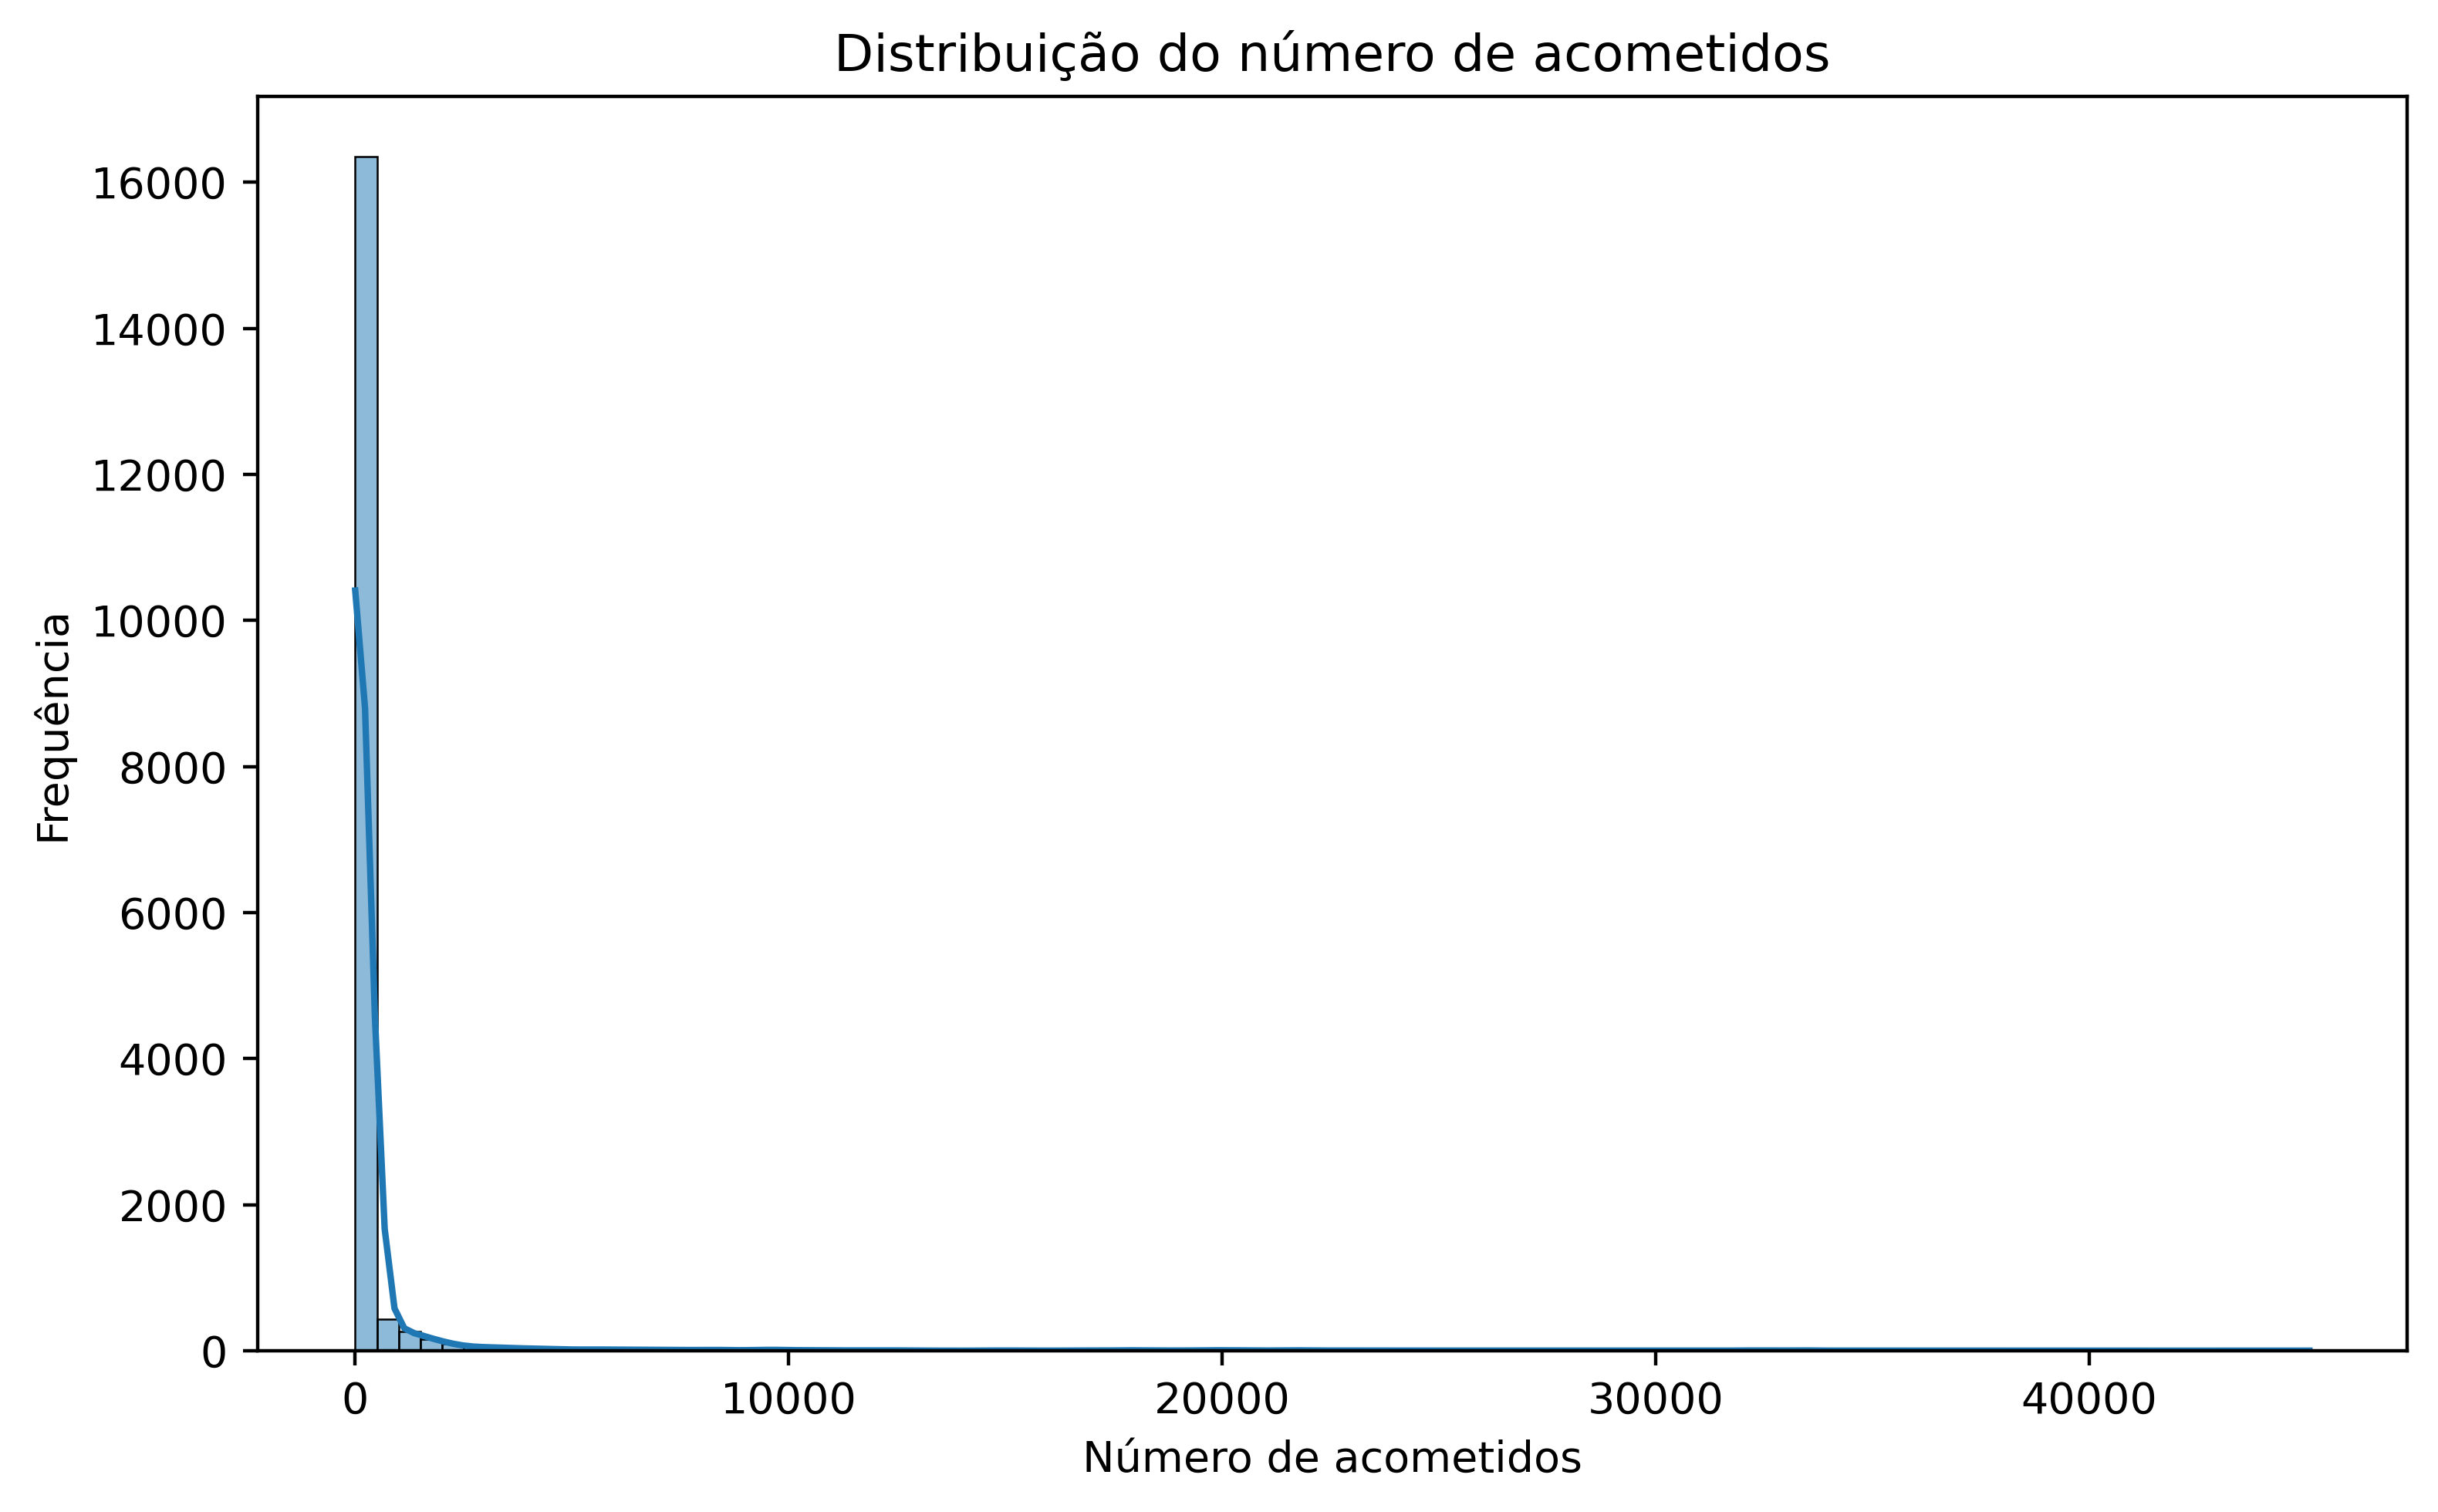

In [257]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_sudeste_ano,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins= 90,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


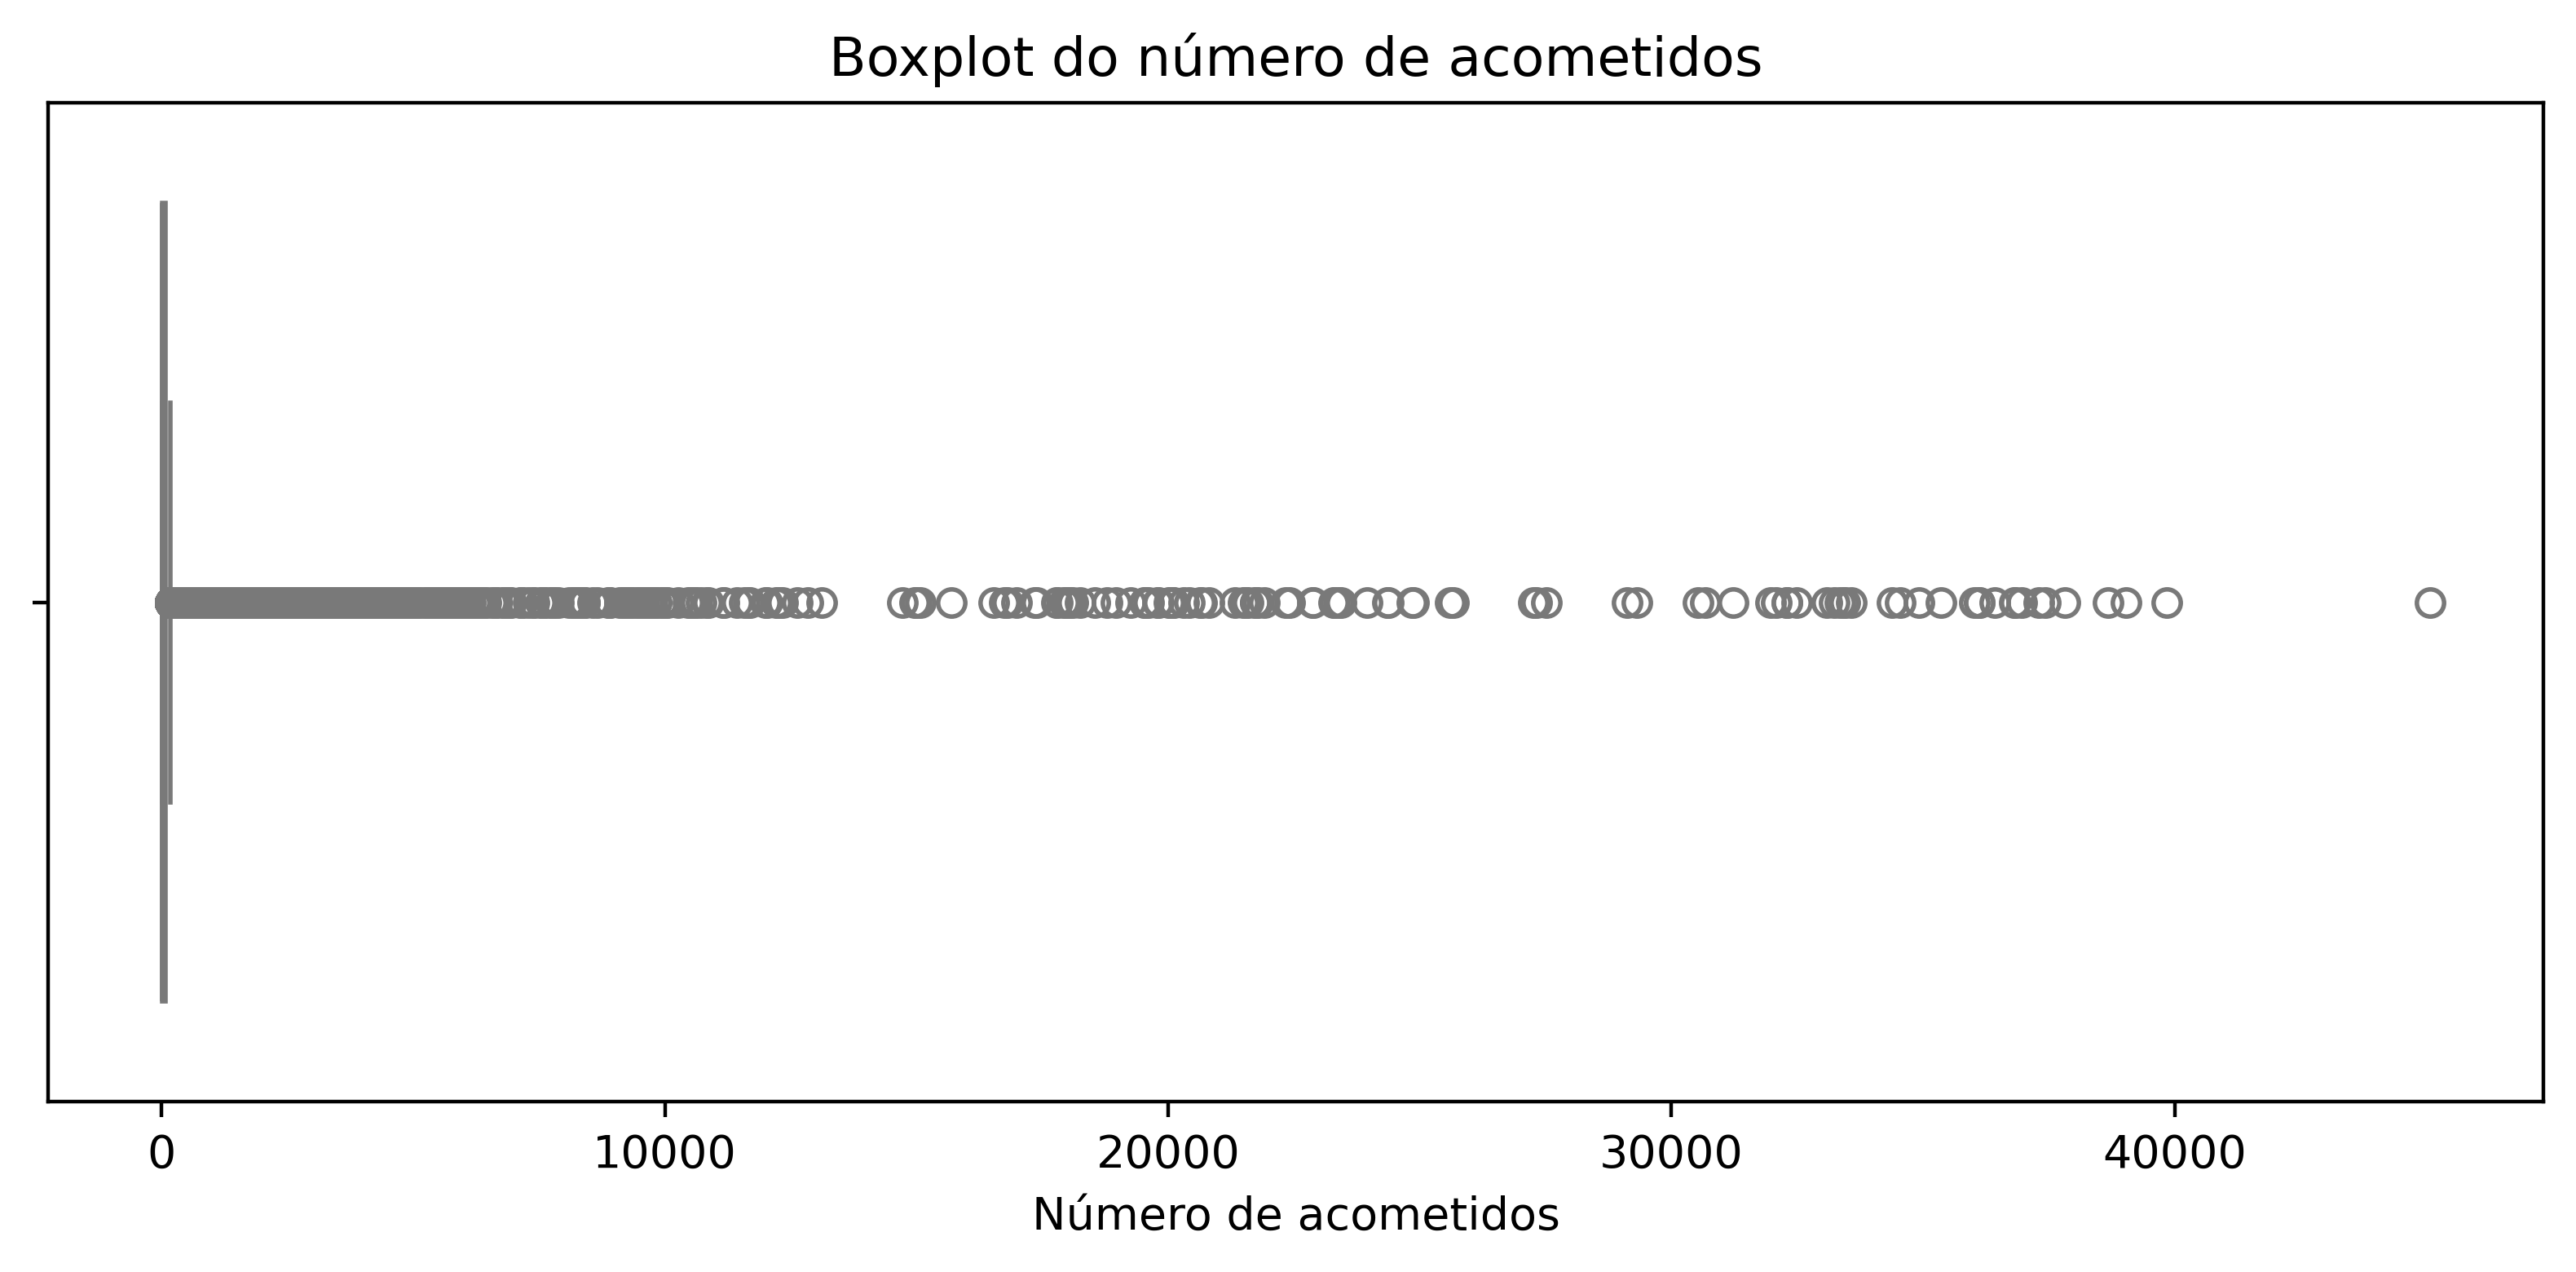

In [258]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_sudeste_ano,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()

Estatística bovinos doenças infecciosas

In [136]:
df_estat_bovino_se_infecto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5684 entries, 0 to 5683
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    5684 non-null   object
 1   UF_PROCEDENCIA             5684 non-null   object
 2   ESPECIE                    5684 non-null   object
 3   DIAGNOSTICO                5684 non-null   object
 4   NUMERO_ANIMAIS_ACOMETIDOS  5684 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 222.2+ KB


In [137]:
df_estat_bovino_se_infecto.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,5684.000000
mean,60.574068
std,154.849080
min,1.000000
25%,2.000000
50%,8.000000
75%,50.000000
max,1872.000000


In [138]:
#adequando o formato da coluna de data para extrair o ano
df_estat_bovino_se_infecto["MES_ANO"] = pd.to_datetime(df_estat_bovino_se_infecto["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_se_infecto["ANO"] = df_estat_bovino_se_infecto["MES_ANO"].dt.year
print(df_estat_bovino_se_infecto.head(10))

     MES_ANO UF_PROCEDENCIA ESPECIE DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0 2021-01-01             SP  Bovino   bronquite                       1872   
1 2019-09-01             SP  Bovino   bronquite                       1822   
2 2020-04-01             SP  Bovino   bronquite                       1554   
3 2019-07-01             SP  Bovino   bronquite                       1537   
4 2020-06-01             SP  Bovino   bronquite                       1505   
5 2020-10-01             SP  Bovino   bronquite                       1492   
6 2020-12-01             SP  Bovino   bronquite                       1489   
7 2019-08-01             SP  Bovino   bronquite                       1477   
8 2020-01-01             SP  Bovino   bronquite                       1452   
9 2019-11-01             SP  Bovino   bronquite                       1444   

    ANO  
0  2021  
1  2019  
2  2020  
3  2019  
4  2020  
5  2020  
6  2020  
7  2019  
8  2020  
9  2019  


In [139]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_estat_bovino_se_infecto.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
18,2019,38322,11.130313
17,2018,30359,8.817524
19,2020,27937,8.114074
16,2017,26410,7.670569
14,2015,22022,6.396110
15,2016,21417,6.220393
13,2014,20655,5.999076
12,2013,16361,4.751919
9,2010,15929,4.626448
8,2009,15245,4.427786



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,285872,83.029192
1,MG,55551,16.134335
0,ES,2611,0.758344
2,RJ,269,0.078129



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
6,adenite,89891,26.108108
0,abscesso,76956,22.351243
55,tuberculose calcificada,35395,10.280189
9,bronquite,34596,10.048126
56,tuberculose caseosa,24886,7.227936
1,abscesso (mamíferos),19188,5.572998
27,linfadenite,18789,5.457112
49,tuberculose,15565,4.520727
40,pneumonia,13709,3.981667
24,lesões tuberculósicas,3108,0.902693


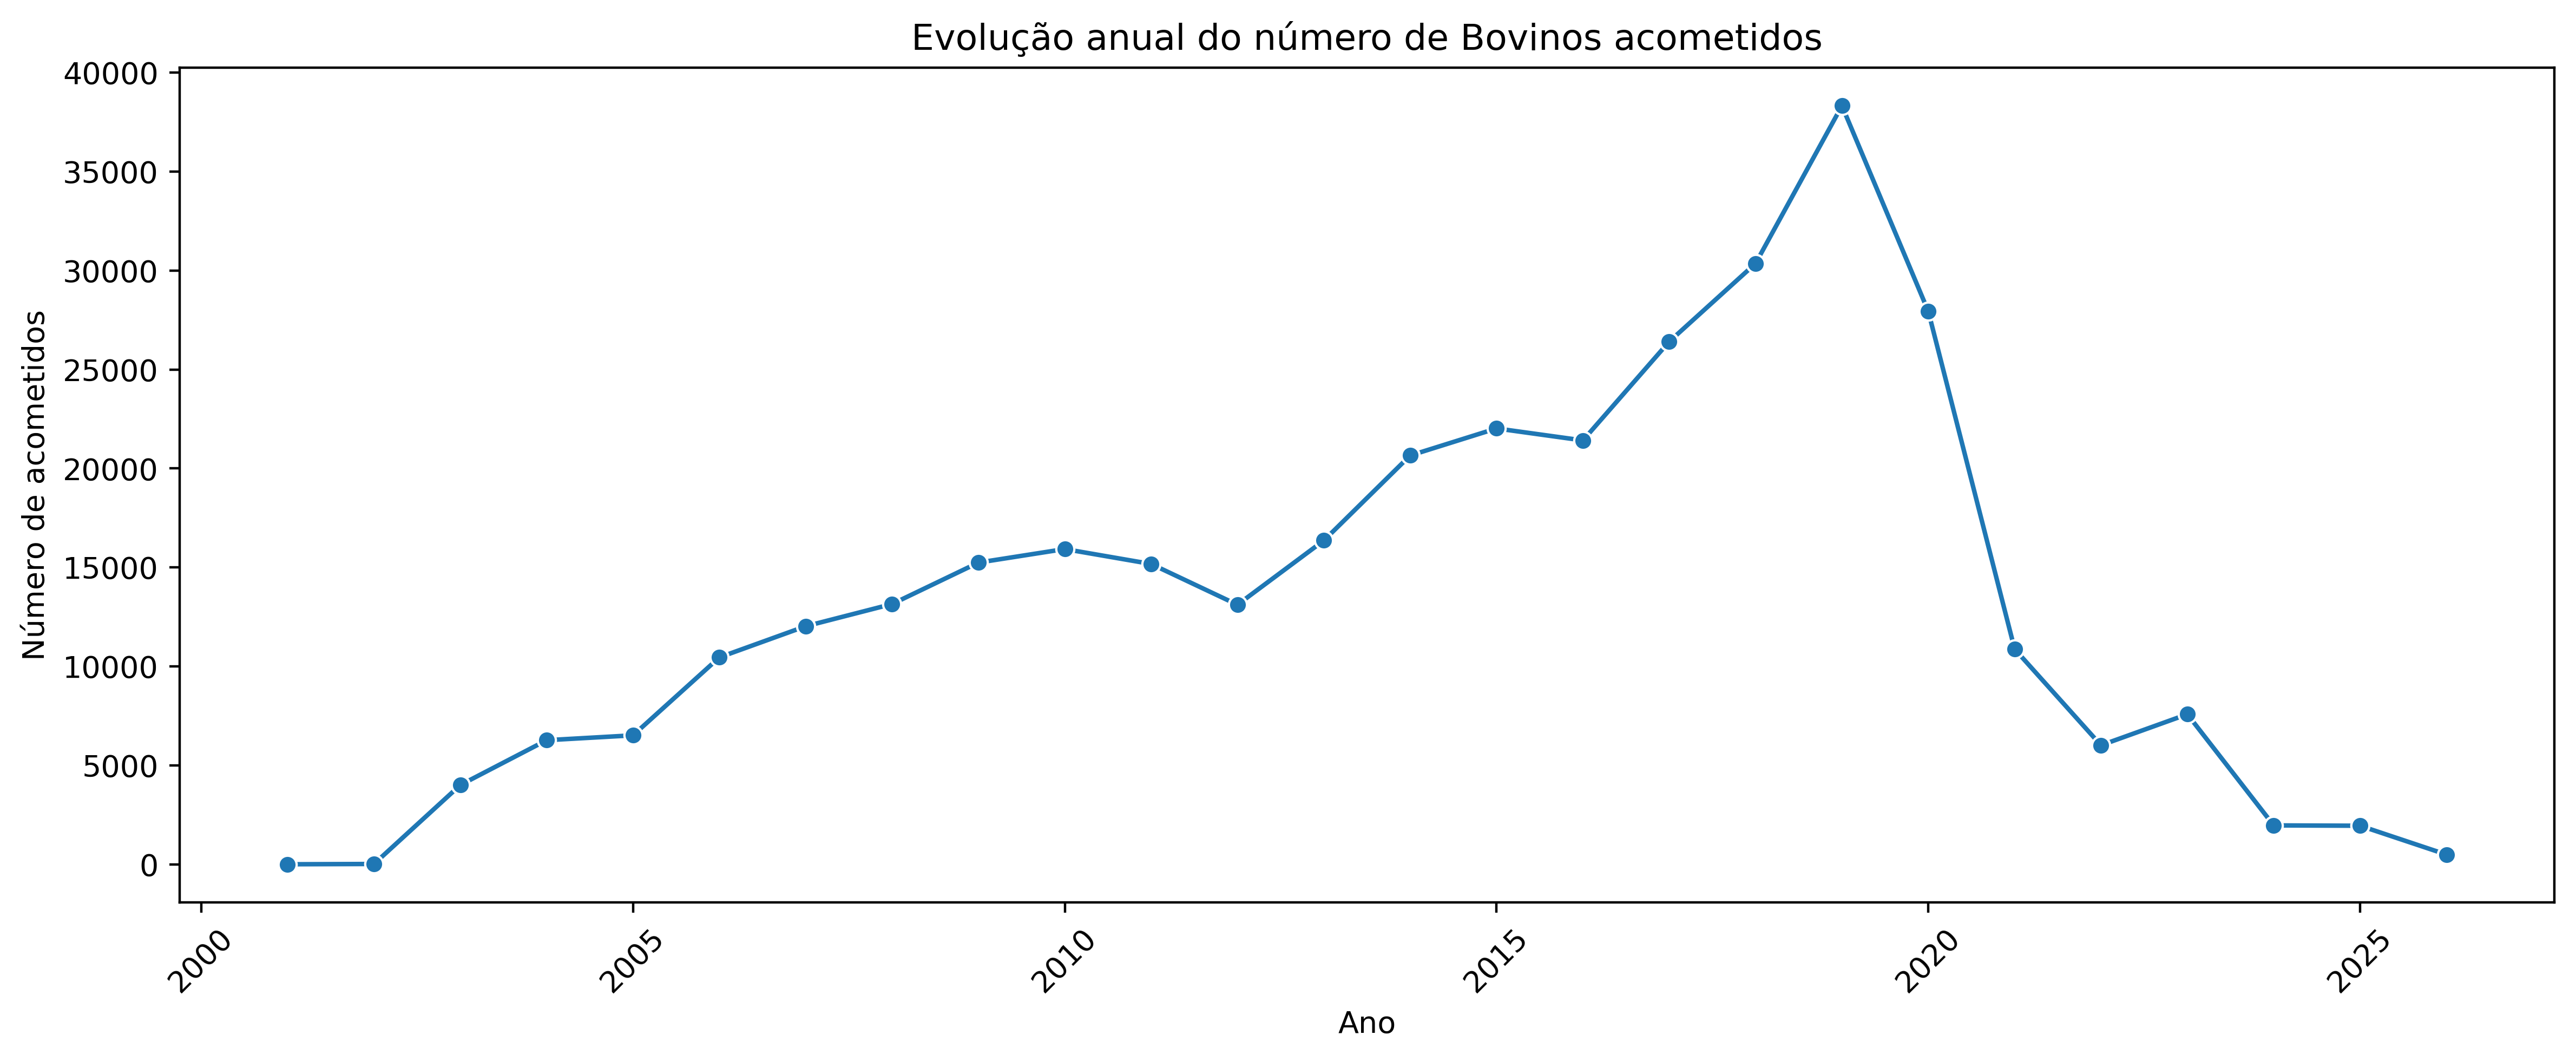

In [140]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_estat_bovino_se_infecto.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

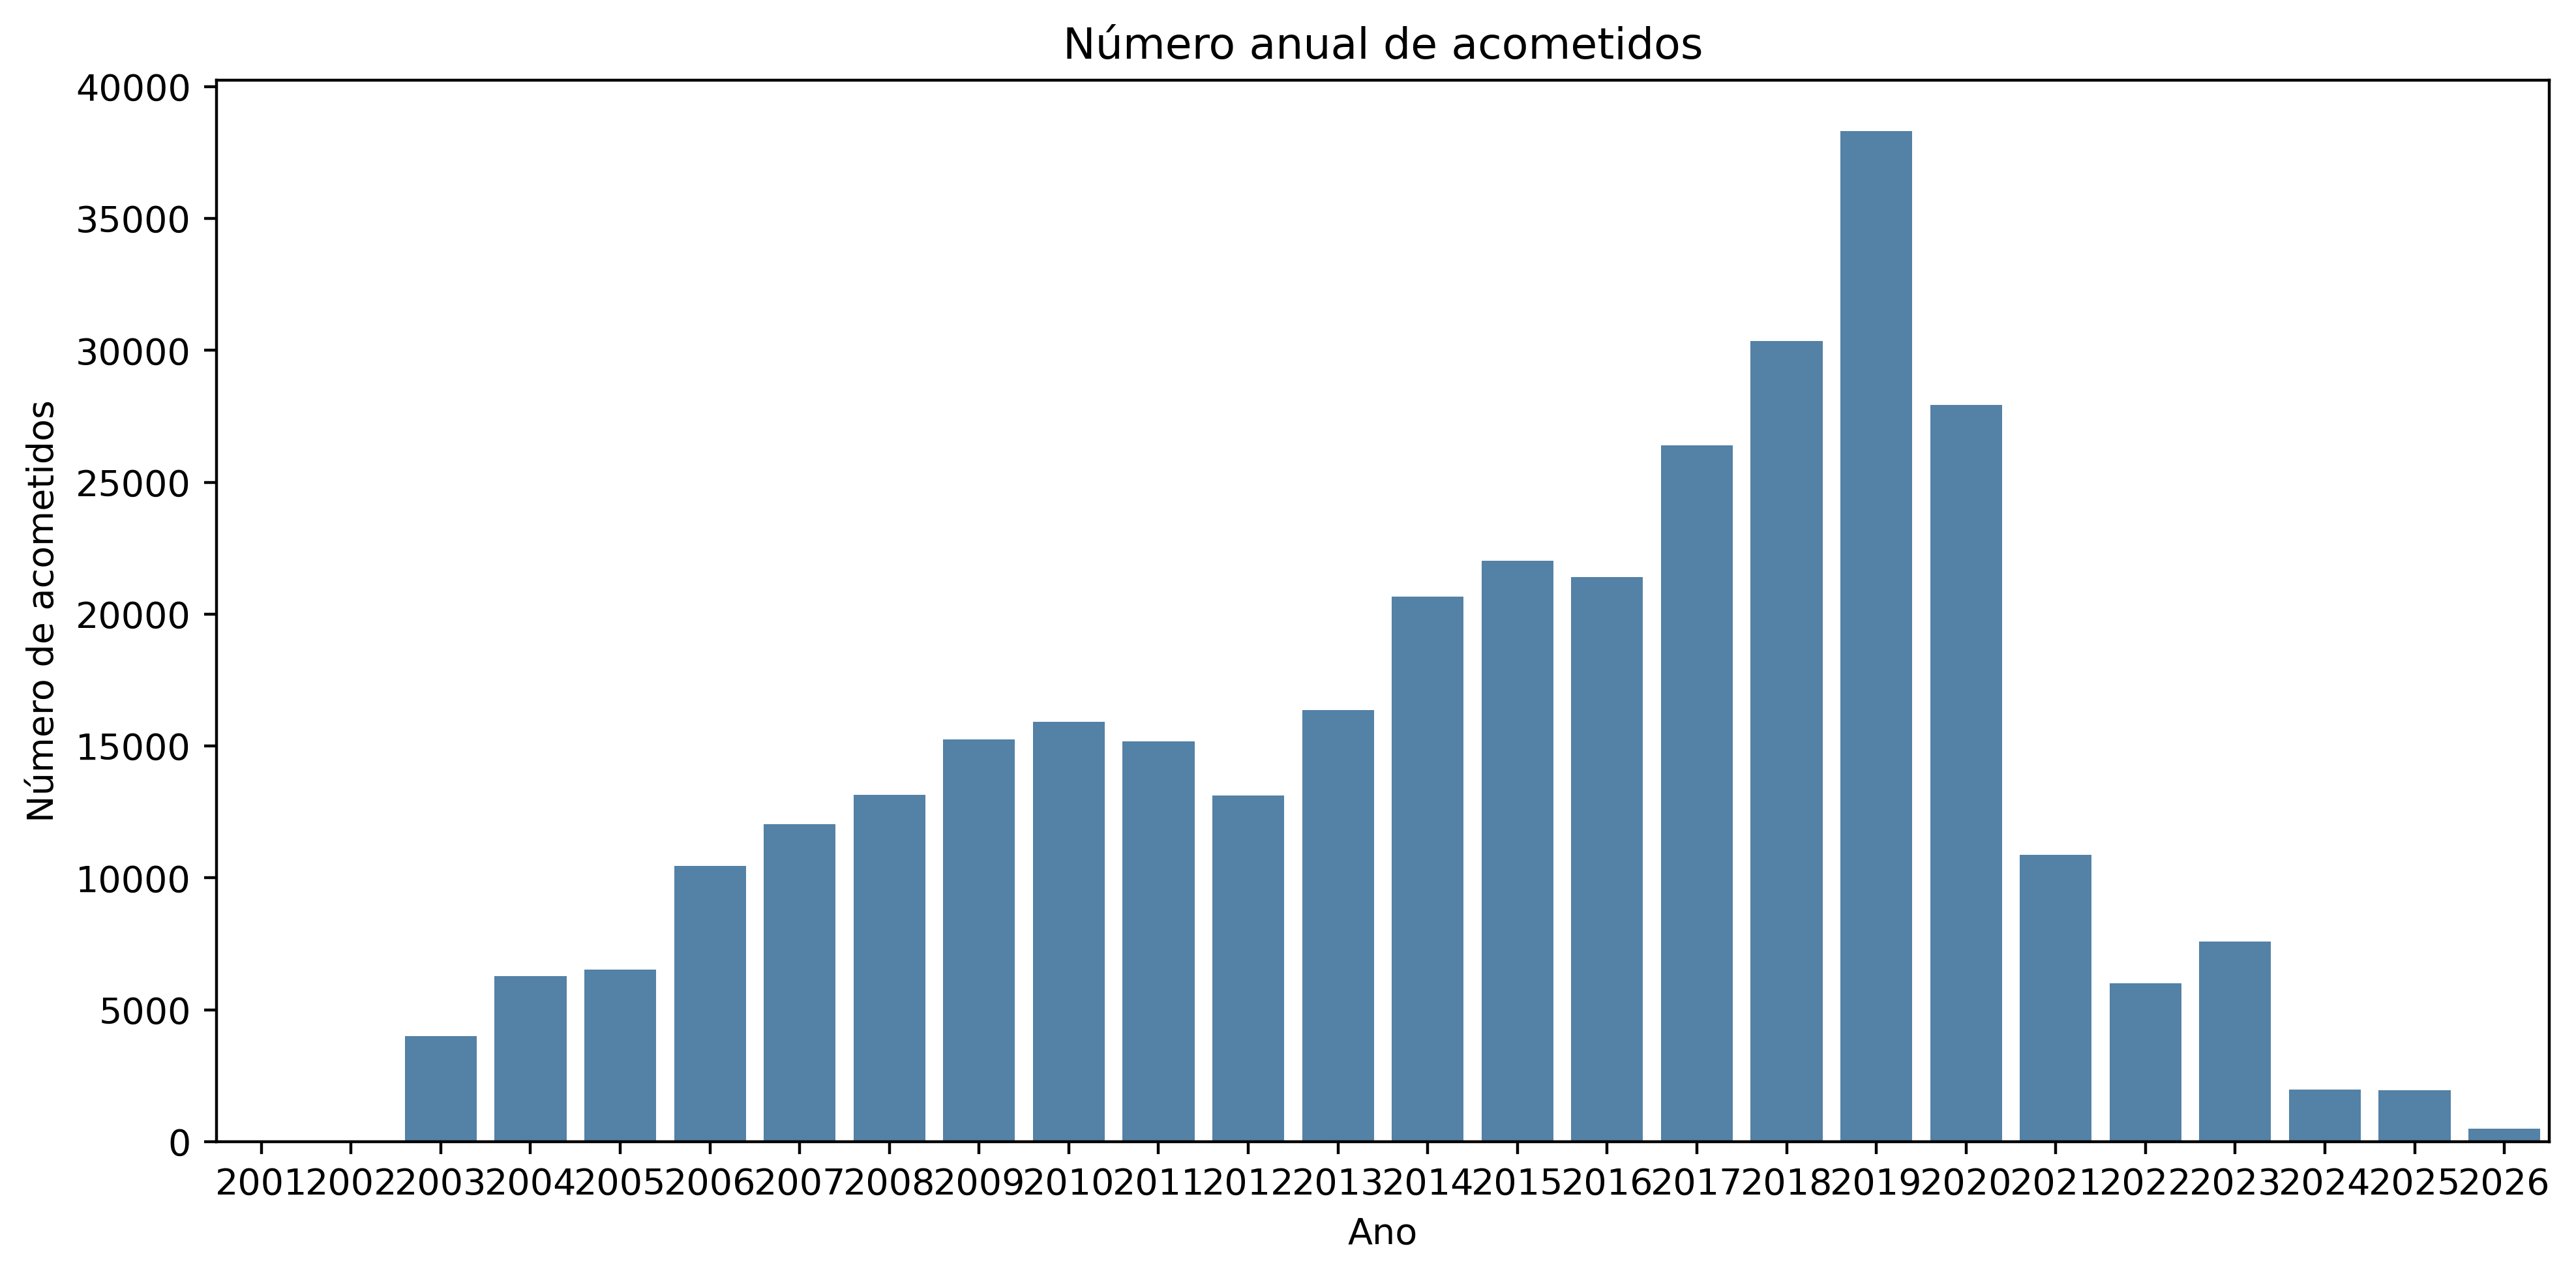

In [141]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_se_infecto.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

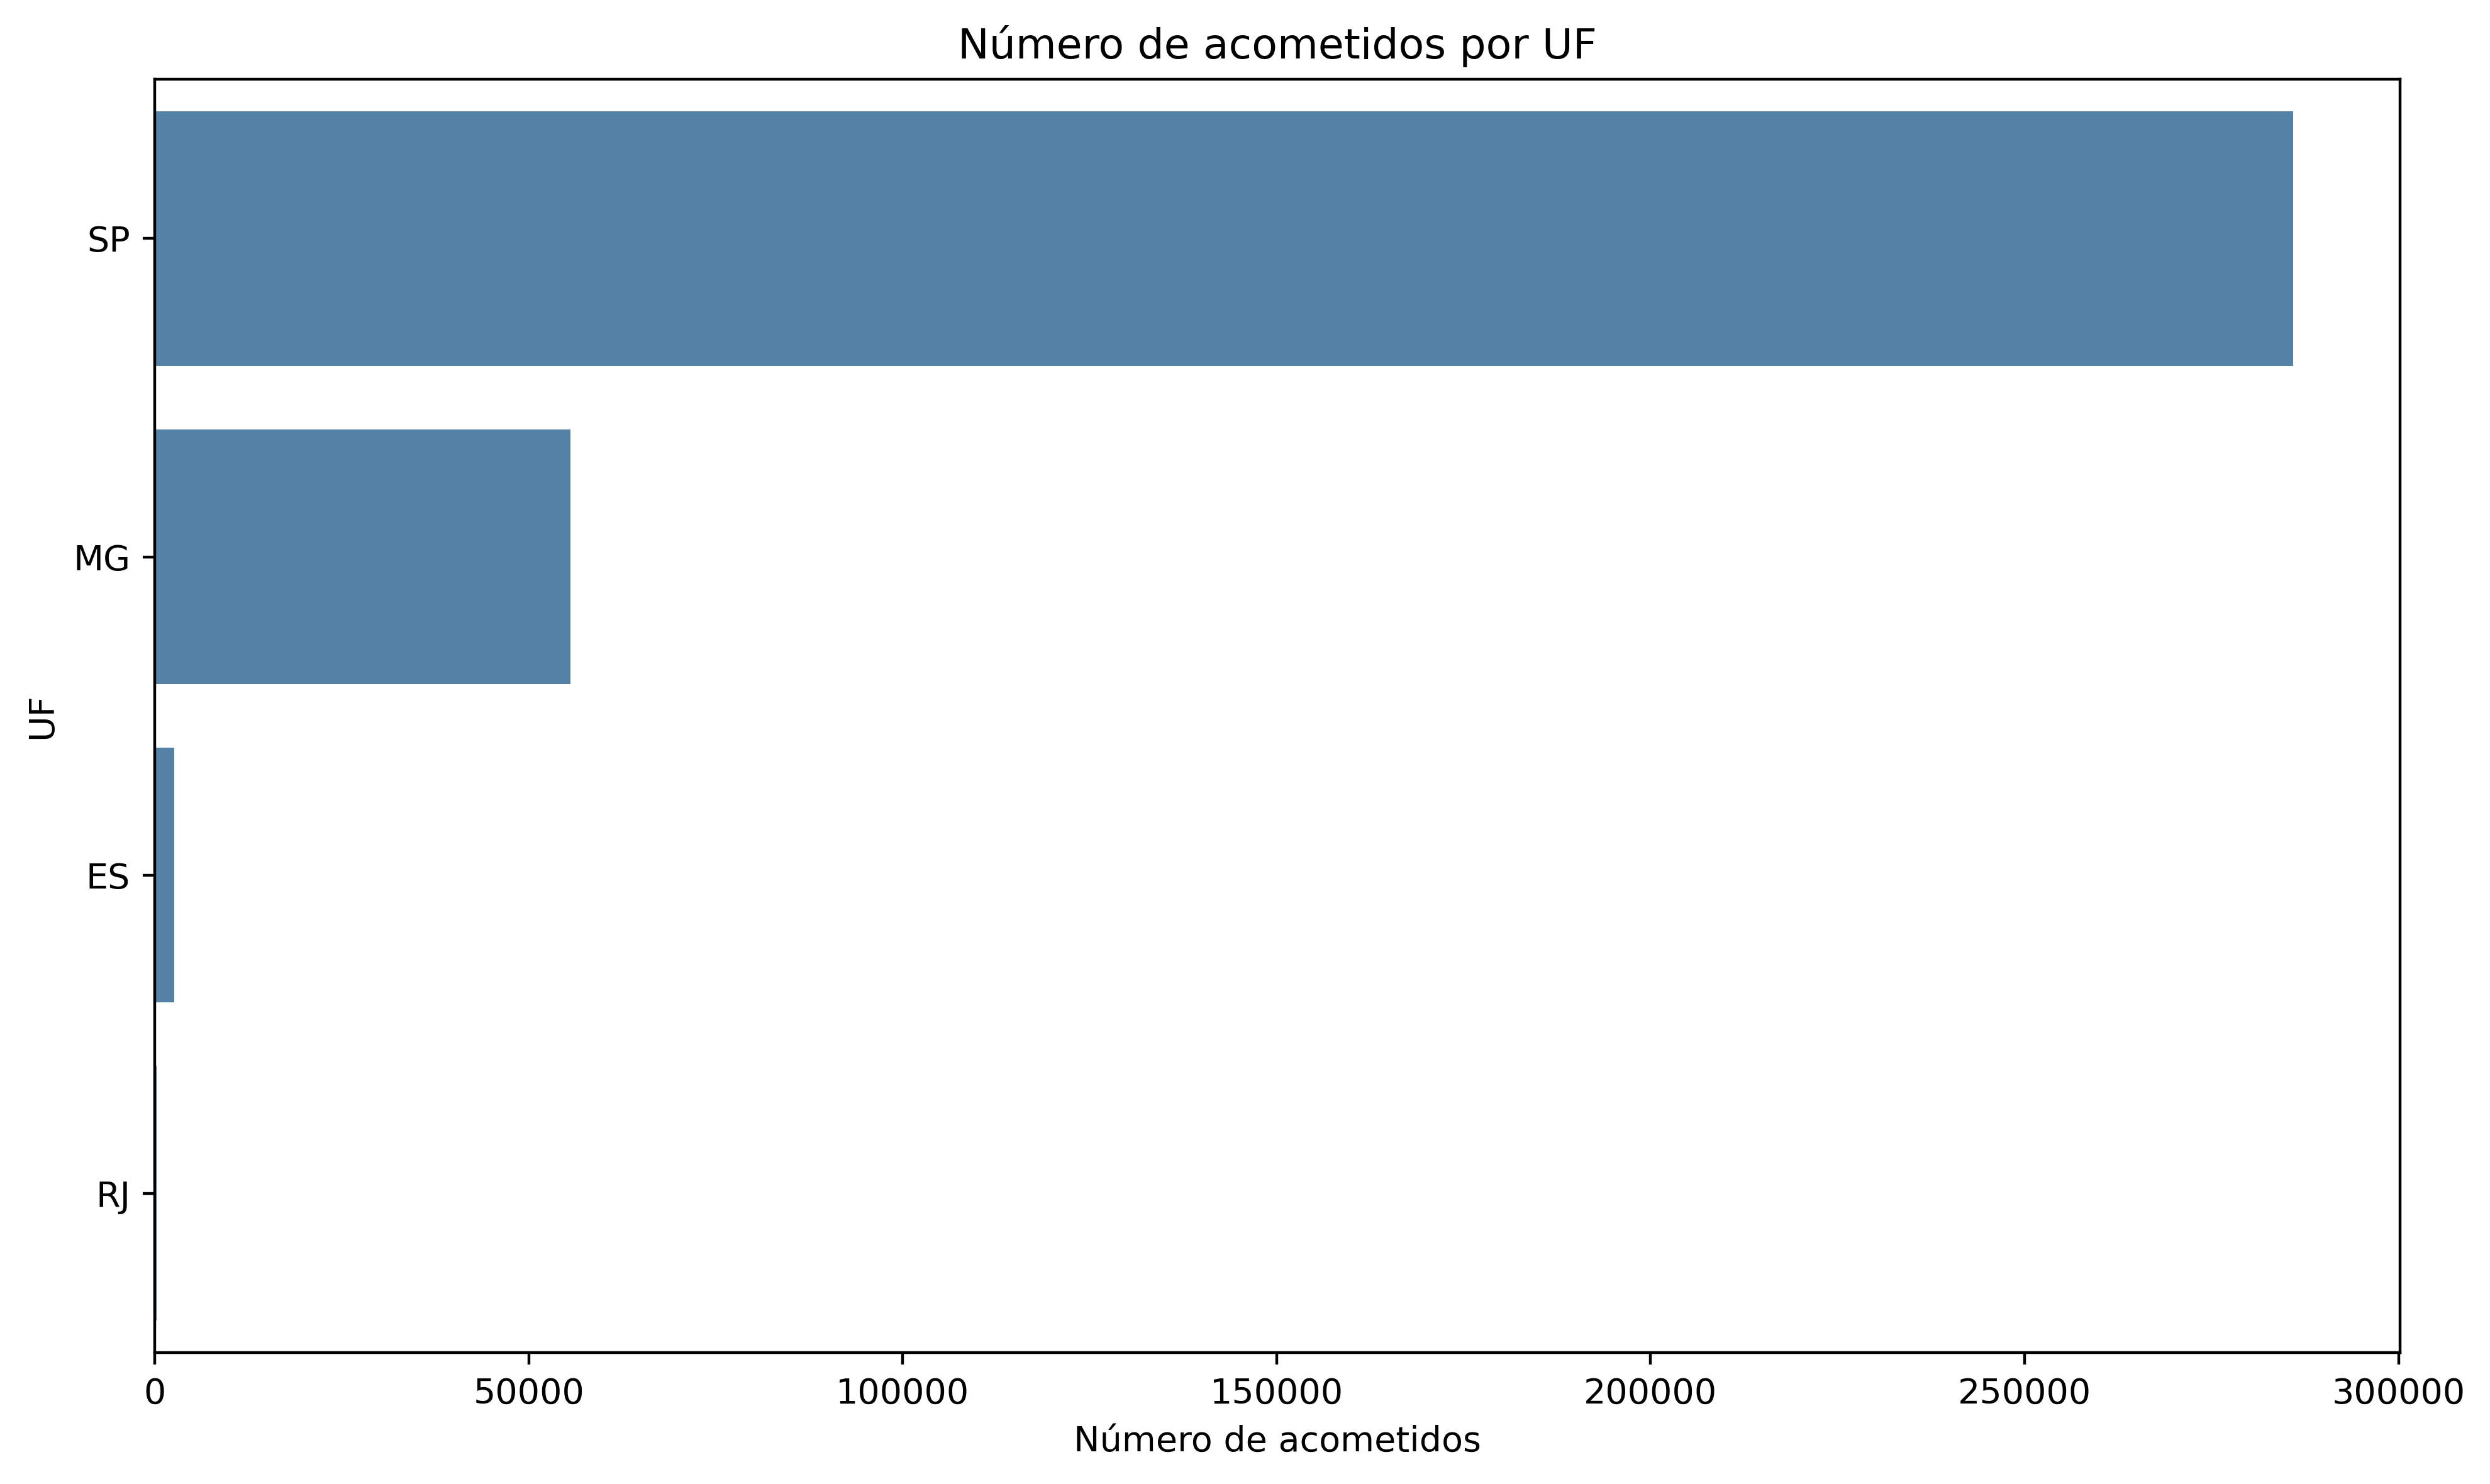

In [142]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [143]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_estat_bovino_se_infecto,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_diagnostico

DIAGNOSTICO,abscesso,abscesso (mamíferos),acrobustite,actinobacilose (ruminantes),actinomicose (já notificado),actinomicose (notificação sif),adenite,agalaxia contagiosa (notificação sif),broncopneumonia,bronquite,...,síndrome nervosa (suspeito),tuberculose,tuberculose (já notificado),tuberculose (notificação sif),tuberculose (reagente já notificado),tuberculose (reagente notificação sif),tuberculose aviária (notificação sif),tuberculose calcificada,tuberculose caseosa,tuberculose miliar
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
ES,57,980,0,7,2,7,207,0,0,0,...,0,37,109,59,0,0,0,239,587,0
MG,13724,4355,22,448,16,1693,2922,2,805,60,...,12,13404,426,947,21,12,2,168,1262,1288
RJ,0,238,0,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SP,63175,13615,77,23,24,172,86762,0,31,34536,...,2,2124,75,487,0,1,0,34988,23037,757


In [144]:
#Analisando o ranking por estado de procedência
ranking_uf_infecto = (
    df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA", as_index=False)
        ["NUMERO_ANIMAIS_ACOMETIDOS"].sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf_infecto

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
3,SP,285872
1,MG,55551
0,ES,2611
2,RJ,269


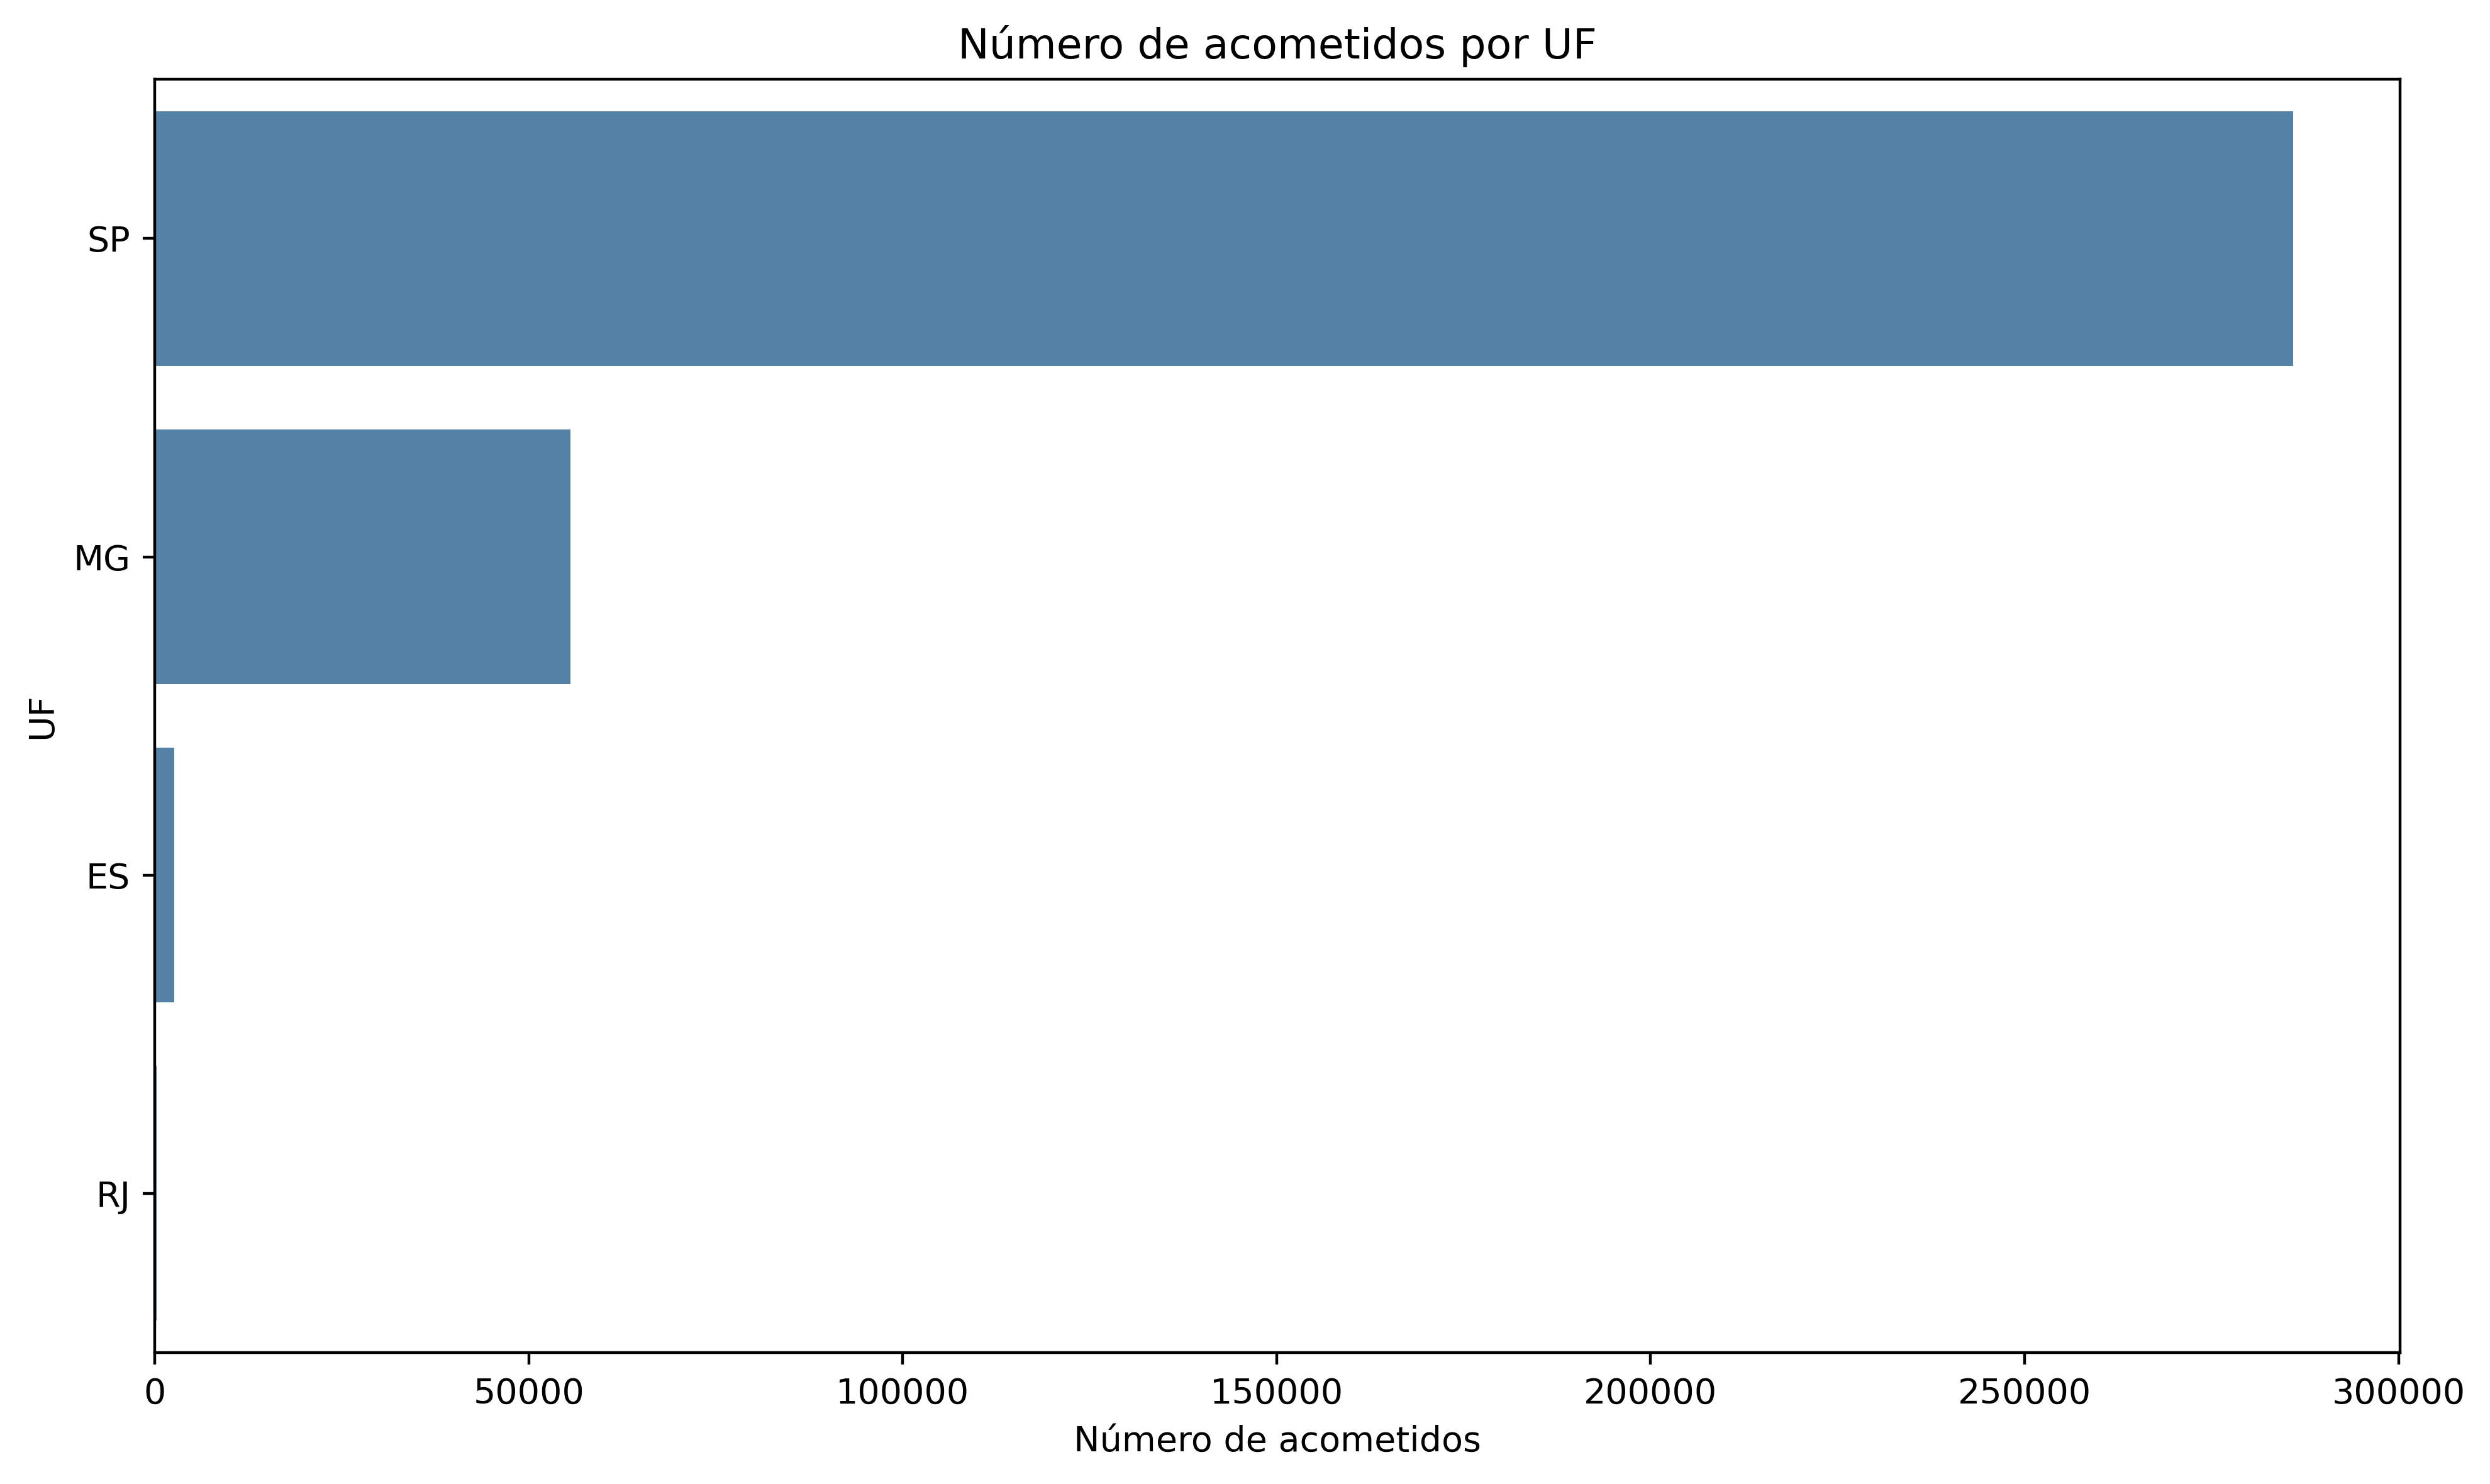

In [145]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [146]:
ranking_uf_infecto["percentual"] = (
    ranking_uf_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf_infecto

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
3,SP,285872,83.029192
1,MG,55551,16.134335
0,ES,2611,0.758344
2,RJ,269,0.078129


In [147]:
ranking_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"].sum().sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
6,adenite,89891
0,abscesso,76956
55,tuberculose calcificada,35395
9,bronquite,34596
56,tuberculose caseosa,24886
1,abscesso (mamíferos),19188
27,linfadenite,18789
49,tuberculose,15565
40,pneumonia,13709
24,lesões tuberculósicas,3108


In [148]:
ranking_diagnostico_infecto["percentual"] = (
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
6,adenite,89891,26.108108
0,abscesso,76956,22.351243
55,tuberculose calcificada,35395,10.280189
9,bronquite,34596,10.048126
56,tuberculose caseosa,24886,7.227936
1,abscesso (mamíferos),19188,5.572998
27,linfadenite,18789,5.457112
49,tuberculose,15565,4.520727
40,pneumonia,13709,3.981667
24,lesões tuberculósicas,3108,0.902693


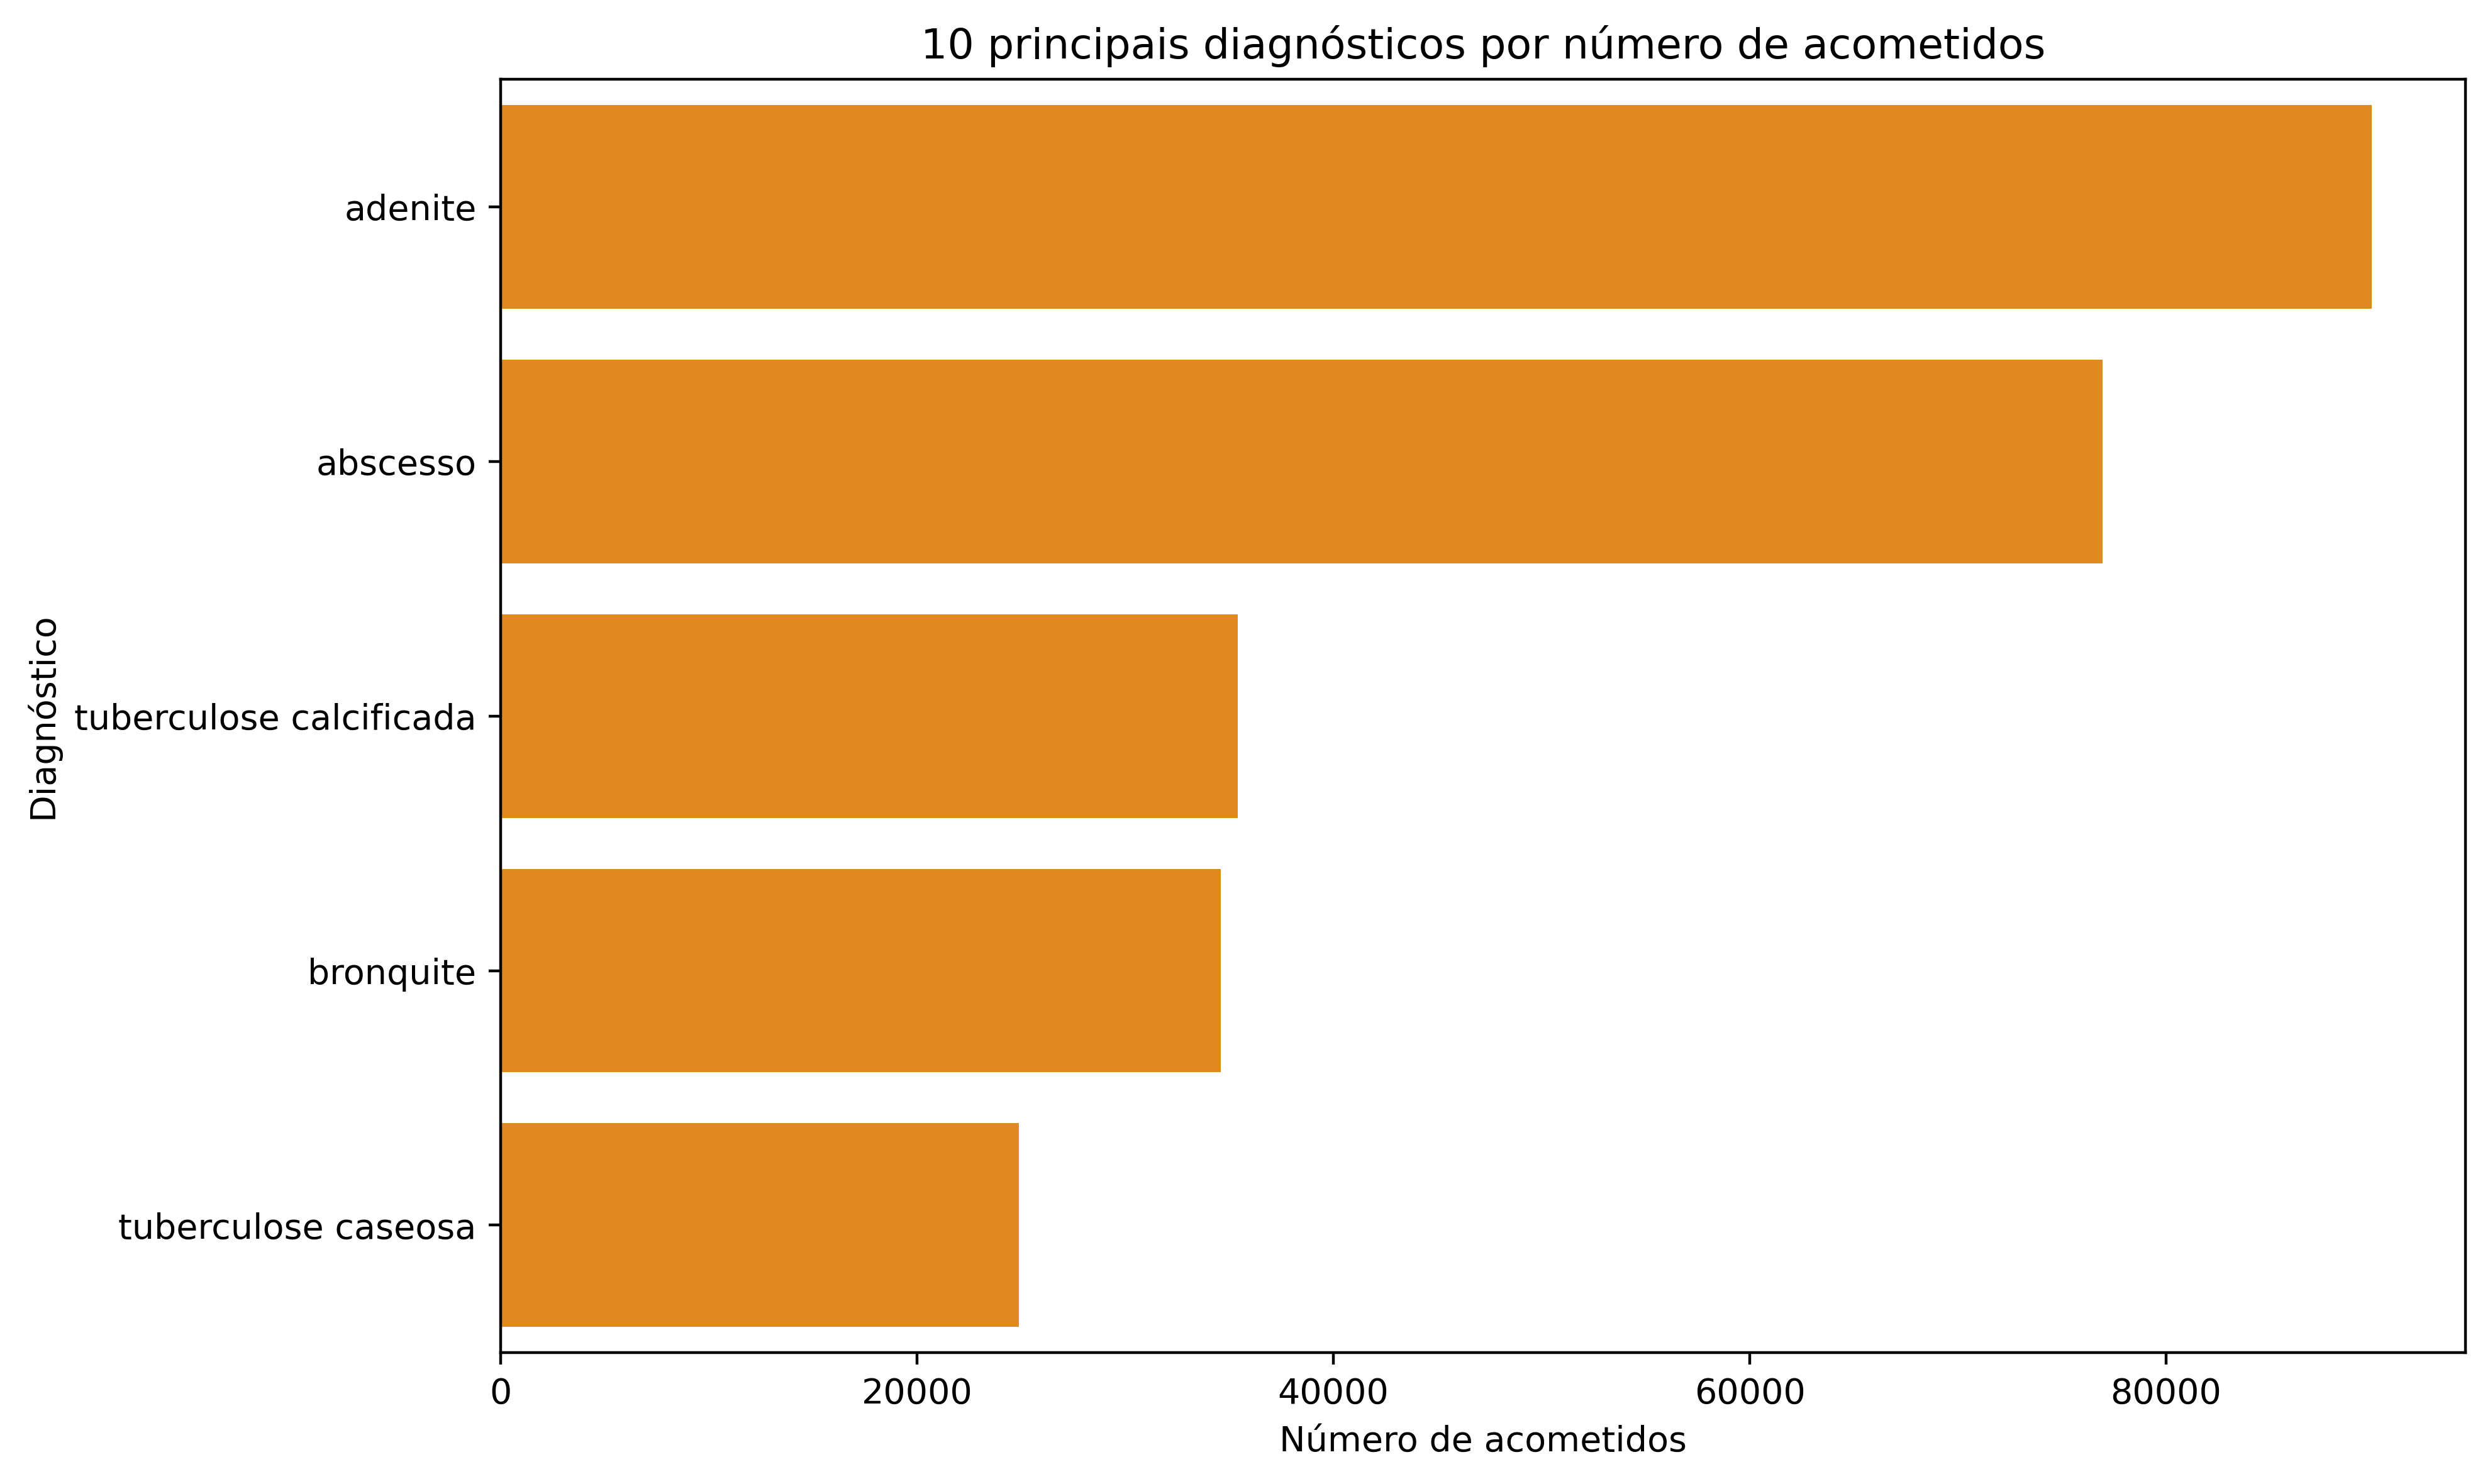

In [149]:
top10_diagnostico_infecto = ranking_diagnostico_infecto.head(5)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [150]:
diagnostico_ano_infecto = (
    df_estat_bovino_se_infecto.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano_infecto

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
1,2001,tuberculose,3
0,2001,bursite,2
5,2002,tuberculose caseosa,8
3,2002,tuberculose,7
4,2002,tuberculose calcificada,4
...,...,...,...
477,2026,tuberculose (notificação sif),13
474,2026,pneumonia enzoótica (notificação sif),8
469,2026,acrobustite,4
470,2026,actinomicose (notificação sif),4


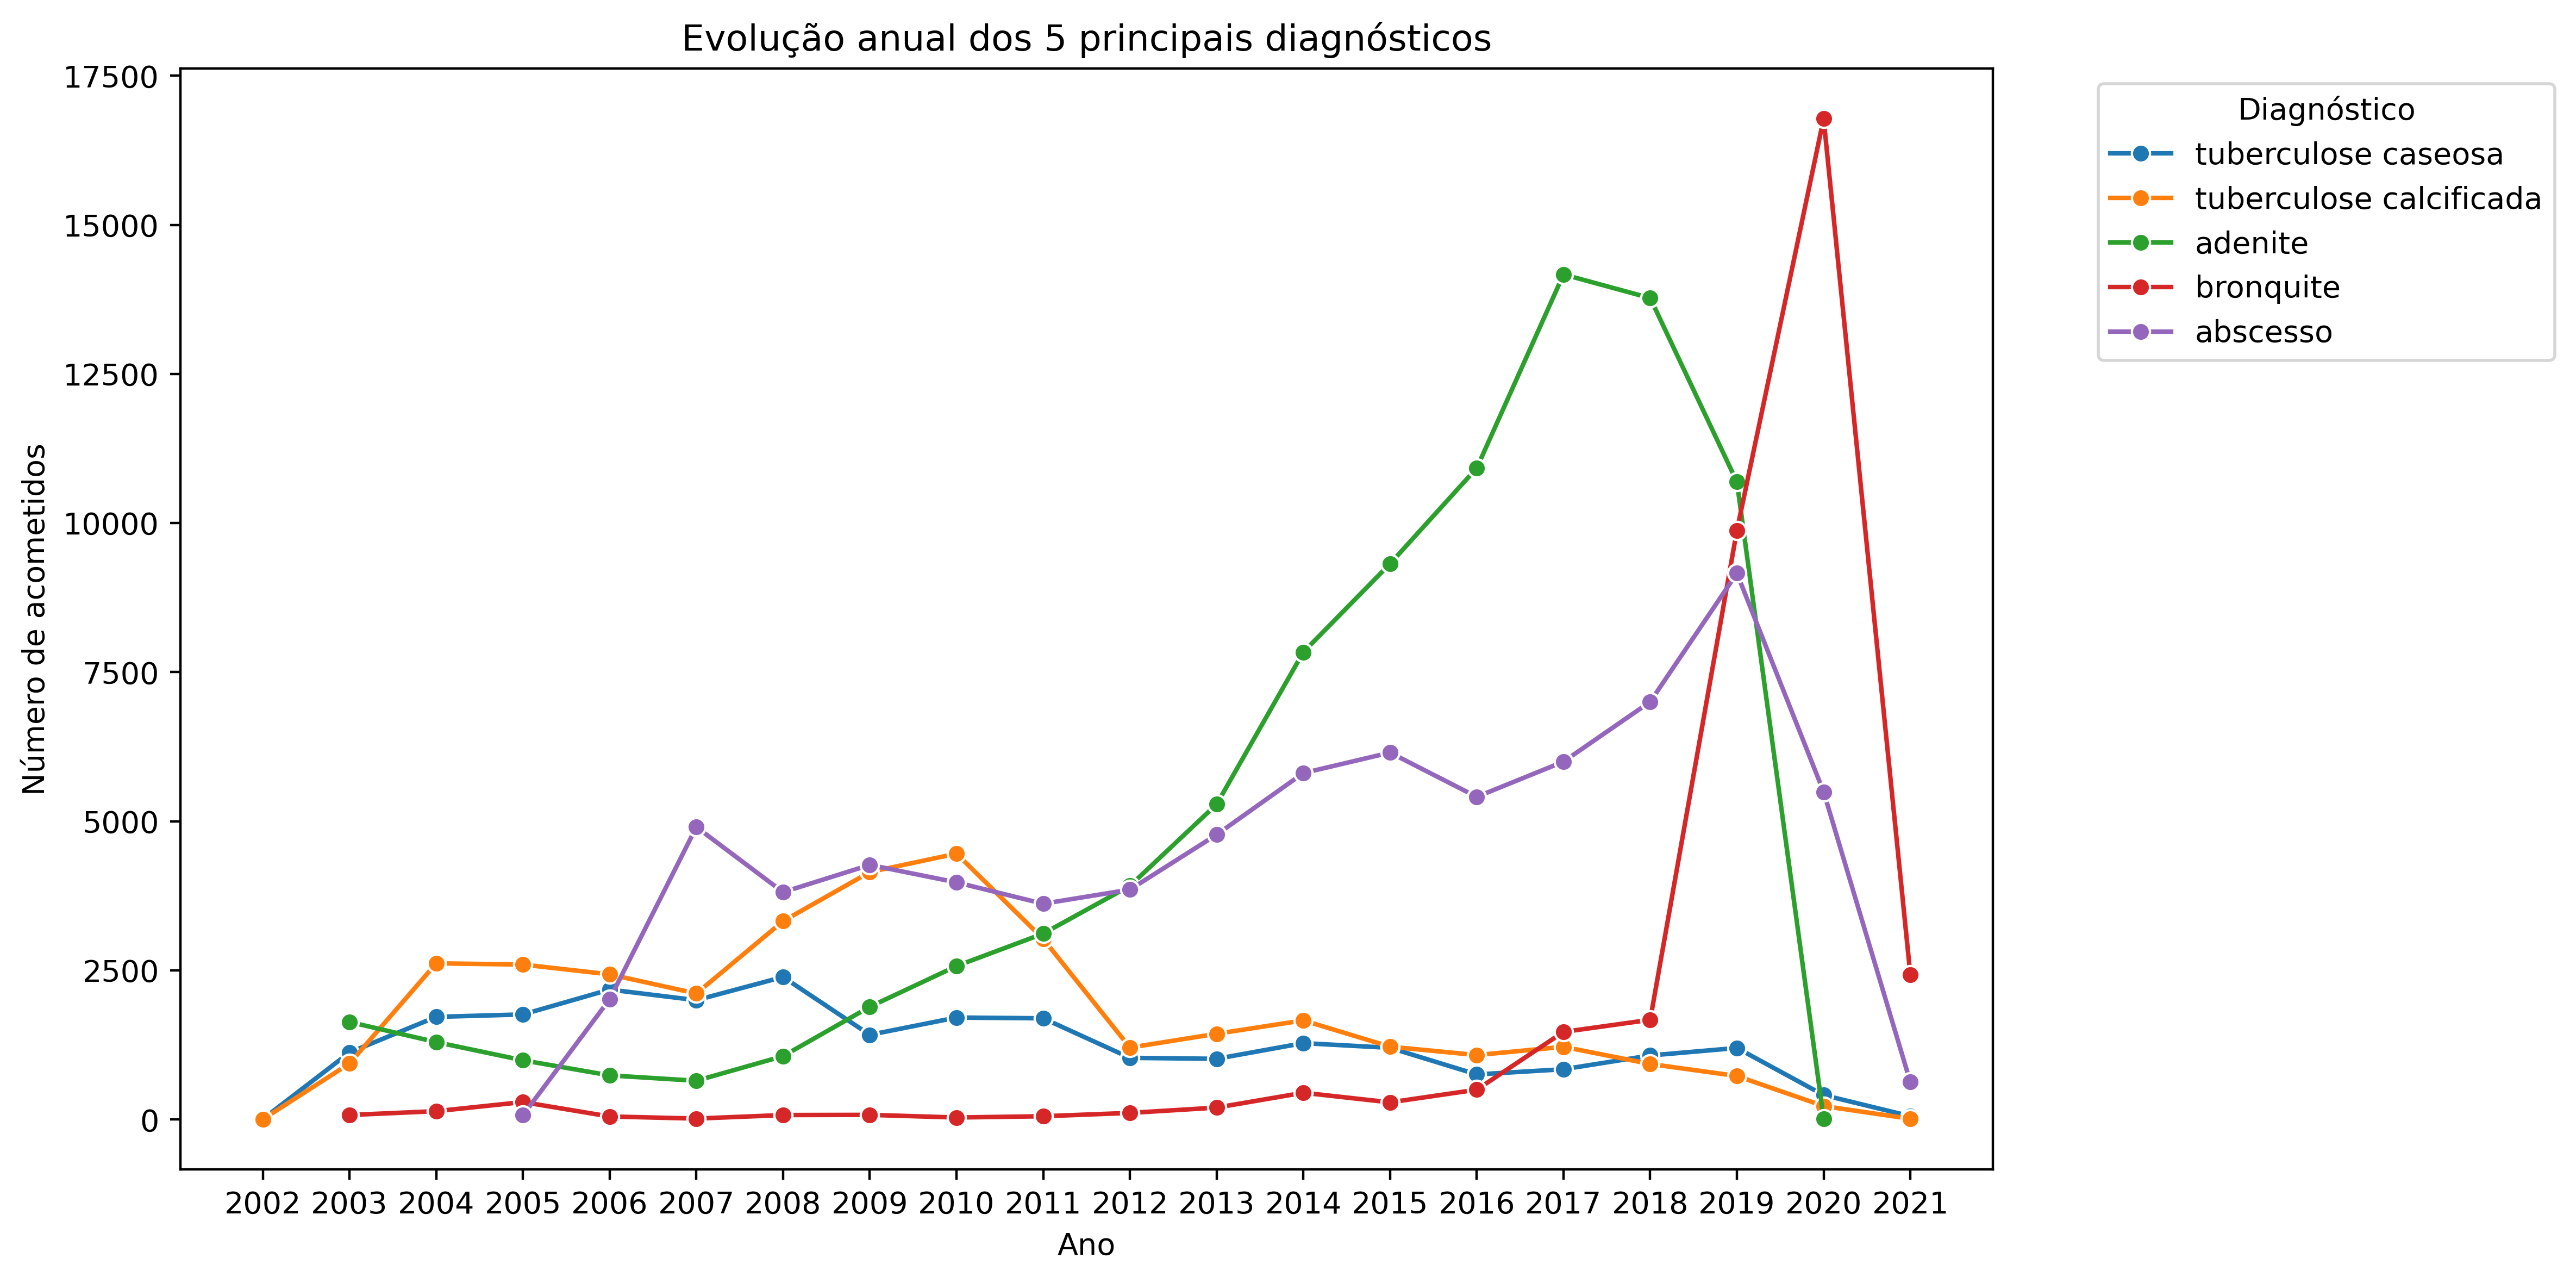

In [151]:
top5_diag_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5_infecto = diagnostico_ano_infecto[
    diagnostico_ano_infecto["DIAGNOSTICO"].isin(top5_diag_infecto)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5_infecto,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5_infecto["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [152]:
media = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 60.57
Mediana: 8.00
Desvio Padrão: 154.85
Variância: 23978.24
Coeficiente de Variação: 255.64%


In [153]:
assimetria = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 5.51
Curtose: 38.71


In [154]:
minimo = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 1872
Amplitude: 1871
Q1: 2.0
Q3: 50.0
IQR: 48.0


In [155]:
q1 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_se_infecto[
    (df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_estat_bovino_se_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
       MES_ANO UF_PROCEDENCIA ESPECIE              DIAGNOSTICO  \
0   2021-01-01             SP  Bovino                bronquite   
1   2019-09-01             SP  Bovino                bronquite   
2   2020-04-01             SP  Bovino                bronquite   
3   2019-07-01             SP  Bovino                bronquite   
4   2020-06-01             SP  Bovino                bronquite   
..         ...            ...     ...                      ...   
713 2016-09-01             MG  Bovino                 abscesso   
714 2019-08-01             MG  Bovino              linfadenite   
715 2014-11-01             SP  Bovino  tuberculose calcificada   
716 2011-10-01             SP  Bovino  tuberculose calcificada   
717 2011-10-01             SP  Bovino              linfadenite   

     NUMERO_ANIMAIS_ACOMETIDOS   ANO  
0                         1872  2021  
1                         1822  2019  
2                         1554  2020  
3                         153

In [156]:
desc_por_uf_infecto = (
      df_estat_bovino_se_infecto.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf_infecto

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,2618,285872,109.194805,23.0,214.579539,1,1872
MG,2478,55551,22.417676,6.0,40.771203,1,422
ES,519,2611,5.030829,2.0,7.871005,1,58
RJ,69,269,3.898551,2.0,4.176774,1,21


In [157]:
desc_por_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico_infecto

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
adenite,387,89891,232.276486,58.0,349.483051,1,1402
abscesso,380,76956,202.515789,167.0,169.702696,1,810
tuberculose calcificada,353,35395,100.269122,72.0,113.996031,1,460
bronquite,227,34596,152.405286,16.0,398.833413,1,1872
tuberculose caseosa,528,24886,47.132576,11.5,58.866277,1,274
abscesso (mamíferos),220,19188,87.218182,31.0,128.487434,1,682
linfadenite,362,18789,51.903315,39.0,55.880998,1,287
tuberculose,405,15565,38.432099,17.0,48.038644,1,258
pneumonia,416,13709,32.954327,21.0,33.518998,1,273


In [158]:
ranking_diagnostico_infecto = (
    df_estat_bovino_se_infecto.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico_infecto["percentual"] = (
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico_infecto["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico_infecto["percentual_acumulado"] = ranking_diagnostico_infecto["percentual"].cumsum()

ranking_diagnostico_infecto

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
6,adenite,89891,26.108108,26.108108
0,abscesso,76956,22.351243,48.459351
55,tuberculose calcificada,35395,10.280189,58.739540
9,bronquite,34596,10.048126,68.787667
56,tuberculose caseosa,24886,7.227936,76.015603
1,abscesso (mamíferos),19188,5.572998,81.588601
27,linfadenite,18789,5.457112,87.045713
49,tuberculose,15565,4.520727,91.566440
40,pneumonia,13709,3.981667,95.548107
24,lesões tuberculósicas,3108,0.902693,96.450801


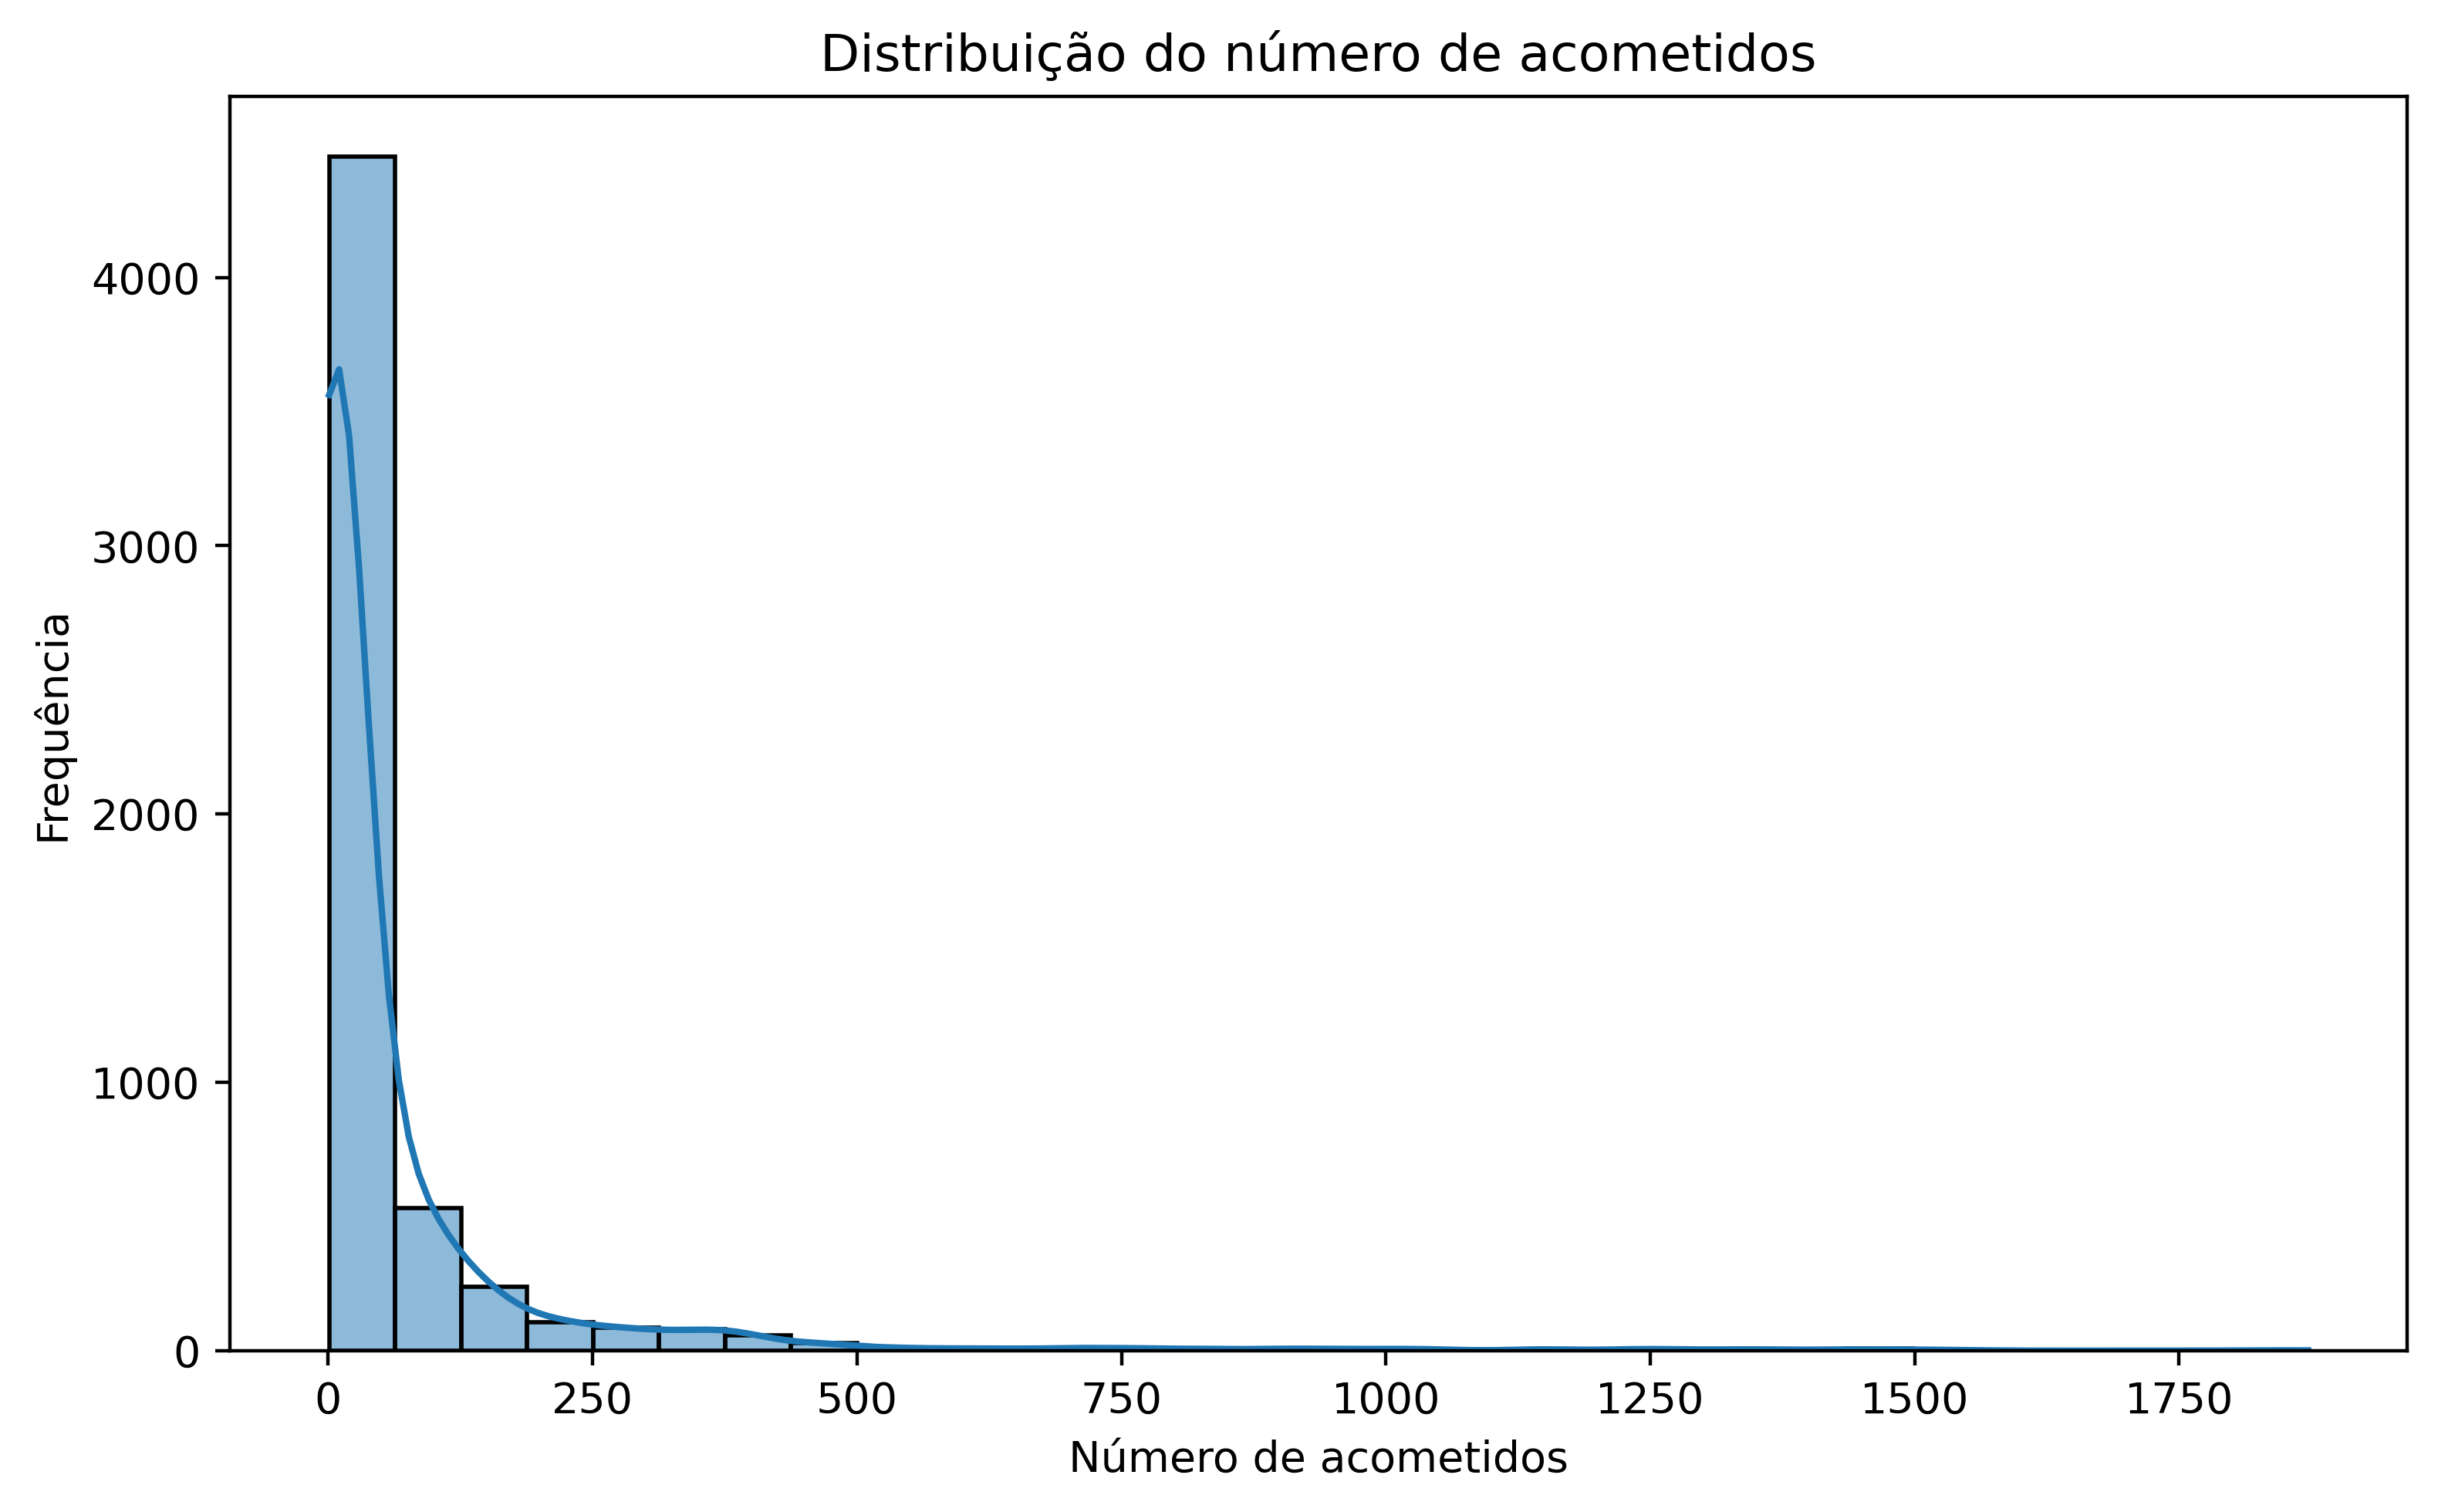

In [159]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_se_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

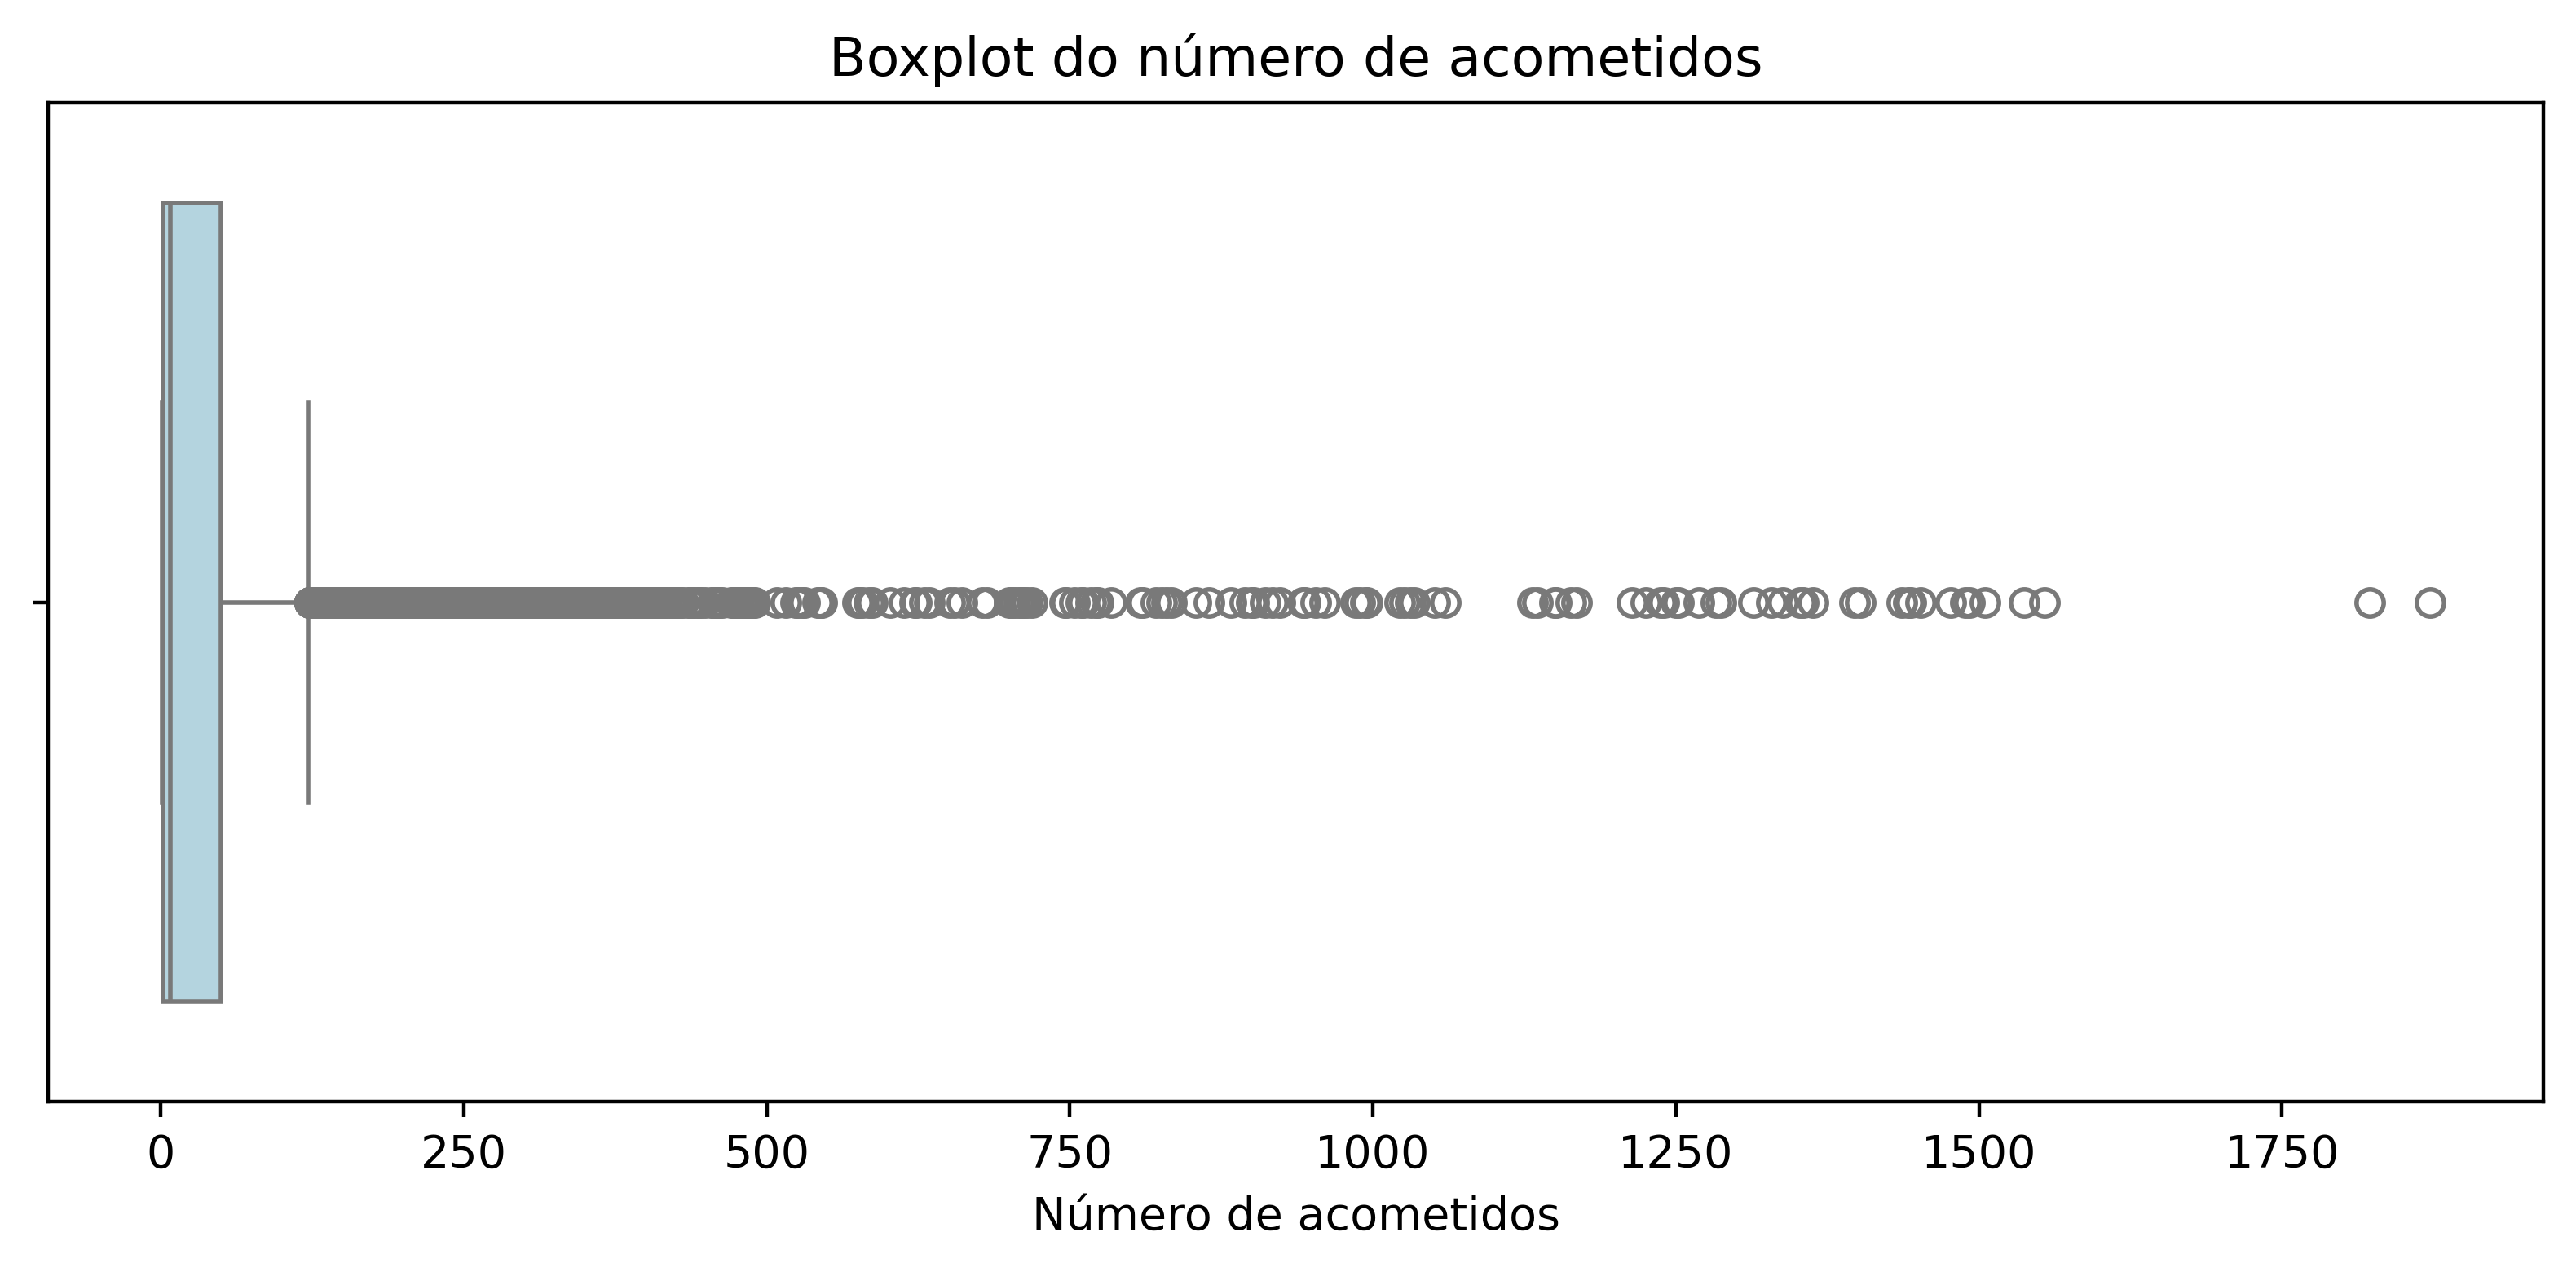

In [160]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_se_infecto,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()

Análise estatística abate sudeste

In [276]:
df_estat_bovino_abate_sudeste.head(10)

,ANO,MES,UF_PROCEDENCIA,MUNICIPIO_PROCEDENCIA,CATEGORIA,ESPECIE,Sexo,QUANTIDADE
0,2025,8,MG,Araguari,Bovino,Bovino,Indeterminado,3697
1,2025,9,MG,Monte Alegre de Minas,Bovino,Bovino,Indeterminado,1173
2,2025,6,MG,Cascalho Rico,Bovino,Bovino,Indeterminado,412
3,2021,2,MG,Estrela do Sul,Bovino,Bovino,Indeterminado,1576
4,2021,2,MG,Campina Verde,Bovino,Bovino,Indeterminado,7180
5,2021,2,MG,Vazante,Bovino,Bovino,Indeterminado,268
6,2021,3,MG,Tupaciguara,Bovino,Bovino,Indeterminado,1342
7,2021,3,MG,Tiros,Bovino,Bovino,Indeterminado,510
8,2021,2,MG,Sao Gotardo,Bovino,Bovino,Indeterminado,68
9,2021,2,MG,Carmo do Paranaiba,Bovino,Bovino,Indeterminado,417


In [277]:
df_group_ano = df_estat_bovino_abate_sudeste.groupby("ANO", as_index=False)["QUANTIDADE"].sum().sort_values("ANO")
df_group_ano

,ANO,QUANTIDADE
0,1995,245
1,2000,12632
2,2001,19572
3,2002,204827
4,2003,1442944
5,2004,3451711
6,2005,3650665
7,2006,4094388
8,2007,4715533
9,2008,4645698


In [279]:
df_estat_bovino_abate_sudeste_bov = df_estat_bovino_abate_sudeste[df_estat_bovino_abate_sudeste['ESPECIE'].isin(['Bovino']) & df_estat_bovino_abate_sudeste['ANO'].isin(range(2006, 2027))]
print(df_estat_bovino_abate_sudeste_bov)

         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA ESPECIE  \
0       2025    8             MG               Araguari        Bovino  Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino  Bovino   
2       2025    6             MG          Cascalho Rico        Bovino  Bovino   
3       2021    2             MG         Estrela do Sul        Bovino  Bovino   
4       2021    2             MG          Campina Verde        Bovino  Bovino   
...      ...  ...            ...                    ...           ...     ...   
517945  2020    6             MG               Paracatu  Bovino Femea  Bovino   
517946  2020    6             MG             Indaiabira  Bovino Macho  Bovino   
517947  2020    6             SP      Américo De Campos  Bovino Macho  Bovino   
517948  2020    7             SP                 Sabino  Bovino Macho  Bovino   
517949  2020    7             SP                  Quatá  Bovino Macho  Bovino   

                 Sexo  QUAN

In [312]:
df_group_ano_abate = df_estat_bovino_abate_sudeste_bov.groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"].sum().sort_values("ANO")
df_group_ano_abate.to_excel("tabela_abateano.xlsx", index=False)

In [280]:
df_estat_bovino_abate_sudeste_bov.info()

<class 'pandas.core.frame.DataFrame'>
Index: 456716 entries, 0 to 517949
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   ANO                    456716 non-null  int64 
 1   MES                    456716 non-null  int64 
 2   UF_PROCEDENCIA         456716 non-null  object
 3   MUNICIPIO_PROCEDENCIA  456716 non-null  object
 4   CATEGORIA              456716 non-null  object
 5   ESPECIE                456716 non-null  object
 6   Sexo                   456716 non-null  object
 7   QUANTIDADE             456716 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 31.4+ MB


In [281]:
df_estat_bovino_abate_sudeste_bov.describe()

,ANO,MES,QUANTIDADE
count,456716.000000,456716.000000,456716.000000
mean,2014.249424,6.362116,197.263680
std,5.242273,3.419957,577.533751
min,2006.000000,1.000000,0.000000
25%,2010.000000,3.000000,20.000000
50%,2014.000000,6.000000,57.000000
75%,2018.000000,9.000000,151.000000
max,2026.000000,12.000000,43708.000000


In [282]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis_abate = ["ANO","UF_PROCEDENCIA", "Sexo"]

for var in variaveis_abate:
    resumo = (
        df_estat_bovino_abate_sudeste_bov.groupby(var, as_index=False)["QUANTIDADE"]
          .sum()
          .sort_values("QUANTIDADE", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["QUANTIDADE"] / resumo["QUANTIDADE"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))



Resumo por ANO


,ANO,QUANTIDADE,percentual
19,2025,5593073,6.208078
18,2024,5125195,5.688752
8,2014,4990477,5.539221
13,2019,4736142,5.256920
1,2007,4713633,5.231936
17,2023,4658337,5.170560
2,2008,4645047,5.155808
7,2013,4618327,5.126150
16,2022,4545378,5.045180
12,2018,4508448,5.004189



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,QUANTIDADE,percentual
3,SP,44591091,49.494249
1,MG,41899825,46.507056
0,ES,3179867,3.529520
2,RJ,422696,0.469175



Resumo por Sexo


,Sexo,QUANTIDADE,percentual
2,Macho,45315665,50.298496
1,Indeterminado,25175296,27.943527
0,Femea,19602518,21.757977


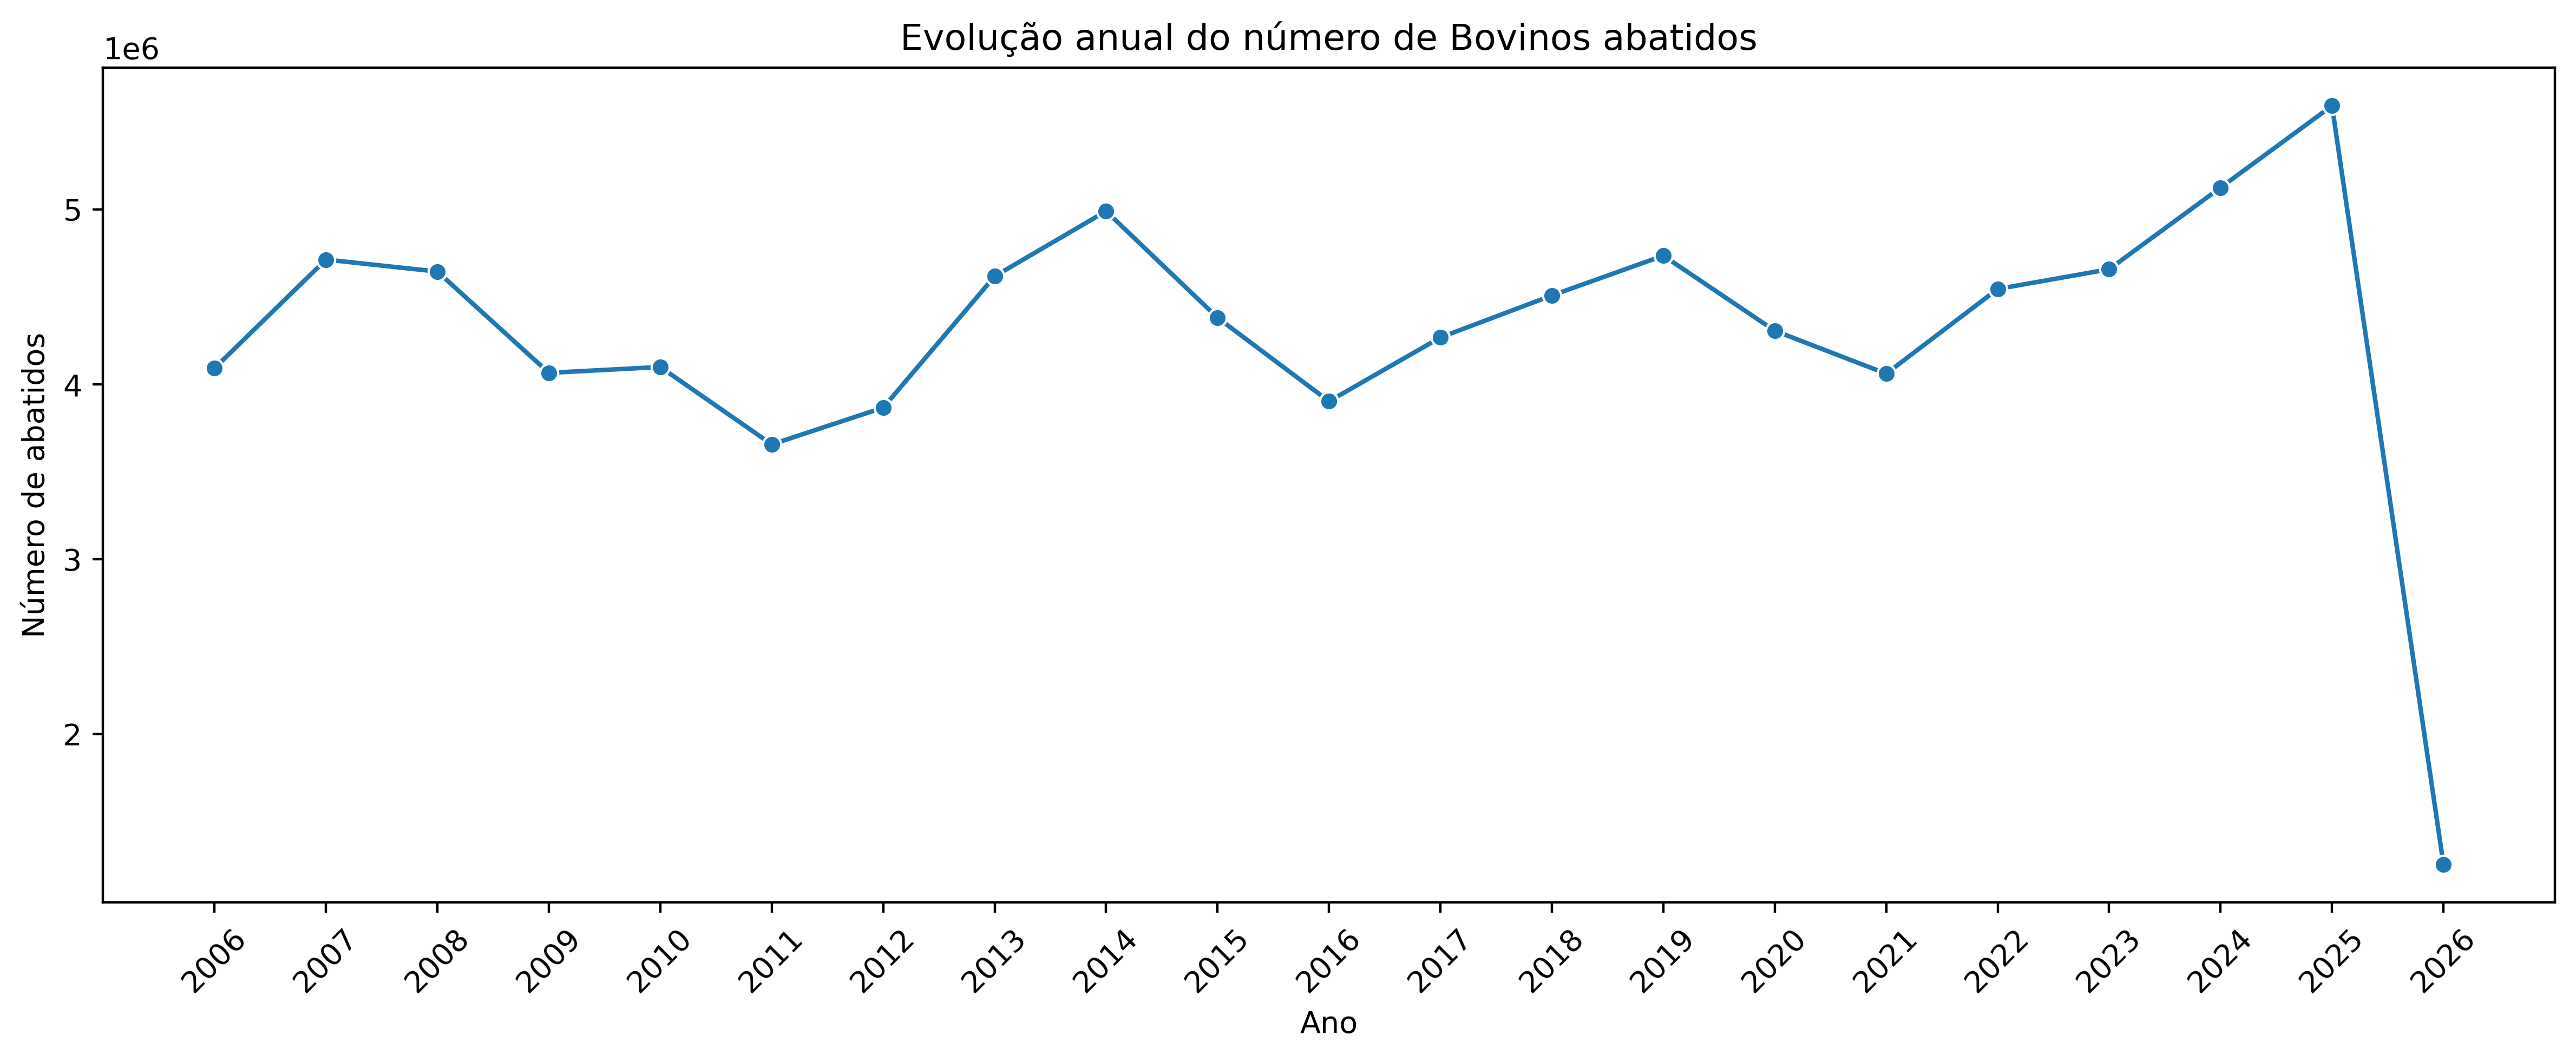

In [283]:
#criando a série anual do número de acometidos por ano
serie_anual_abate = (
   df_estat_bovino_abate_sudeste_bov.groupby("ANO", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual_abate,
    x="ANO",
    y="QUANTIDADE",
    marker="o"
)

pl.title("Evolução anual do número de Bovinos abatidos")
pl.xlabel("Ano")
pl.ylabel("Número de abatidos")
pl.xticks(serie_anual_abate["ANO"].dropna().astype(int), rotation=45)
pl.tight_layout()
pl.show()


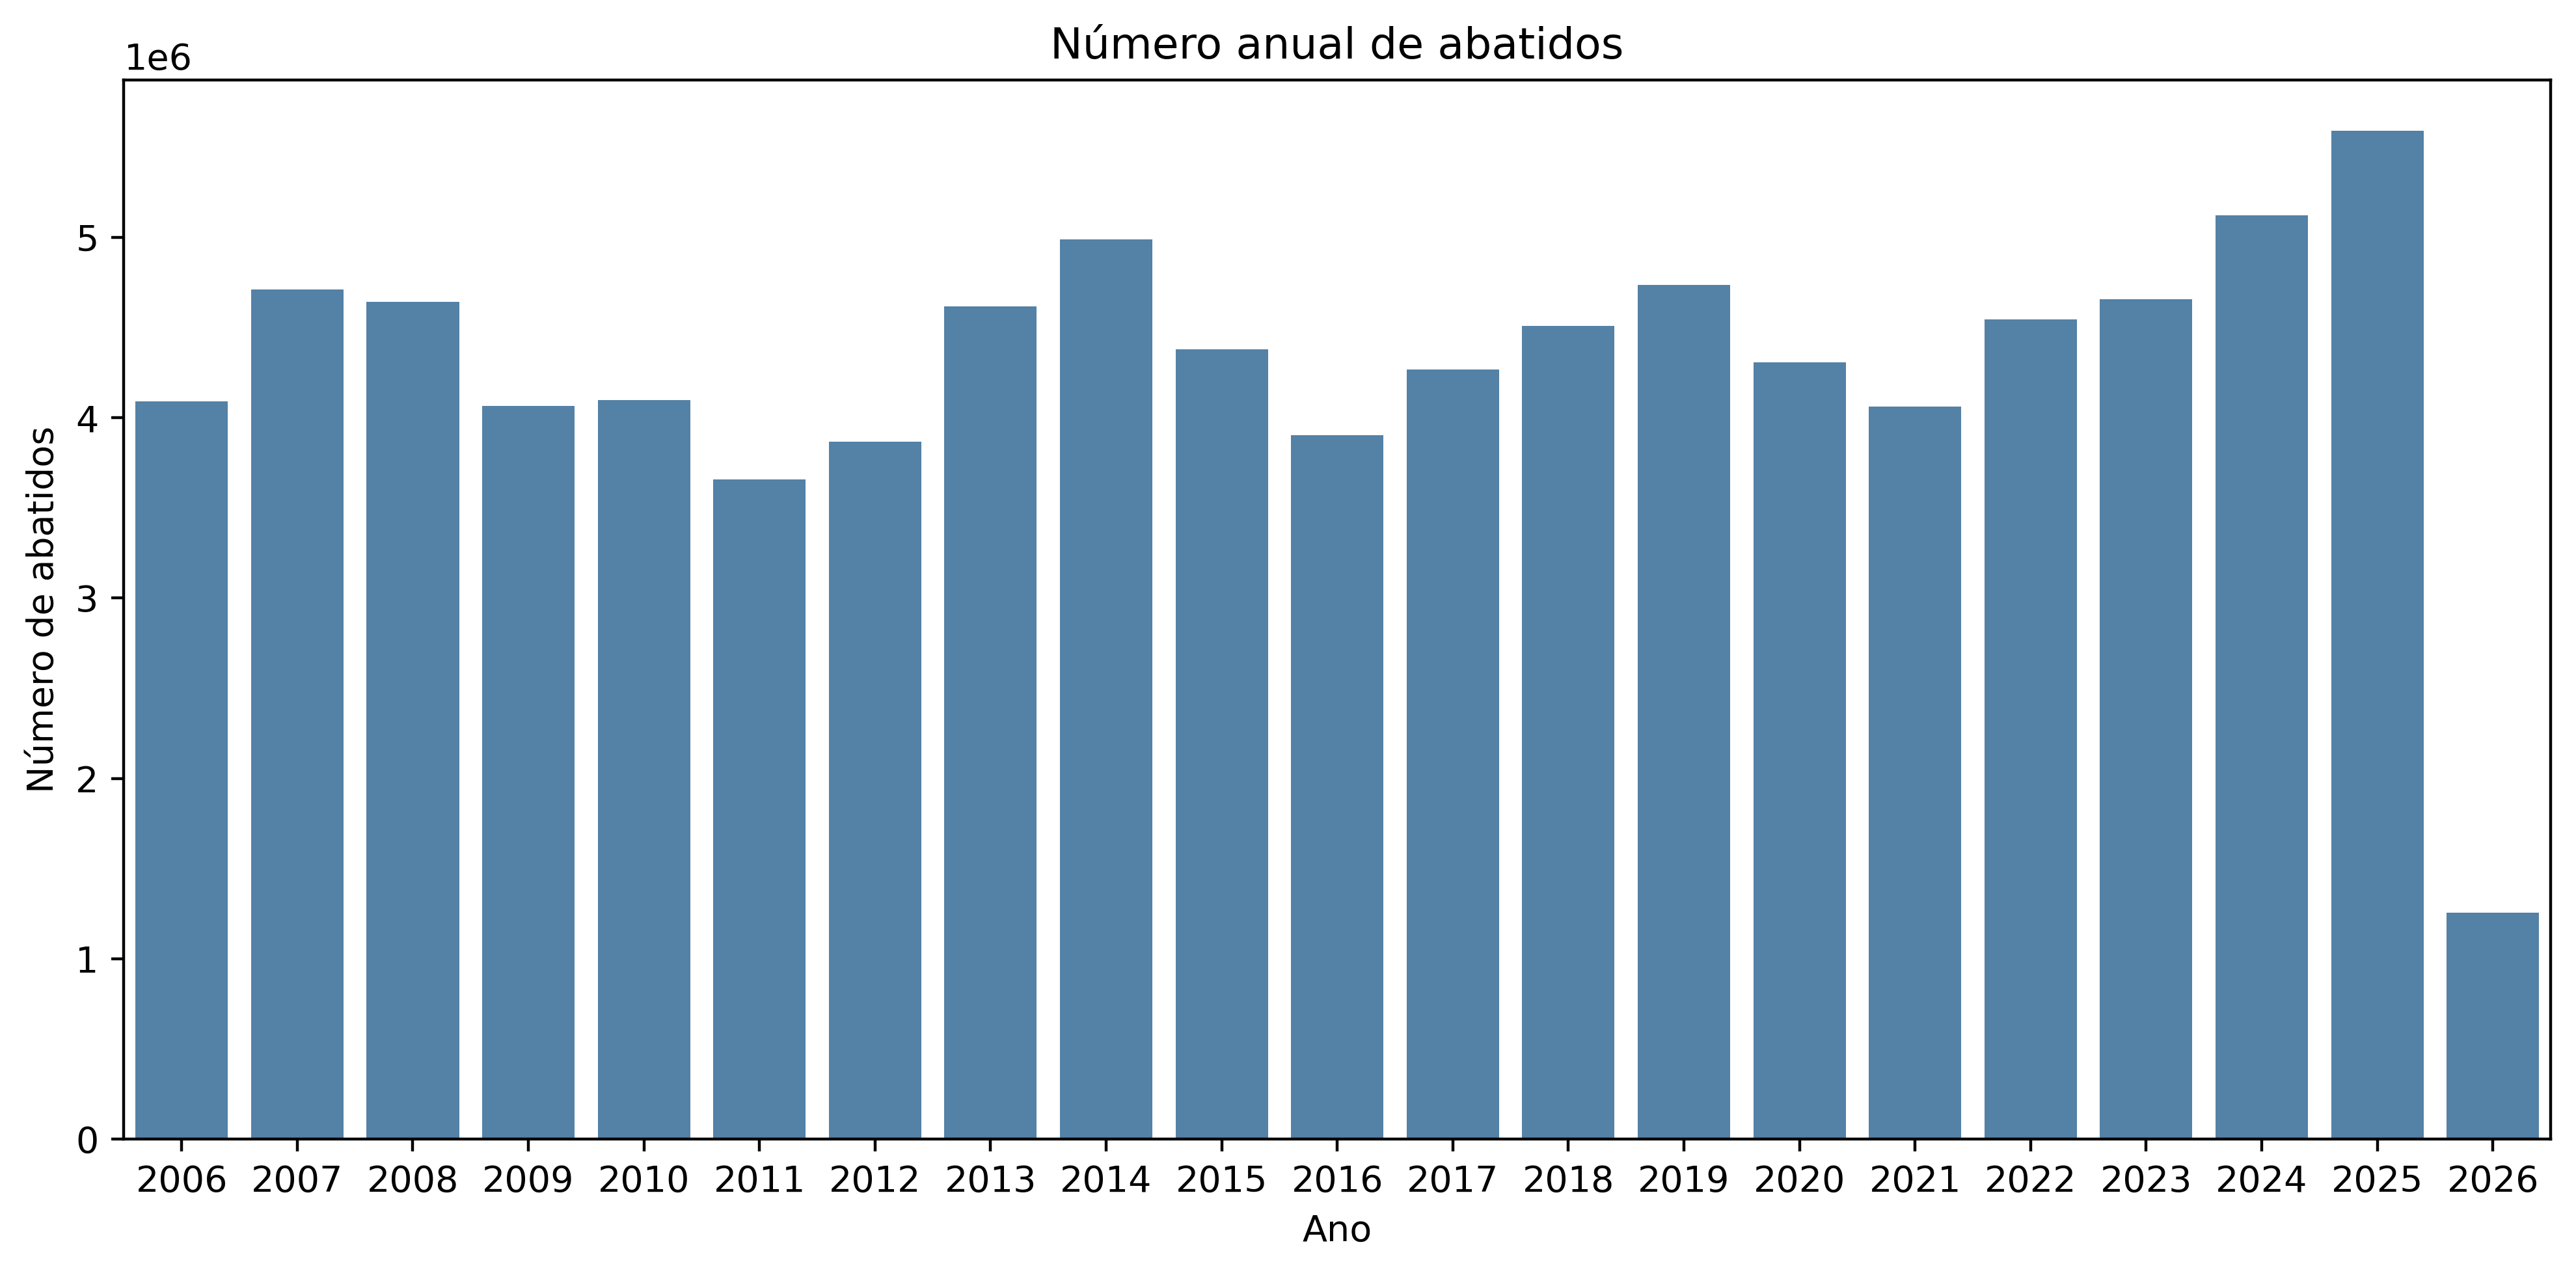

In [284]:
#criando o gráfico de barras do número anual de abatidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_estat_bovino_abate_sudeste_bov.groupby("ANO", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="QUANTIDADE",
    color="steelblue"
)

pl.title("Número anual de abatidos")
pl.xlabel("Ano")
pl.ylabel("Número de abatidos")
pl.tight_layout()
pl.show()


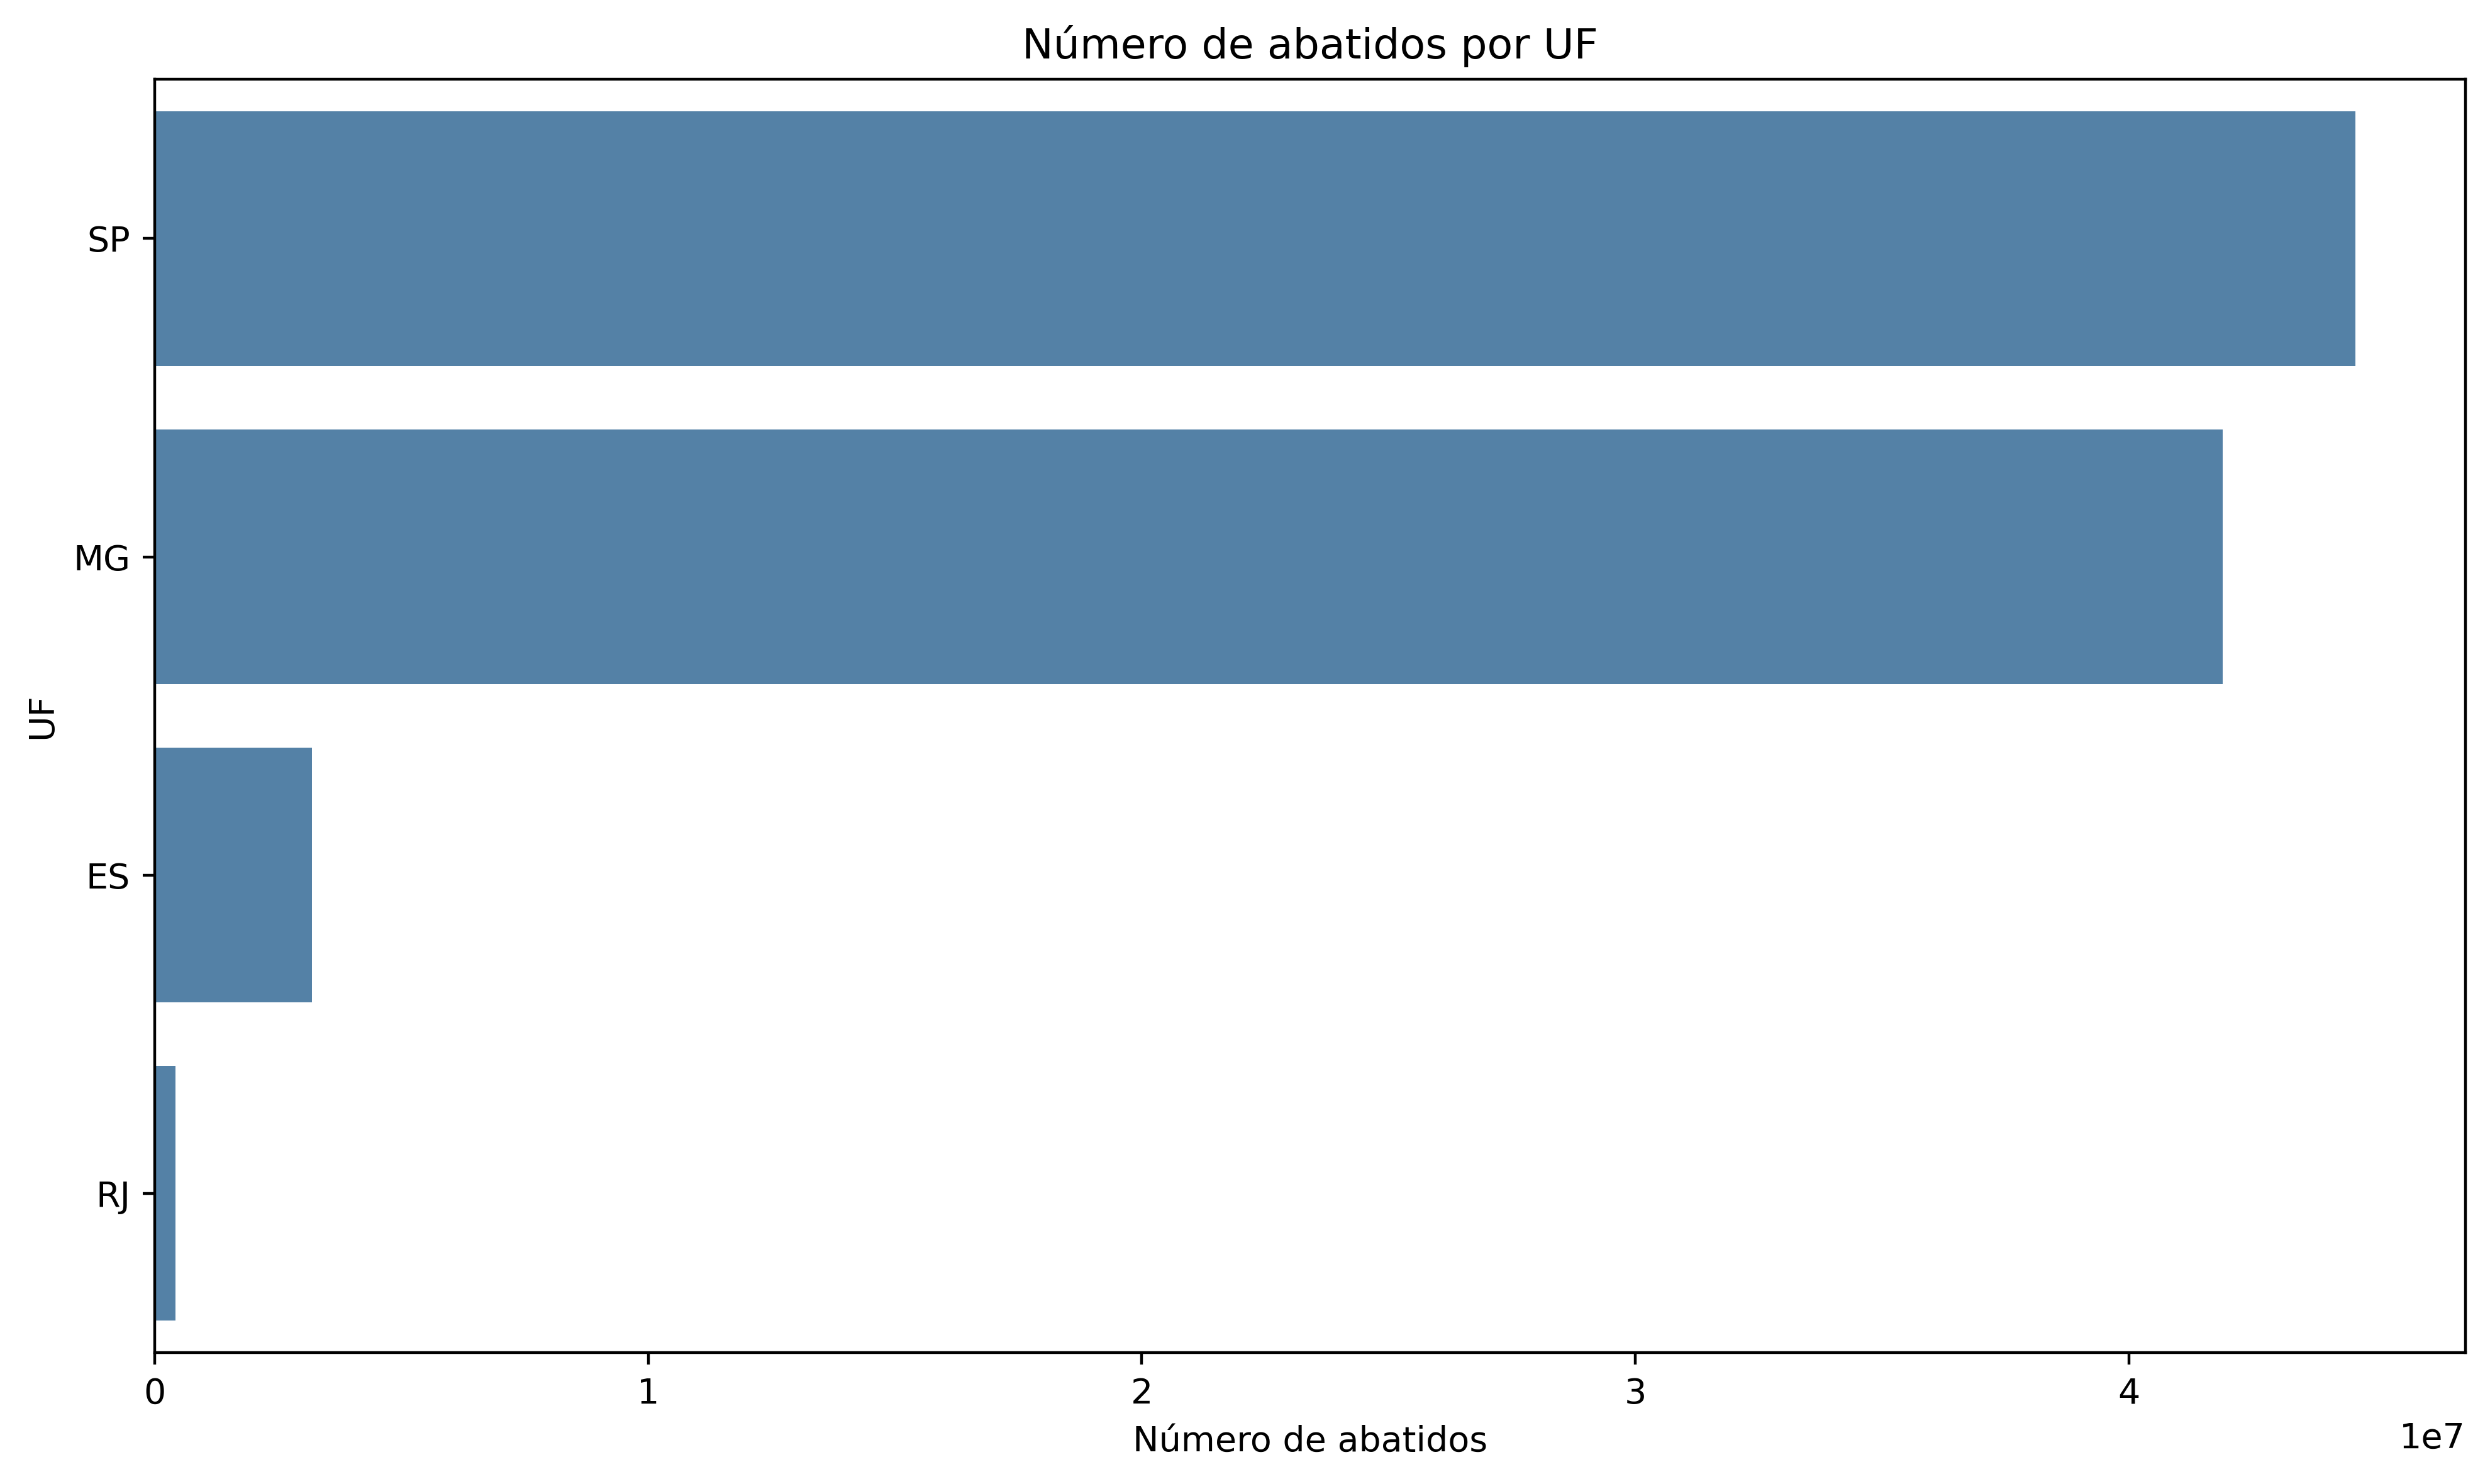

In [285]:
#realiza o ranking por estado de procedência
ranking_uf_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf_abate,
    x="QUANTIDADE",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de abatidos por UF")
pl.xlabel("Número de abatidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()


In [286]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_abate = pd.pivot_table(
    df_estat_bovino_abate_sudeste_bov,
    values="QUANTIDADE",
    index="UF_PROCEDENCIA",
    columns="CATEGORIA",
    aggfunc="sum",
    fill_value= 0
)

tabela_uf_abate

CATEGORIA,Bovino,Bovino Femea,Bovino Macho,Novilha Intermediaria,Novilha Precoce,Novilhao,Novilho Intermediario,Novilho Precoce,Novilhona,Vaca,Vitelo
UF_PROCEDENCIA,,,,,,,,,,,
ES,472095,688824,2018948,0,0,0,0,0,0,0,0
MG,11007443,8831097,19290925,31827,206435,60713,139993,1979308,1053,180775,170256
RJ,129273,116473,176654,20,0,33,0,0,0,234,9
SP,13343250,7869617,20599486,306546,101019,767025,637151,60375,411772,441880,52970


In [287]:
#Analisando o ranking por estado de procedência
ranking_uf_abate_tb = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)
        ["QUANTIDADE"].sum()
      .sort_values("QUANTIDADE", ascending=False)
)

ranking_uf_abate_tb


,UF_PROCEDENCIA,QUANTIDADE
3,SP,44591091
1,MG,41899825
0,ES,3179867
2,RJ,422696


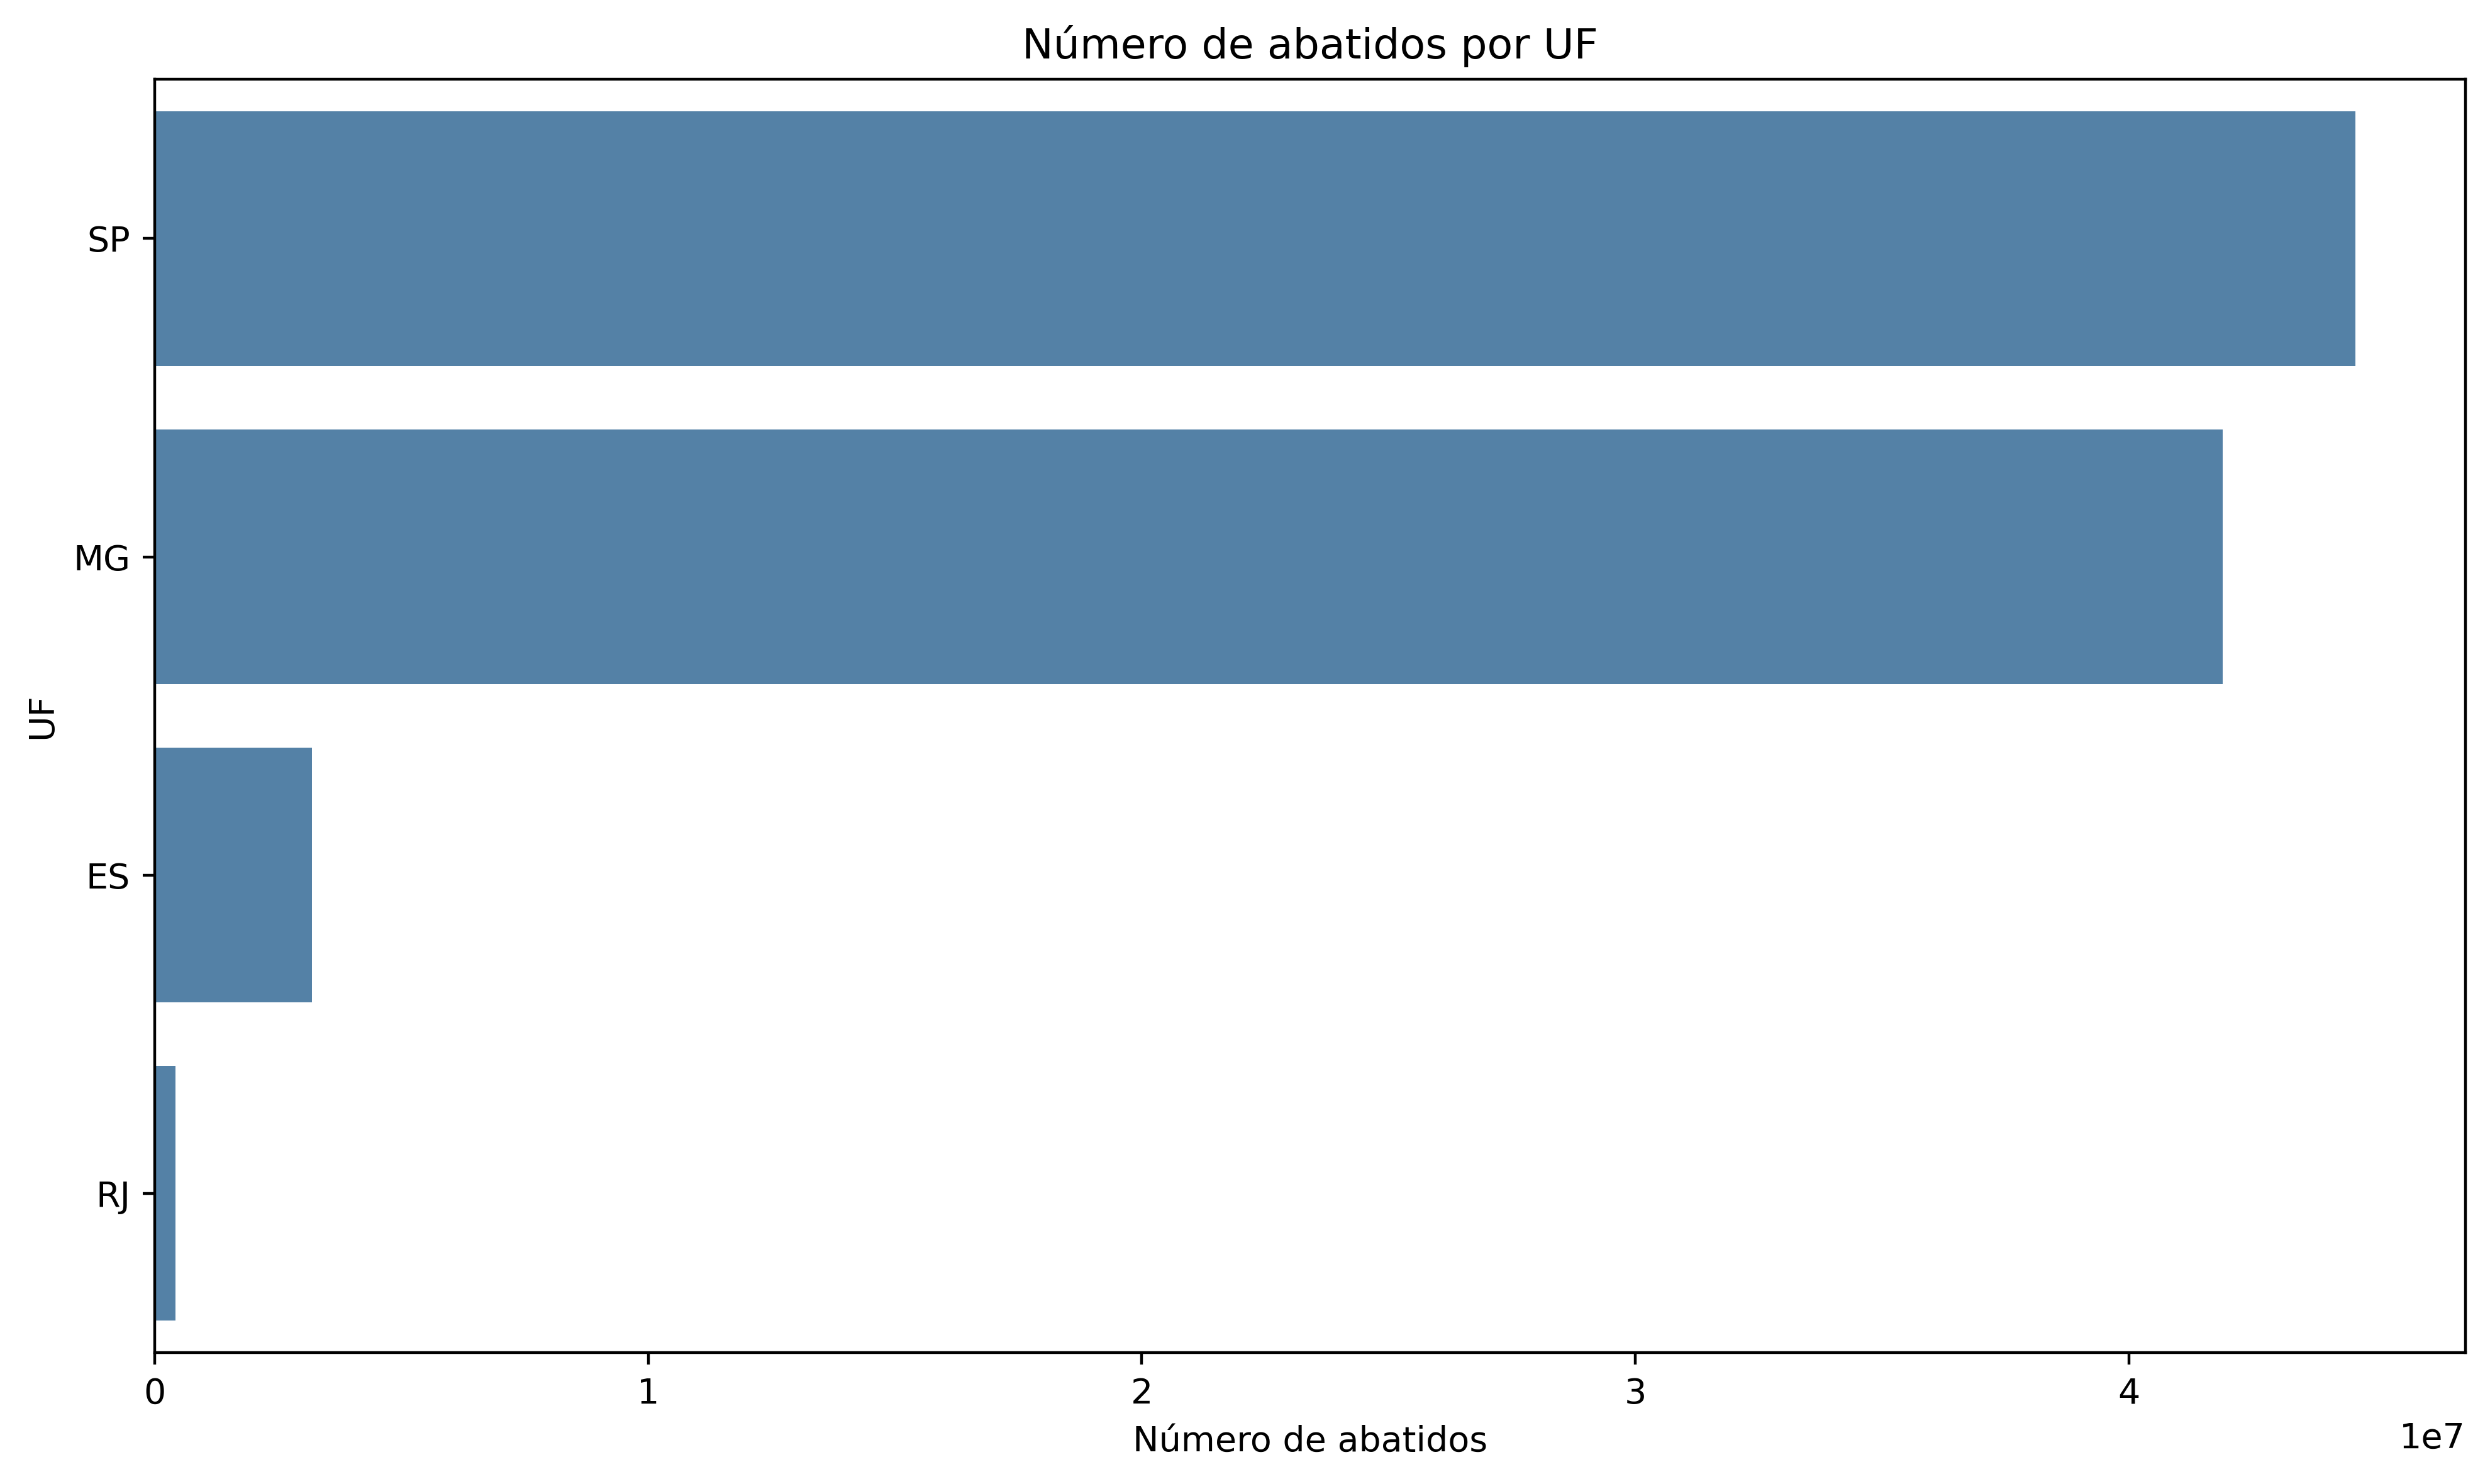

In [288]:
#Criando o gráfico de barras do número de abatidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf_abate_tb,
    x="QUANTIDADE",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de abatidos por UF")
pl.xlabel("Número de abatidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()


In [289]:
ranking_uf_abate_tb["percentual"] = (
    ranking_uf_abate_tb["QUANTIDADE"] /
    ranking_uf_abate_tb["QUANTIDADE"].sum() * 100
)

ranking_uf_abate_tb


,UF_PROCEDENCIA,QUANTIDADE,percentual
3,SP,44591091,49.494249
1,MG,41899825,46.507056
0,ES,3179867,3.529520
2,RJ,422696,0.469175


In [290]:
ranking_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("CATEGORIA", as_index=False)["QUANTIDADE"].sum().sort_values("QUANTIDADE", ascending=False)
)

ranking_abate
ranking_abate["percentual"] = (
    ranking_abate["QUANTIDADE"] /
    ranking_abate["QUANTIDADE"].sum() * 100
)

ranking_abate


,CATEGORIA,QUANTIDADE,percentual
2,Bovino Macho,42086013,46.713717
0,Bovino,24952061,27.695746
1,Bovino Femea,17506011,19.430941
7,Novilho Precoce,2039683,2.263963
5,Novilhao,827771,0.918791
6,Novilho Intermediario,777144,0.862597
9,Vaca,622889,0.691381
8,Novilhona,412825,0.458219
3,Novilha Intermediaria,338393,0.375602
4,Novilha Precoce,307454,0.341261


In [291]:
media = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].mean()
mediana = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].median()
desvio_padrao = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].std()
variancia = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")


Média: 197.26
Mediana: 57.00
Desvio Padrão: 577.53
Variância: 333545.23
Coeficiente de Variação: 292.77%


In [292]:
assimetria = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].skew()
curtose = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 11.35
Curtose: 249.02


In [293]:
minimo = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].min()
maximo = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].max()
amplitude = maximo - minimo

q1 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.25)
q3 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")


Valor mínimo: 0
Valor máximo: 43708
Amplitude: 43708
Q1: 20.0
Q3: 151.0
IQR: 131.0


In [294]:
q1 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.25)
q3 = df_estat_bovino_abate_sudeste_bov["QUANTIDADE"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_estat_bovino_abate_sudeste_bov[
    (df_estat_bovino_abate_sudeste_bov["QUANTIDADE"] < limite_inferior) |
    (df_estat_bovino_abate_sudeste_bov["QUANTIDADE"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")


Outliers encontrados:
         ANO  MES UF_PROCEDENCIA  MUNICIPIO_PROCEDENCIA     CATEGORIA ESPECIE  \
0       2025    8             MG               Araguari        Bovino  Bovino   
1       2025    9             MG  Monte Alegre de Minas        Bovino  Bovino   
2       2025    6             MG          Cascalho Rico        Bovino  Bovino   
3       2021    2             MG         Estrela do Sul        Bovino  Bovino   
4       2021    2             MG          Campina Verde        Bovino  Bovino   
...      ...  ...            ...                    ...           ...     ...   
517904  2020    4             SP           Itapetininga  Bovino Macho  Bovino   
517922  2020    5             MG              Ituiutaba  Bovino Macho  Bovino   
517928  2020    5             MG          Campina Verde  Bovino Femea  Bovino   
517933  2020    6             MG             Ponte Nova  Bovino Macho  Bovino   
517948  2020    7             SP                 Sabino  Bovino Macho  Bovino   

     

In [295]:
desc_por_uf_abate = (
      df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA")["QUANTIDADE"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf_abate

,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SP,203737,44591091,218.865945,63.0,632.995831,0,43708
MG,229271,41899825,182.752398,53.0,542.516894,0,19694
ES,17432,3179867,182.415500,52.0,408.687824,1,9991
RJ,6276,422696,67.351179,40.0,95.367374,0,3182


In [296]:
desc_por_categoria_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("CATEGORIA")["QUANTIDADE"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_categoria_abate


,count,sum,mean,median,std,min,max
CATEGORIA,,,,,,,
Bovino Macho,173781,42086013,242.178449,73.0,596.711814,0,19192
Bovino,58507,24952061,426.479925,100.0,1115.494651,1,43708
Bovino Femea,151994,17506011,115.175671,50.0,214.406762,0,8070
Novilho Precoce,9324,2039683,218.756221,50.0,677.310958,1,15870
Novilhao,15762,827771,52.516876,26.0,79.523773,1,1064
Novilho Intermediario,9029,777144,86.071990,36.0,167.808083,1,2963
Vaca,12647,622889,49.251917,25.0,81.155094,1,1797
Novilhona,9140,412825,45.166849,25.0,55.063312,1,1202
Novilha Intermediaria,7122,338393,47.513760,30.0,54.704837,1,791


In [297]:
ranking_uf_abate = (
    df_estat_bovino_abate_sudeste_bov.groupby("UF_PROCEDENCIA", as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

ranking_uf_abate["percentual"] = (
    ranking_uf_abate["QUANTIDADE"] /
    ranking_uf_abate["QUANTIDADE"].sum() * 100
)

ranking_uf_abate["percentual_acumulado"] = round(ranking_uf_abate["percentual"].cumsum(), 2)

ranking_uf_abate


,UF_PROCEDENCIA,QUANTIDADE,percentual,percentual_acumulado
3,SP,44591091,49.494249,49.49
1,MG,41899825,46.507056,96.00
0,ES,3179867,3.529520,99.53
2,RJ,422696,0.469175,100.00


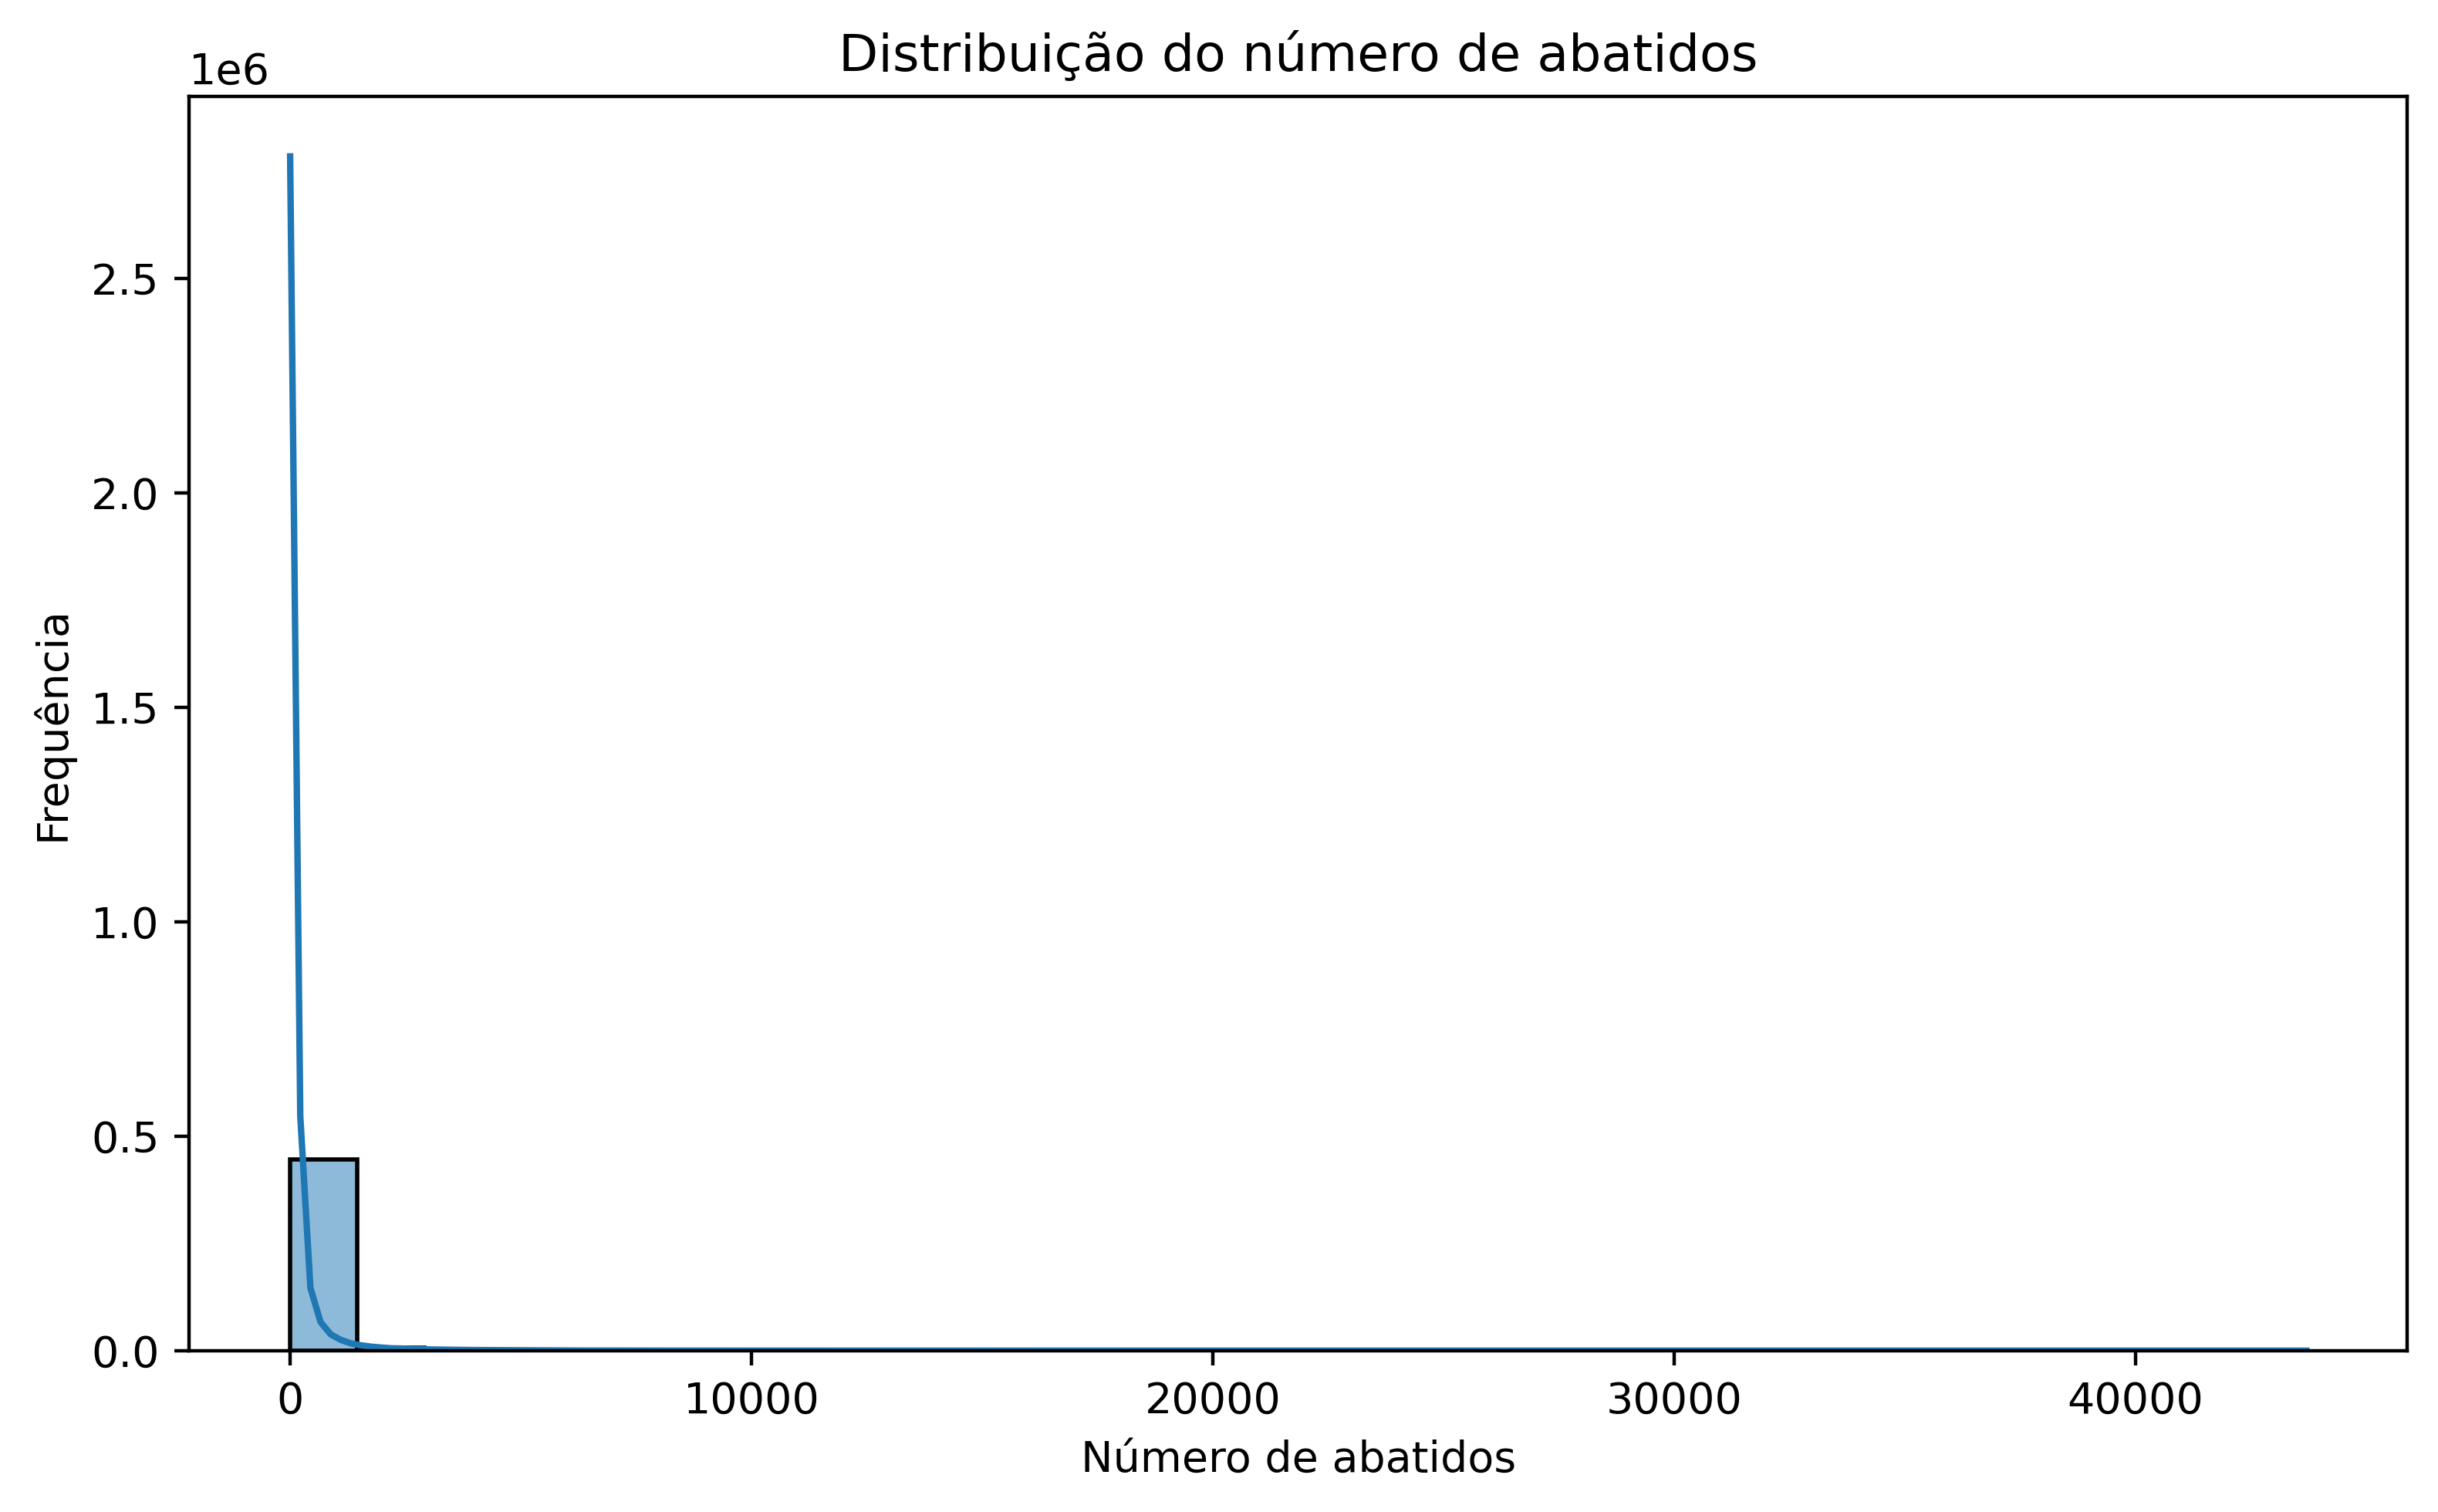

In [298]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_estat_bovino_abate_sudeste_bov,
    x="QUANTIDADE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


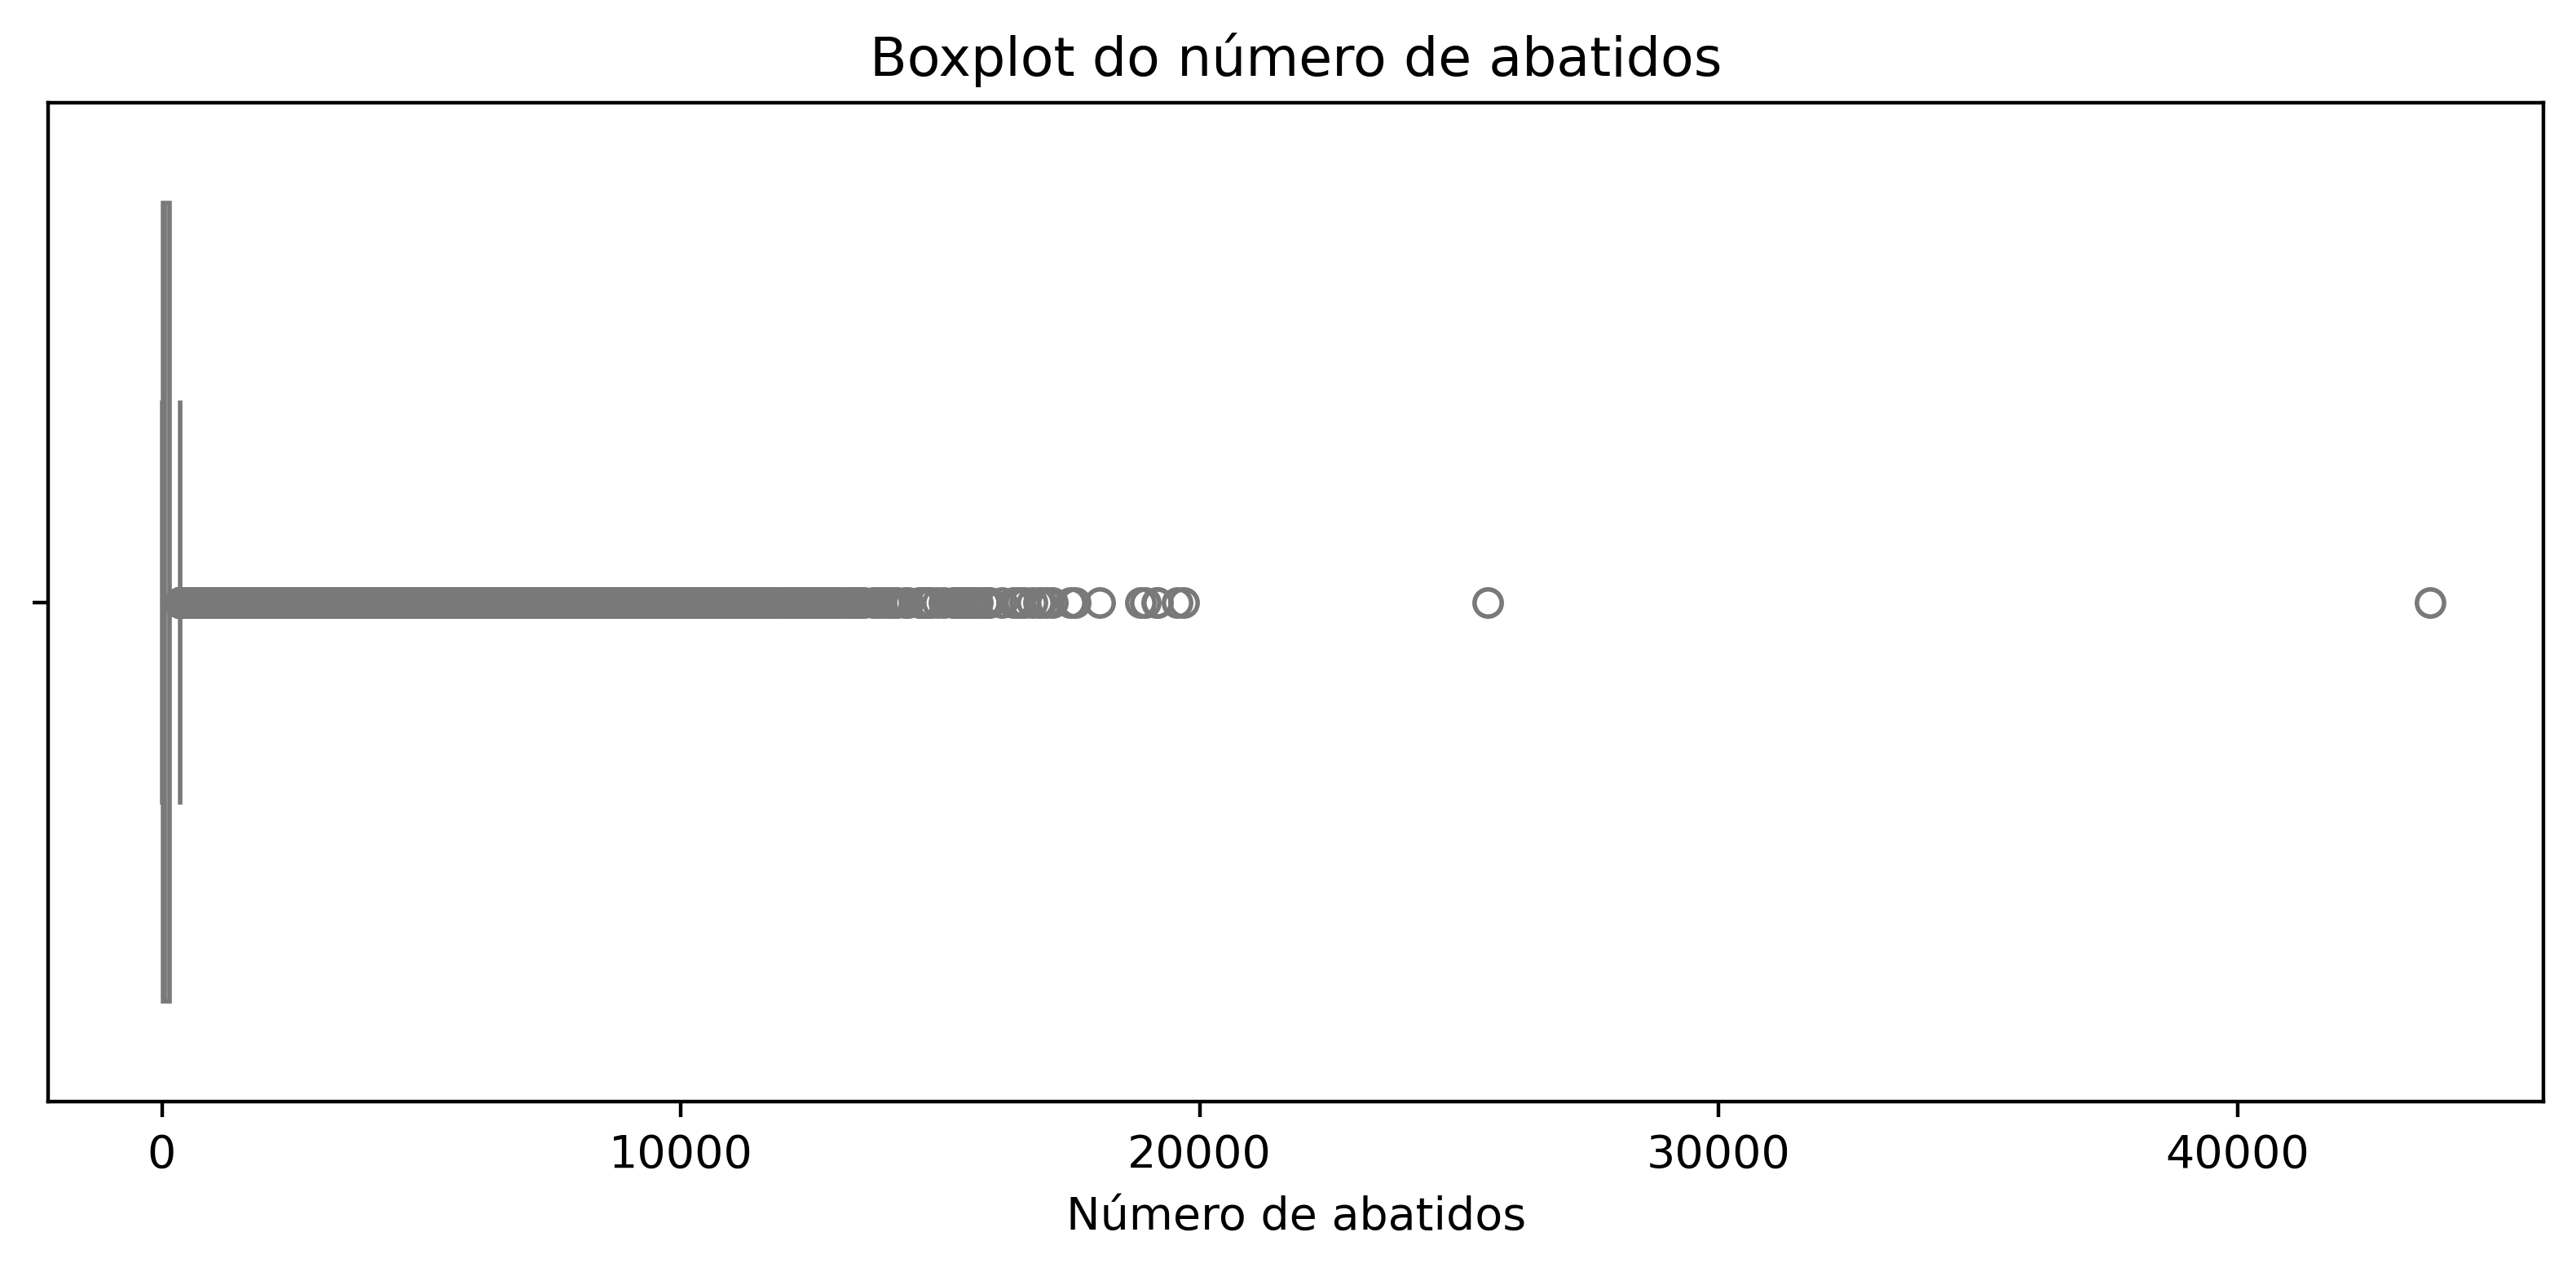

In [299]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_estat_bovino_abate_sudeste_bov,
    x="QUANTIDADE",
    color="lightblue"
)

pl.title("Boxplot do número de abatidos")
pl.xlabel("Número de abatidos")
pl.tight_layout()
pl.show()

<h2>Taxas de condenação/abate por estado</h2>

In [300]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste_ano.groupby(["UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
3,SP,44591091,4390649,9.85
1,MG,41899825,1552418,3.71
0,ES,3179867,111110,3.49
2,RJ,422696,32112,7.60


<h2>Taxas de condenação/abate por ano<h2>

In [301]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste_ano.groupby(["ANO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = (
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100
)

tabela_abatidocondenado = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado

,ANO,Abatidos,Condenados,Percentual Condenados
0,2006,4092818,136411,3.332936
1,2007,4713633,127447,2.703796
2,2008,4645047,118404,2.549038
3,2009,4066043,104655,2.573878
4,2010,4099399,114902,2.802899
5,2011,3656908,104144,2.847870
6,2012,3867125,102534,2.651427
7,2013,4618327,109984,2.381468
8,2014,4990477,122151,2.447682
9,2015,4381338,111208,2.538220


In [307]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste_ano.groupby(["ANO", "UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = (
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100
)

tabela_abatidocondenado = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado.head(105)
tabela_abatidocondenado.to_excel("tabela_abatidocondenado.xlsx", index=False)